# Detección de intrusiones en redes de drones con Deep Learning (UAVIDS-2025): MoE-ES y validación preregistrada

**Proyecto Final de Deep Learning, Entregable 3 · Modelo original MoE-ES (mezcla de expertos con escalones suaves), protocolo preregistrado, evaluación ampliada en tres conjuntos adicionales y despliegue en un dashboard**

| | |
|---|---|
| **Autor** | Donny Torres |
| **Programa** | Maestría en Analítica de Datos, Universidad del Norte (Barranquilla) |
| **Asignatura** | Deep Learning |
| **Fecha** | Noviembre de 2026 |
| **Conjunto de datos** | *UAVIDS-2025*, versión 1; Zenodo, licencia CC BY 4.0, DOI <https://doi.org/10.5281/zenodo.15336998> |
| **Preregistro** | `Entregable_3_UAVIDS_2025/experiments/protocolo.md`, etiqueta `e3-protocolo` del repositorio, congelado el 22/11/2026 |
| **Jupyter Book** | <https://dtl-da.github.io/proyecto-uavids-2025/entregable-3/> |
| **Dashboard** | <https://uavids-2025-dashboard.onrender.com> (plan gratuito de Render: la primera visita tras 15 minutos sin uso tarda cerca de un minuto) |
| **Repositorio** | <https://github.com/DTL-DA/proyecto-uavids-2025>, carpeta `Entregable_3_UAVIDS_2025/`, etiqueta `entregable-3` |
| **Archivo en Zenodo** | DOI <https://doi.org/10.5281/zenodo.24486475> (versión 1.0.0) |

Este cuaderno reúne, en el orden del libro, el texto y todo el código de la introducción y de los once capítulos del Jupyter Book, y se entrega ejecutado con todas las salidas: sus celdas de código corrieron en orden, sin errores, como lo muestran sus números de ejecución consecutivos, y las de preparación de cada capítulo terminan con una línea que imprime lo que dejaron definido. Se genera con `Entregable_3_UAVIDS_2025/book/crear_cuaderno.py` a partir de las mismas fuentes del libro, así que su contenido coincide con la versión publicada.

Las corridas costosas, que son las semillas de cada modelo, los conjuntos adicionales, la robustez y la exportación a ONNX, se precalculan con los scripts de `training/` y `experiments/`. Aquí, igual que al compilar el libro, se leen sus resultados versionados y se regeneran todas las tablas, pruebas y figuras. Para ejecutarlo de nuevo desde la raíz del repositorio basta con `python Entregable_3_UAVIDS_2025/book/crear_cuaderno.py`, o con *Run All* en Jupyter, en el entorno de `Entregable_3_UAVIDS_2025/requirements-train.txt`. Las citas aparecen como autor y año, y la lista de referencias está al final, en el capítulo 11.

In [1]:
# Los capítulos leen los resultados con rutas relativas a la carpeta del libro, como al compilarlo con Jupyter Book
import os
from datetime import datetime
from pathlib import Path

if Path("Entregable_3_UAVIDS_2025", "book").is_dir():
    os.chdir(Path("Entregable_3_UAVIDS_2025", "book"))
assert Path("_toc.yml").exists(), "Abre el cuaderno desde la raíz del repositorio"
print("Cuaderno ejecutado el", datetime.now().strftime("%d/%m/%Y a las %H:%M"))

Cuaderno ejecutado el 23/11/2026 a las 21:31


## Introducción

**Detección de intrusiones en redes de drones con Deep Learning (UAVIDS-2025): MoE-ES y validación preregistrada**

Proyecto Final de Deep Learning, Entregable 3 · Donny Torres · Maestría en Analítica de Datos, Universidad del Norte · Noviembre de 2026

### Resumen ejecutivo

Este entregable propone, implementa y valida un modelo original, **MoE-ES** (mezcla de expertos con escalones suaves), para detectar intrusiones en redes de drones con UAVIDS-2025: una compuerta que, flujo por flujo, combina un experto de escalones suaves con umbrales aprendibles y un experto neuronal suave, con entrenamiento cooperativo y una cota de Lipschitz demostrada. Se comparó con los 10 mejores modelos del Entregable 2, LightGBM y CNN 1D, con un protocolo preregistrado y el mismo presupuesto de ajuste, en la prueba sellada y en tres conjuntos adicionales.

Con 48 semillas, el original obtiene un F1 macro de 0,850 ± 0,012, frente a 0,875 de LightGBM y 0,859 de CNN-LSTM. Su media es menor que la de 8 de los 12 rivales y ningún contraste rechaza con tres pruebas, de modo que no cumple la condición de superioridad R3 y el tope de calificación es 4,0. Tampoco es el mejor en ningún conjunto adicional. Sí es el más robusto ante ruido (caída de 0,18 frente a 0,32 de LightGBM con σ = 0,5) y ante atributos faltantes.

El hallazgo principal es otro: en UAVIDS-2025 el escenario de simulación pesa más que la arquitectura. El 70,5 % de la prueba comparte escenario con el entrenamiento, ningún modelo reconoce un escenario no visto (acierto menor del 10 %) y la ventaja de LightGBM desaparece en la validación cruzada 5 × 2. Los 16 modelos se publican en un dashboard con ONNX y en este libro reproducible.

### Problema

Las redes de vehículos aéreos no tripulados (UAV) se comunican por enlaces inalámbricos ad hoc, sin infraestructura fija, y por eso son vulnerables a ataques de enrutamiento. UAVIDS-2025 registra flujos de red de una simulación con NS-3 en cinco clases: tráfico normal y los ataques Blackhole, Flooding, Sybil y Wormhole. La tarea es clasificar cada flujo a partir de 16 estadísticos de tráfico, con el F1 macro como métrica primaria, porque un ataque poco frecuente importa tanto como uno frecuente.

### Motivación

El Entregable 2 mostró que LightGBM, un modelo de árboles, supera a las 13 redes profundas evaluadas, y midió la confusión entre Blackhole y Wormhole que el paper guía señala como la principal del conjunto: LightGBM confunde esas dos clases en el 10,0 % de sus flujos y las redes del Top 10 entre el 12,3 y el 18,5 %. Los árboles parten cada atributo por umbrales, y ese sesgo parece útil para separar esas dos clases; las redes, en cambio, reconocen mejor Sybil. La pregunta de este entregable es si un mecanismo que combine los dos sesgos, flujo por flujo, puede superar a ambos.

### Contribuciones

1. **Un modelo original** (R1 y R2): una mezcla de dos expertos con compuerta por flujo, programada desde su formulación, con 14 pruebas unitarias y exportada a ONNX (capítulos 5 y 6).
2. **Una propiedad demostrada**: la cota de Lipschitz de la mezcla, con verificación numérica y su contraste empírico, que resultó holgado (P4 falsa, capítulos 5 y 8).
3. **Un *benchmark* preregistrado** de 13 modelos en el problema principal y en tres conjuntos adicionales, con potencia por contraste, Holm por familia, seis pruebas admisibles y la tabla maestra de corridas (capítulos 3, 7 y 8).
4. **La evidencia de que el escenario pesa más que la arquitectura** en UAVIDS-2025, con la auditoría de fuga, la prueba por escenario no visto y la validación cruzada 5 × 2 (capítulos 1, 7 y 8).
5. **Un dashboard desplegado** con los 16 modelos, incertidumbre calibrada, predicción conforme, detección de entradas fuera de dominio y explicaciones locales (capítulo 9).

### Objetivos

**General.** Diseñar, implementar y validar con rigor estadístico un modelo original de aprendizaje profundo para detectar intrusiones en redes de UAV, y determinar si supera al Top 10 y a los *baselines* fuertes del Entregable 2.

**Específicos.**

1. Corregir y auditar el Entregable 2, incluida la fuga de información entre particiones (capítulo 1).
2. Documentar la novedad del modelo frente a la literatura (capítulo 4).
3. Demostrar una propiedad formal del modelo y verificarla numéricamente (capítulo 5).
4. Comparar el modelo con la familia completa de contrastes bajo un protocolo preregistrado y en tres conjuntos adicionales (capítulos 7 y 8).
5. Desplegar los modelos en un dashboard reproducible y documentado (capítulos 9 y 11).

### Mapa del libro

| Capítulo | Contenido |
|---|---|
| 1. Trazabilidad de correcciones | Autoauditoría del E2, fuga de información, prueba de D3 y *ranking* antes y después |
| 2. Datos | EDA, auditoría, ficha de los datos y conjuntos adicionales |
| 3. Benchmarks | Top 10 y *baselines* fuertes, tabla maestra, exportación y prueba de ida y vuelta |
| 4. Literatura y novedad | Cadenas de búsqueda, matriz de novedad, trabajos más cercanos y declaración de novedad |
| 5. Modelo original: diseño | Limitación, hipótesis, formulación, pseudocódigo, demostración y bitácora |
| 6. Modelo original: implementación | Código, pruebas, complejidad, ablación e interpretabilidad |
| 7. Validación | Protocolo, potencia, contrastes, Friedman, pruebas admisibles y desviaciones |
| 8. Evaluación ampliada | Conjuntos adicionales, robustez, P4, adecuación, calibración, eficiencia y balance de R3 |
| 9. Dashboard | Arquitectura, despliegue, ficha del modelo y prueba de humo |
| 10. Conclusiones | Hallazgos, veredicto sobre R1 a R3, amenazas, limitaciones, riesgos y trabajo futuro |
| 11. Reproducibilidad | Entorno, semillas, lista de verificación, reproducción del autor, autoría y bibliografía |

### Dashboard

El dashboard se describe en el capítulo 9, donde está su URL pública.

## Capítulo 1. Correcciones del Entregable 2

El docente no hizo observaciones escritas al Entregable 2. Por tal motivo, este capítulo se construye con una autoauditoría del E2 frente a su propio enunciado y frente a los criterios del Bloque A de este entregable. Una observación sin fila en la tabla de trazabilidad se considera no corregida; si llegan observaciones del docente, se agregan como filas nuevas.

In [2]:
import json
from pathlib import Path
import pandas as pd
RAIZ = Path("..").resolve()
A = RAIZ / "experiments/bloque_a"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 400)
print("Preparación del capítulo 1 ejecutada. Quedan definidos: json, Path, pd, RAIZ, A")

Preparación del capítulo 1 ejecutada. Quedan definidos: json, Path, pd, RAIZ, A


### Tabla de trazabilidad

In [3]:
texto = (A / "trazabilidad.md").read_text(encoding="utf-8")
bloque = texto.split("## Tabla de trazabilidad")[1].split("## Ranking")[0].strip().splitlines()
filas = [[c.strip() for c in l.strip("|").split("|")] for l in bloque if l.startswith("|") and not l.startswith("|---")]
trazabilidad = pd.DataFrame(filas[1:], columns=filas[0]).set_index("N.°")
trazabilidad

,Observación (autoauditoría),Acción realizada,Ubicación en el Jupyter Book,Evidencia,Impacto en los resultados
N.°,,,,,
A1,"La partición por bloques de 1000 flujos se declaró en el E1 como aproximación de la serie. No se había verificado si los **escenarios de simulación** cruzan particiones (dependencia L3.2 de Kapoor y Narayanan, 2023)","Auditoría de fuga ampliada: bloques compartidos, duplicados, preprocesamiento, atributos ilegítimos y tramos de escenario que cruzan particiones; error según la vecindad en filas y en atributos; experimento natural con los escenarios de Sybil aislados","Cap. 1, sección ""Auditoría de fuga""",`bloque_a/auditoria_particion.py` y `auditoria_particion/*.csv`,"No hay fuga L1 ni L2 (0 bloques compartidos; identificadores excluidos). Sí hay dependencia L3.2: el 70,5 % de las filas de prueba pertenecen a un escenario con filas en entrenamiento. No se cambia la partición congelada, por comparabilidad entre E1, E2 y E3; la dependencia se reporta y se mide su efecto (A2)"
A2,Falta el **ranking antes y después** de controlar la dependencia,"F1 de los 15 modelos con y sin los segmentos de los dos escenarios de Sybil aislados, sobre las predicciones guardadas","Cap. 1, tabla ""Antes y después""",`auditoria_particion/f1_sin_escenarios_sybil.csv`,"**Prueba:** todos los modelos suben unos 0,04 y el orden se mantiene (LightGBM 0,875 → 0,915; CNN-LSTM 0,863 → 0,904). **Validación:** el orden cambia; LightGBM pasa de 0,887 a 0,936 y queda primero. La ventaja de las redes en validación se debía al escenario de 695 flujos. Cambio desfavorable para las redes, reportado sin ocultarlo"
A3,No se había medido si algún modelo **generaliza a un escenario no visto**,"Prueba con partición por escenario (9 pliegues, solo filas de entrenamiento) para el DNN, LightGBM y una penalización de invariancia (V-REx condicional por clase)",Cap. 1 y cap. 5 (motivación del diseño),`bloque_a/prueba_d3/`,"Ningún modelo generaliza: el Sybil nuevo se predice como Flooding (85 a 97 %) y el Wormhole nuevo como Blackhole (82 %). LightGBM no generaliza mejor que el DNN (0,401 frente a 0,475)"
A4,**Determinismo** y semillas documentados solo en el código,"Se documentan las semillas (Python, NumPy y PyTorch en `motor.fijar_semilla`), los hilos por proceso, la versión de PyTorch (2.6.0+cpu) y que todo corrió en CPU. Las corridas en GPU, si las hay, fijan `use_deterministic_algorithms` y se declaran",Cap. 11 (reproducibilidad),"`protocolo.md`, sección 5.1",Sin cambios en las cifras
A5,Los benchmarks no tenían un **hash de congelamiento**,SHA-256 del conjunto ordenado de las 301 corridas definitivas del E2 (JSON y probabilidades) fijado en el protocolo antes de las corridas del E3,Cap. 3,"`protocolo.md`, sección 5.1: `a35f8535…1f05f03`",Sin cambios; los rivales no se reajustan
A6,"En el E2 las probabilidades y los pesos por corrida quedaron fuera del repositorio, lo que impide la reproducción de las pruebas por instancia","Se copiaron a la copia de trabajo del E3, se verificó que los registros JSON coinciden (SHA-256 idéntico) y se publicarán en la *release* del E3 con DOI de Zenodo",Cap. 11,Hash de los JSON: `a0126570…41948f18` en ambas copias,Sin cambios
A7,La familia de contrastes del E2 (RQ1) era Top 10 frente al *baseline* del E1. El E3 exige el Top 10 **y todos los *baselines* fuertes**,"Familia de m = 12 (Top 10, LightGBM y CNN 1D), definida con las etiquetas del preregistro del E2 antes de ver resultados del E3",Cap. 7,`estandar.md`,"Más contrastes y semillas (48 para CNN-LSTM, 38 para TabNet)"
A8,El E2 corrió la cadena C4 solo en OpenAlex y arXiv,"La revisión de novedad del E3 se corre en OpenAlex, arXiv, Scopus y Web of Science, y la verifica un tercero",Cap. 4,`novedad/matriz_novedad.md`,—
A9,La limitación del paper guía (confusión Blackhole–Wormhole) quedó registrada en el E2 sin una propuesta que la atacara,"El modelo original se diseña contra esa limitación, con predicciones secundarias P1 a P3 preregistradas",Cap. 5,"`protocolo.md`,

### Auditoría de fuga de información

La auditoría reutiliza la batería del E2 y la amplía con la taxonomía de Kapoor y Narayanan (2023). Se corre en modo de solo lectura sobre las predicciones guardadas de las 20 semillas de los 15 modelos (`experiments/bloque_a/auditoria_particion.py`). El F1 recalculado coincide con el registrado en todas las corridas.

In [4]:
auditoria = json.loads((A / "auditoria_particion/auditoria_particion.json").read_text(encoding="utf-8"))
resumen = pd.DataFrame([
    ["L1 · bloques compartidos entre particiones", sum(auditoria["bloques_compartidos_entre_particiones"].values())],
    ["L1 · filas duplicadas excluidas antes de partir", auditoria["filas"]["fuera (repetidas)"]],
    ["L3.2 · tramos de escenario presentes en varias particiones", auditoria["tramos"]["tramos_en_varias_particiones"]],
    ["L3.2 · filas de prueba en un escenario con filas en entrenamiento (%)", auditoria["tramos"]["filas_prueba_en_tramo_compartido_con_entrenamiento_%"]],
    ["L3.2 · filas de validación en un escenario con filas en entrenamiento (%)", auditoria["tramos"]["filas_validacion_en_tramo_compartido_con_entrenamiento_%"]],
    ["Gemelos en atributos (< 0,01) entre prueba contigua y entrenamiento (%)", auditoria["vecino_atributos_prueba"]["gemelos_<0.01_contiguo_%"]],
], columns=["Verificación", "Valor"])
resumen

,Verificación,Valor
0,L1 · bloques compartidos entre particiones,0.00
1,L1 · filas duplicadas excluidas antes de partir,8219.00
2,L3.2 · tramos de escenario presentes en varias particiones,26.00
3,L3.2 · filas de prueba en un escenario con filas en entrenamiento (%),70.51
4,L3.2 · filas de validación en un escenario con filas en entrenamiento (%),67.35
5,"Gemelos en atributos (< 0,01) entre prueba contigua y entrenamiento (%)",1.80


**No hay fuga por separación (L1) ni por atributos ilegítimos (L2): ningún bloque se comparte entre particiones, los 8 219 duplicados exactos se excluyeron antes de partir y los identificadores (FlowID, IP, puertos y protocolo) no entran al modelo. Sí hay dependencia entre entrenamiento y prueba (L3.2): el 70,5 % de las filas de prueba pertenece a un escenario de simulación que también tiene filas en entrenamiento.**

Esto significa que la prueba mide sobre todo la generalización a segmentos nuevos de escenarios ya vistos, no a simulaciones nuevas. Sin embargo, la dependencia no se traduce en copias: solo el 1,8 % de las filas de prueba contiguas tiene un vecino de entrenamiento a menos de 0,01 en el espacio de atributos, y la cercanía en filas a un bloque de entrenamiento no baja el error de forma significativa en Blackhole, Normal, Flooding ni Wormhole.

En consecuencia, se decide conservar la partición congelada del E1, que es lo que permite comparar E1, E2 y E3, reportar la dependencia con esta cuantificación y medir su efecto en el ranking y en la generalización a escenarios nuevos, en lugar de rehacer la partición. Wormhole tiene solo dos escenarios, así que no se puede repartir por escenario en tres particiones.

### Ranking antes y después

El experimento natural son los dos escenarios de Sybil que quedaron aislados por azar: uno entero en validación y otro casi entero en prueba. Al quitarlos se obtiene el desempeño sobre escenarios ya vistos.

In [5]:
f = pd.read_csv(A / "auditoria_particion/f1_sin_escenarios_sybil.csv")
f["Posición antes (prueba)"] = f["F1 pru"].rank(ascending=False).astype(int)
f["Posición después (prueba)"] = f["F1 pru sin escenario"].rank(ascending=False).astype(int)
f["Posición antes (validación)"] = f["F1 val"].rank(ascending=False).astype(int)
f["Posición después (validación)"] = f["F1 val sin escenario"].rank(ascending=False).astype(int)
f = f.rename(columns={"F1 pru": "F1 prueba antes", "F1 pru sin escenario": "F1 prueba después", "F1 val": "F1 validación antes",
                      "F1 val sin escenario": "F1 validación después", "acierto escenario pru": "Acierto en el escenario aislado de prueba"})
f[["Modelo", "F1 prueba antes", "F1 prueba después", "Posición antes (prueba)", "Posición después (prueba)", "F1 validación antes",
   "F1 validación después", "Posición antes (validación)", "Posición después (validación)", "Acierto en el escenario aislado de prueba"]]

,Modelo,F1 prueba antes,F1 prueba después,Posición antes (prueba),Posición después (prueba),F1 validación antes,F1 validación después,Posición antes (validación),Posición después (validación),Acierto en el escenario aislado de prueba
0,LightGBM,0.875,0.915,1,1,0.887,0.936,15,1,0.075
1,CNN-LSTM,0.863,0.904,2,2,0.924,0.929,7,6,0.052
2,Autoencoder,0.859,0.900,3,3,0.928,0.928,5,7,0.083
3,CNN 1D,0.858,0.899,4,5,0.930,0.930,1,2,0.084
4,DNN,0.858,0.899,5,6,0.928,0.929,4,5,0.075
5,Transformer,0.858,0.899,6,4,0.922,0.924,9,9,0.061
6,DBN,0.857,0.897,7,7,0.929,0.929,3,4,0.079
7,ResNet,0.851,0.892,8,8,0.922,0.924,8,10,0.084
8,KAN,0.849,0.889,9,10,0.929,0.930,2,3,0.094
9,GRU,0.847,0.889,10,9,0.925,0.927,6,8,0.071


**En la prueba, todos los modelos suben unos 0,04 de F1 al quitar el escenario aislado y el orden casi no cambia: LightGBM sigue primero (de 0,875 a 0,915) y CNN-LSTM segunda (de 0,863 a 0,904). En validación el orden sí cambia: LightGBM pasa de 0,887 a 0,936 y queda primero.**

Lo anterior indica que la ventaja de las redes en validación se debía por completo al escenario de 695 flujos aislado en esa partición, y que en el escenario aislado de prueba ningún modelo acierta más del 10 % de los flujos (el máximo es KAN, con 9,4 %). El cambio es desfavorable para las redes y se reporta sin ocultarlo.

Por esta razón, el modelo original se diseña contra la limitación que sí se puede atacar con los datos disponibles, la confusión Blackhole–Wormhole en escenarios vistos, y la falta de generalización a escenarios nuevos se trata como una predicción secundaria (P5) y como un estudio de cambio de distribución en el capítulo 8.

### Generalización a un escenario no visto

La prueba de la opción de invariancia (capítulo 5) dejó, además, una medición de la línea de referencia: con 9 pliegues que dejan fuera un escenario completo de las filas de entrenamiento, el DNN acierta en promedio el 47,5 % de los flujos del escenario no visto y LightGBM el 40,1 %. El Sybil nuevo se predice casi siempre como Flooding y el Wormhole nuevo como Blackhole.

In [6]:
pd.read_csv(A / "prueba_d3/_acierto_por_pliegue.csv").set_index("pliegue")

,ERM,LightGBM,VREx_1,VREx_10,VREx_100
pliegue,,,,,
S1,0.148,0.143,0.055,0.007,0.249
S2,0.042,0.010,0.030,0.145,0.145
B1,0.367,0.389,0.372,0.368,0.371
B2,0.649,0.198,0.623,0.731,0.821
W1,0.056,0.061,0.052,0.052,0.037
W2,0.410,0.076,0.241,0.206,0.062
F2,0.929,0.948,0.914,0.897,0.892
F3,0.955,0.985,0.940,0.938,0.886
F4,0.720,0.800,0.660,0.610,0.526


### Determinismo y congelamiento de los benchmarks

Las semillas de Python, NumPy y PyTorch se fijan en cada corrida (`codigo/motor.fijar_semilla`); todo se entrenó en CPU con PyTorch 2.6.0, con 2 hilos por proceso. Los resultados de los benchmarks quedaron congelados el 22/11/2026, antes de cualquier corrida del E3, con el SHA-256 `a35f853544388d437ed9ba6755dec2ca2c77fe0a8b8b3b5be7fd3264d1f05f03` del conjunto ordenado de las 301 corridas definitivas del E2 (registros y probabilidades), fijado en `protocolo.md`. Desde ese punto no se reajustan; solo se agregaron las semillas que exigió el análisis de potencia, con los mismos hiperparámetros.

## Capítulo 2. Datos: EDA, auditoría y ficha de datos

In [7]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAIZ = Path("..").resolve()
df = pd.read_parquet(RAIZ / "data/uavids.parquet")
CLASES = ["Blackhole", "Flooding", "Normal", "Sybil", "Wormhole"]
COLOR = dict(zip(CLASES, ["#2A78D6", "#EDA100", "#8A94A6", "#1BAF7A", "#EB6834"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Preparación del capítulo 2 ejecutada. Quedan definidos: json, Path, np, pd, plt, RAIZ, df, CLASES, COLOR")

Preparación del capítulo 2 ejecutada. Quedan definidos: json, Path, np, pd, plt, RAIZ, df, CLASES, COLOR


### Ficha de datos

| Campo | Contenido |
|---|---|
| Fuente | UAVIDS-2025 (Zeng et al., 2025; Zeng et al., 2025), Zenodo, DOI 10.5281/zenodo.15336998 |
| Licencia | CC BY 4.0 |
| Periodo y generación | Simulación de enjambres de UAV en NS-3.24 con movilidad BOID, publicada en 2025 |
| Observaciones | 122 171 flujos; 8 219 duplicados exactos excluidos antes de partir |
| Variables | 16 estadísticos por flujo; FlowID, IP, puertos y protocolo se excluyen por ser identificadores |
| Objetivo y tarea | Clase del flujo (Blackhole, Flooding, Normal, Sybil y Wormhole): clasificación multiclase |
| Métrica primaria | F1 macro, con margen de relevancia δ = 0,01 heredado del E1 |
| Partición | Bloques de 1000 flujos: 73 267 de entrenamiento, 17 802 de validación y 22 883 de prueba, sellada en el E1 con SHA-256 |
| Sesgos conocidos | Escenarios de simulación largos y de una sola clase; dependencia L3.2 entre particiones (capítulo 1) |
| Usos inadecuados | Desplegar el modelo en una red real sin validarlo con tráfico real; tomar decisiones automáticas de aislamiento de nodos |

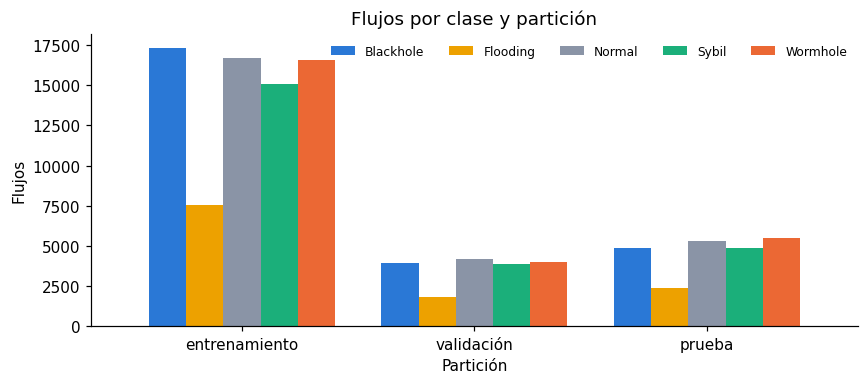

clase,Blackhole,Flooding,Normal,Sybil,Wormhole
particion,,,,,
entrenamiento,17342,7569,16698,15085,16573
validación,3929,1842,4176,3855,4000
prueba,4839,2365,5298,4868,5513


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
t = df[df["particion"] != "excluida (duplicada)"].groupby(["particion", "clase"]).size().unstack().reindex(columns=CLASES)
t = t.loc[["entrenamiento", "validación", "prueba"]]
t.plot(kind="bar", ax=ax, color=[COLOR[c] for c in CLASES], width=0.8)
ax.set_xlabel("Partición"); ax.set_ylabel("Flujos"); ax.set_title("Flujos por clase y partición"); ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper right")
plt.tight_layout(); plt.show()
t

**Las cinco clases tienen entre 7 569 (Flooding) y 17 342 (Blackhole) flujos en entrenamiento: un desbalance moderado, con Flooding como clase minoritaria en las tres particiones.**

Esto quiere decir que la exactitud global sobrestimaría el desempeño en Flooding, que es menos frecuente, mientras que el F1 macro da el mismo peso a cada clase.

Por tal motivo, se mantiene el F1 macro como métrica primaria y la pérdida ponderada por clase ($w_c = n / (K n_c)$) para todos los modelos, como en el E2.

### Estructura por escenario: el panel específico del problema

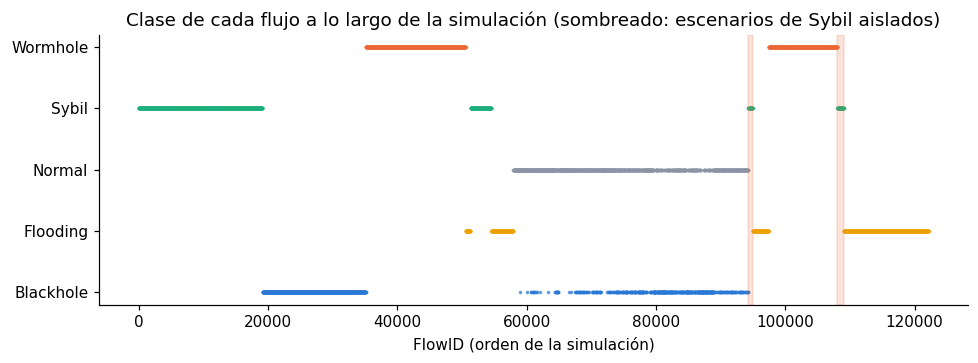

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.4))
m = df.iloc[::20]
for i, c in enumerate(CLASES):
    s = m[m["clase"] == c]
    ax.scatter(s["flow_id"], np.full(len(s), i), s=2, color=COLOR[c], alpha=0.6)
for a, b in ((94285, 94979), (108071, 109045)):
    ax.axvspan(a, b, color="#EB6834", alpha=0.18)
ax.set_yticks(range(5), CLASES); ax.set_xlabel("FlowID (orden de la simulación)"); ax.set_title("Clase de cada flujo a lo largo de la simulación (sombreado: escenarios de Sybil aislados)")
plt.tight_layout(); plt.show()

**La clase de cada flujo no se reparte al azar: forma tramos largos y contiguos, que son los escenarios de simulación (por ejemplo, Sybil de FlowID 1 a 19 000 y Wormhole de 36 001 a 49 000), y Blackhole y Normal aparecen intercaladas en una región de unos 36 000 flujos.**

En ese sentido, un bloque de 1000 flujos casi siempre contiene una sola clase y pertenece a un escenario que tiene otros bloques en entrenamiento. Por eso la partición por bloques evita mezclar vecinos inmediatos pero no aísla los escenarios, que es la dependencia L3.2 del capítulo 1.

De ahí que se reporte el desempeño con y sin los escenarios aislados, y que la generalización a un escenario nuevo se trate como un estudio de cambio de distribución y no como el resultado principal.

### Distribución de los atributos

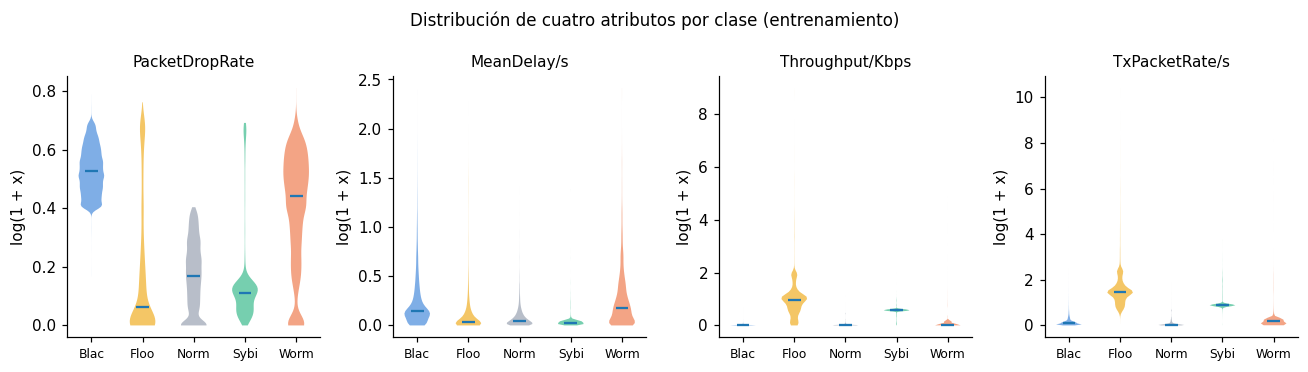

In [10]:
atributos = ["PacketDropRate", "MeanDelay/s", "Throughput/Kbps", "TxPacketRate/s"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
ent = df[df["particion"] == "entrenamiento"]
for ax, a in zip(axes, atributos):
    datos = [np.log1p(np.maximum(ent.loc[ent["clase"] == c, a], 0)) for c in CLASES]
    partes = ax.violinplot(datos, showmedians=True, showextrema=False)
    for cuerpo, c in zip(partes["bodies"], CLASES):
        cuerpo.set_facecolor(COLOR[c]); cuerpo.set_alpha(0.6)
    ax.set_xticks(range(1, 6), [c[:4] for c in CLASES], fontsize=8); ax.set_title(a, fontsize=10); ax.set_ylabel("log(1 + x)")
plt.suptitle("Distribución de cuatro atributos por clase (entrenamiento)", fontsize=11); plt.tight_layout(); plt.show()

**Flooding y Sybil se separan del resto por sus tasas: la mediana de TxPacketRate/s es 3,35 en Flooding y 1,43 en Sybil, frente a menos de 0,2 en las otras tres clases. La tasa de pérdida separa a Blackhole (mediana 0,69) y Wormhole (0,55) de Normal, Sybil y Flooding (por debajo de 0,2), pero no a esas dos clases entre sí: el rango intercuartílico de Wormhole (0,29 a 0,73) contiene casi todo el de Blackhole (0,59 a 0,80), y en MeanDelay/s ocurre lo mismo.**

Lo anterior indica que un umbral sobre un solo atributo distingue los ataques de saturación y de suplantación, pero no los dos ataques de enrutamiento. La frontera entre Blackhole y Wormhole depende de combinaciones de atributos, así que un modelo con umbrales por eje y uno de funciones suaves pueden equivocarse en flujos distintos.

Por ello, se diseña un modelo que combine los dos sesgos y no uno que solo afine un umbral.

### Conjuntos de datos adicionales

Los tres conjuntos adicionales se eligieron el 22/11/2026, antes de entrenar cualquier modelo con ellos, y no se usaron para diseñar. Su procedencia, licencia y SHA-256 están en `data/procedencia_conjuntos_adicionales.md`; la partición es agrupada por bloques de 250 filas contiguas dentro de cada clase, porque las fuentes vienen ordenadas por ejecución de ataque.

In [11]:
filas = []
for nombre, cita in (("uav_nidd", "Hadi et al. (2025)"), ("unsw_nb15", "Moustafa y Slay (2015)"), ("unr_idd", "Das et al. (2023)")):
    r = json.loads((RAIZ / f"data/{nombre}_resumen.json").read_text(encoding="utf-8"))
    filas.append({"Conjunto": nombre, "Fuente": cita, "Filas en la fuente": r["filas_fuente"], "Duplicadas eliminadas": r["duplicadas_eliminadas"],
                  "Clases": len(r["clases"]), "Atributos": r["n_atributos"],
                  "Entrenamiento / validación / prueba": " / ".join(str(sum(v)) for v in r["conteo_por_particion"].values()),
                  "Bloques compartidos": r["bloques_compartidos"]})
pd.DataFrame(filas)

,Conjunto,Fuente,Filas en la fuente,Duplicadas eliminadas,Clases,Atributos,Entrenamiento / validación / prueba,Bloques compartidos
0,uav_nidd,Hadi et al. (2025),149434,112628,6,43,24705 / 5808 / 5804,0
1,unsw_nb15,Moustafa y Slay (2015),2540047,516060,9,38,28000 / 6000 / 6000,0
2,unr_idd,Das et al. (2023),37411,27,6,18,26153 / 5615 / 5616,0


Los tres conjuntos difieren de UAVIDS-2025 en al menos dos ejes:

- **UAV-NIDD** (Hadi et al., 2025): proviene de un banco real con drones PX4 y DJI, tiene 43 atributos y otros tipos de ataque.
- **UNSW-NB15** (Moustafa y Slay, 2015): es tráfico de una red empresarial de laboratorio, tiene 2,5 millones de registros en la fuente y un desbalance fuerte.
- **UNR-IDD** (Das et al., 2023): usa estadísticos de puertos de una red definida por software en lugar de flujos, es más pequeño y tiene una clase del 2,7 %.

UAV-CAS (Mishra et al., 2026), la primera opción, se descartó porque IEEE DataPort exige una suscripción de pago para descargarlo, lo que impide la reproducción independiente.

## Capítulo 3. Benchmarks: Top 10, baselines y exportación

In [12]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
RAIZ = Path("..").resolve()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
lideres = pd.read_csv(RAIZ / "artifacts/dashboard/lideres.csv")
print("Preparación del capítulo 3 ejecutada. Quedan definidos: json, Path, pd, plt, RAIZ, lideres")

Preparación del capítulo 3 ejecutada. Quedan definidos: json, Path, pd, plt, RAIZ, lideres


### Criterio de selección de la mejor configuración

Para cada modelo del benchmark y cada *baseline* se usa la configuración elegida en el E2 por la **mayor F1 macro media de validación**, nunca por la prueba:

- **Modelos con hiperparámetros:** las 12 configuraciones de (lr, weight_decay, lote).
- **Modelos con búsqueda de arquitectura** (ResNet, Autoencoder, DBN y CNN-LSTM): la arquitectura ganadora de la fase 2, cuyo sesgo del ganador se reportó en el E2.
- **Modelo original:** las mismas 12 configuraciones, con la misma regla (capítulo 7).

Las configuraciones están congeladas con el SHA-256 del capítulo 1.

### Tabla maestra

La tabla maestra de experimentos (sección 12, entregable 8) es `experiments/resultados/tabla_maestra.csv`: una fila por corrida, con modelo, conjunto de datos, semilla, métricas de validación y prueba, épocas, tiempos y costo. Su resumen por modelo en el problema principal es la tabla de líderes:

In [13]:
cols = [c for c in ["Modelo", "Grupo", "Familia", "Semillas", "F1 macro", "DE", "IC95 inf", "IC95 sup", "ECE", "Parámetros", "FLOPs",
                    "Latencia mediana (ms)", "Latencia p95 (ms)", "Entrenamiento (s)"] if c in lideres]
lideres[cols]

,Modelo,Grupo,Familia,Semillas,F1 macro,DE,IC95 inf,IC95 sup,ECE,Parámetros,FLOPs,Latencia mediana (ms),Latencia p95 (ms),Entrenamiento (s)
0,LightGBM,Baseline fuerte,Árboles potenciados,20,0.8748,0.0012,0.8743,0.8753,0.0370,35516,NaN,0.1091,0.1448,14.4875
1,Autoencoder,Top 10,Codificador-decodificador,20,0.8591,0.0095,0.8551,0.8633,0.0431,19093,1.9072e+04,0.1177,0.2079,35.3220
2,CNN-LSTM,Top 10,Híbrida,48,0.8591,0.0186,0.8538,0.8641,0.0446,46213,9.2429e+05,0.1618,0.3085,215.1702
3,CNN 1D,Baseline del E1,Convolucional,20,0.8584,0.0050,0.8562,0.8606,0.0422,39493,2.6586e+05,0.1318,0.2094,118.0715
4,DNN,Base del E1,Perceptrón multicapa,20,0.8577,0.0084,0.8536,0.8608,0.0474,12677,2.4896e+04,0.0907,0.1465,40.9205
5,Transformer,Top 10,Atención,20,0.8576,0.0127,0.8521,0.8629,0.0433,3381,2.2144e+04,0.2089,0.3447,51.6170
6,DBN,Top 10,Generativa preentrenada,20,0.8569,0.0062,0.8542,0.8594,0.0498,9733,1.9072e+04,0.0797,0.1422,110.3980
7,ResNet,Top 10,Residual,20,0.8510,0.0126,0.8456,0.8565,0.0607,14245,2.6944e+04,0.1158,0.1575,48.7470
8,Original,Modelo original,Mezcla con compuerta,48,0.8496,0.0117,0.8462,0.8527,0.0463,14908,2.9056e+04,0.1851,0.3129,25.3060
9,KAN,Top 10,Kolmogorov-Arnold,20,0.8488,0.0124,0.8432,0.8539,0.0484,4845,9.3760e+03,0.1423,0.2386,96.3330


**LightGBM es el mejor modelo global (F1 macro de 0,875 ± 0,001 en 20 semillas), seguido de CNN-LSTM (0,859 ± 0,019 en 48 semillas) y de un grupo de redes entre 0,849 y 0,859. El modelo original queda en ese grupo (0,850 ± 0,012), por encima de KAN, GRU, BiLSTM, RNN, LSTM, TabNet y la regresión logística.**

Así mismo, la dispersión entre semillas de LightGBM es una décima de la de las redes, de modo que su ventaja no es un efecto de la semilla, y LightGBM tiene el mejor rango medio de la prueba de Friedman con los 13 modelos de la familia (capítulo 7).

Por esta razón, LightGBM es el *baseline* fuerte de referencia en el dashboard, y la tabla de líderes muestra todos los modelos con media ± DE e IC 95 %, no solo el ganador.

### Reentrenamiento final, exportación y prueba de ida y vuelta

**Política de reentrenamiento**, idéntica para todos los modelos, incluido el original:

- Cada corrida definitiva se entrenó sobre el conjunto de entrenamiento completo, con el número de épocas fijado en validación por la parada temprana.
- Se exporta la corrida cuya F1 de validación es la más cercana a la mediana de las 20 primeras semillas, lo que la hace representativa y la elige sin mirar la prueba.
- El *checkpoint* completo (pesos, configuración y curvas) queda en el registro de cada corrida.

**Exportación:**

- Las redes se exportan con `torch.onnx` (opset 17), LightGBM con `onnxmltools` y la regresión logística con `skl2onnx`.
- Cada modelo lleva su `metadata.json`, con versiones, semilla, hiperparámetros, preprocesamiento (transformación, medias y desviaciones), esquema de entrada con los rangos del entrenamiento, clases, métricas, temperatura y cuantil conforme.

In [14]:
rt = pd.read_csv(RAIZ / "artifacts/reporte_ida_y_vuelta.csv")
rt

,modelo,semilla,error_max_prob,misma_clase_%,f1_memoria,f1_onnx,dif_f1,kb,cumple_1e-4
0,DNN,6013,5.6624e-07,100.0,0.8606,0.8606,0.0,50.6,True
1,CNN 1D,6015,7.7486e-07,100.0,0.8610,0.8610,0.0,156.0,True
2,LSTM,6006,2.5034e-06,100.0,0.8590,0.8590,0.0,70.1,True
3,CNN-LSTM,6011,1.0729e-06,100.0,0.8726,0.8726,0.0,183.3,True
4,Autoencoder,6002,5.0664e-07,100.0,0.8690,0.8690,0.0,39.5,True
5,RNN,6016,1.7881e-06,100.0,0.8451,0.8451,0.0,153.9,True
6,Transformer,6006,3.2187e-06,100.0,0.8664,0.8664,0.0,26.2,True
7,BiLSTM,6005,1.5497e-06,100.0,0.8568,0.8568,0.0,2077.5,True
8,ResNet,6001,1.0729e-06,100.0,0.8469,0.8469,0.0,62.9,True
9,GRU,6001,3.2187e-06,100.0,0.8641,0.8641,0.0,384.6,True


**Las 14 redes (las 13 del E2 y el original) y la regresión logística reproducen en ONNX las probabilidades del modelo en memoria con un error absoluto máximo de entre 2 × 10⁻⁷ y 3 × 10⁻⁵, por debajo de la tolerancia declarada de 10⁻⁴, sobre los 22 883 flujos de la prueba. Las clases coinciden en el 100 % de los flujos y la diferencia de F1 macro es exactamente 0.**

Hay que tener en cuenta la excepción de LightGBM: su error máximo es 0,028, aunque solo 5 de los 22 883 flujos (0,02 %) superan 10⁻⁴. El conversor de ONNX guarda los umbrales de los árboles en precisión simple, así que un flujo que cae justo en un umbral puede tomar la otra rama. Aun así, las clases coinciden en el 100 % de los flujos y el F1 es idéntico.

En consecuencia, se declara para LightGBM una tolerancia de 10⁻⁴ en el 99,98 % de los flujos, con la métrica primaria sin cambio, y no se cuantiza ningún modelo: juntos ocupan unos 5 MB y caben en el plan gratuito de Render.

### Costo de inferencia

La latencia por flujo se midió en las mismas condiciones para todos los modelos: ONNX Runtime con un hilo, 300 flujos de prueba de a uno y 20 de calentamiento. Los parámetros y los FLOPs se cuentan con los mismos ganchos del E2. La frontera de Pareto entre desempeño y costo está en el capítulo 8.

## Capítulo 4. Revisión de literatura y evidencia de novedad

La revisión sistemática del Entregable 1, actualizada en el Entregable 2, sostiene el Top 10. En el E1 se exportaron 1 953 registros de OpenAlex, arXiv, IEEE Xplore, Scopus y Web of Science, y se incluyeron 42 estudios; en el E2 la actualización llevó el total a 43. Este capítulo se ocupa de otra pregunta, la que exige la condición R1: si el mecanismo del modelo original ya se usó para detectar intrusiones en redes de UAV y, en caso de que exista algo parecido, si la diferencia es de mecanismo o solo de aplicación (sección 6.3 del enunciado).

In [15]:
import json
from pathlib import Path
import pandas as pd
RAIZ = Path("..").resolve()
N = RAIZ / "experiments/novedad"
pd.set_option("display.max_colwidth", 300)
print("Preparación del capítulo 4 ejecutada. Quedan definidos: json, Path, pd, RAIZ, N")

Preparación del capítulo 4 ejecutada. Quedan definidos: json, Path, pd, RAIZ, N


### Cadenas de búsqueda

Se usaron siete cadenas, que combinan el mecanismo con el problema de aplicación, buscan el mecanismo en otras aplicaciones para ubicar su origen, buscan el origen de la propiedad demostrada e incluyen sinónimos en español. La primera consulta se hizo el 22/11/2026 en OpenAlex y arXiv, por programa (`experiments/novedad/buscar_novedad.py`). El 23/11/2026 se agregaron IEEE Xplore (N1) y la búsqueda por citación y en repositorios de código (`experiments/novedad/citacion_y_repositorios.py`). La búsqueda completa se repitió el 23/11/2026 con el mismo programa, y los conteos coinciden con los del 22/11 salvo OpenAlex N7, que pasa de 22 a 23 por BRIDGE (ICML 2025), una mezcla de expertos en un modelo fundacional de grafos que trata otro problema y no cambia la declaración.

In [16]:
resumen = sorted(p for p in N.glob("exportaciones/*_resumen_novedad.json") if p.name[:10].replace("-", "").isdigit() and p.name[10:] == "_resumen_novedad.json")[-1]
r = json.loads(resumen.read_text(encoding="utf-8"))
cadenas = pd.DataFrame([{"Clave": k, "Cadena": v} for k, v in r["cadenas"].items()])
conteos = pd.DataFrame(r["resultados"]).pivot(index="cadena", columns="fuente", values="total")
print("Fecha de la consulta:", r["fecha"])
cadenas.merge(conteos, left_on="Clave", right_index=True)

Fecha de la consulta: 2026-11-23


,Clave,Cadena,OpenAlex,arXiv
0,N1,"(""mixture of experts"" OR ""gating network"" OR ""gated fusion"" OR ""dynamic ensemble selection"") AND (""intrusion detection"" OR ""attack detection"") AND (UAV OR drone OR FANET OR ""unmanned aerial"")",3,0
1,N2,"(""mixture of experts"" OR ""gating network"") AND ""intrusion detection"" AND (""decision tree"" OR ""gradient boosting"" OR ""tree-based"" OR ""soft tree"")",0,1
2,N3,"(""piecewise linear encoding"" OR ""numerical embedding"" OR ""soft binning"" OR ""learnable threshold"" OR ""soft decision tree"" OR ""neural decision tree"") AND (""intrusion detection"" OR ""network traffic"")",3,1
3,N5,"(UAV OR drone OR FANET OR ""unmanned aerial"") AND ""intrusion detection"" AND (hybrid OR ensemble OR fusion) AND (""gradient boosting"" OR LightGBM OR XGBoost OR ""random forest"" OR ""decision tree"") AND (""neural network"" OR ""deep learning"")",13,1
4,N4,"(""mixture of experts"" OR ""gating network"") AND (""soft decision tree"" OR ""neural decision tree"" OR ""differentiable tree"" OR ""piecewise linear encoding"" OR ""numerical embeddings"") AND (tabular OR vision OR language OR ""time series"")",1,1
5,N7,"""Lipschitz"" AND (""mixture of experts"" OR ""gating network"")",23,13
6,N6,"(""mezcla de expertos"" OR ""red de compuerta"" OR fusión) AND (""detección de intrusiones"") AND (drones OR UAV OR ""vehículos aéreos no tripulados"")",0,0


### Matriz de novedad

In [17]:
texto = (N / "matriz_novedad.md").read_text(encoding="utf-8")
def tabla(seccion, siguiente):
    lineas = texto.split(seccion)[1].split(siguiente)[0].strip().splitlines()
    filas = [[c.strip() for c in l.strip("|").split("|")] for l in lineas if l.startswith("|") and not l.startswith("|---")]
    return pd.DataFrame(filas[1:], columns=filas[0])
tabla("## Matriz de novedad (cuadro 2 del enunciado)", "## Clasificación")

,Base,Cadena,Result.,Revis.,Relev.,Observación
0,OpenAlex,N1,3,3,1,SkyVehiGuard-Net (2026): Mamba + Transformer + mezcla dispersa de expertos para IoV en redes satelitales; no son flujos de UAV
1,OpenAlex,N2,0,0,0,Sin resultados
2,OpenAlex,N3,3,3,1,EDND (2026): ensamble de árboles de decisión neuronales para intrusiones en salud industrial; sin compuerta ni experto suave
3,OpenAlex,N4,1,1,1,"Autoencoders híbridos para tablas (2025): sesgo espectral de las redes frente a los árboles. Motivación compartida, otro mecanismo"
4,OpenAlex,N5,13,13,3,"(a) XAI y análisis estadístico en UAVIDS-2025 (CITS 2026): árboles, redes y *stacking* con validación cruzada estratificada; documenta el solapamiento Blackhole–Wormhole. (b) Ensambles explicables en redes de drones (2026). (c) Evaluación multiconjunto en UAV (IEEE IoT J., 2026)"
5,OpenAlex,N6,0,0,0,Sin resultados en español
6,OpenAlex,N7,22,22,2,"Puigcerver et al. (2022), robustez adversarial de la mezcla de expertos con argumento de Lipschitz; L2R (2026), enrutamiento con control de Lipschitz. Ninguno en intrusiones"
7,arXiv,N1,0,0,0,Sin resultados
8,arXiv,N2,1,1,1,"CNN + mezcla dispersa de expertos para intrusiones en 5G (arXiv 2412.03483, 2024)"
9,arXiv,N3 a N5,3,3,0,Duplicados de OpenAlex


### Trabajos más cercanos y clasificación de la diferencia

In [18]:
tabla("## Clasificación de la diferencia frente a cada trabajo cercano", "## Búsqueda por citación")

,Trabajo cercano,Qué hace,Diferencia con la propuesta,Categoría
0,"Fuente: Jacobs et al. (1991), mezcla de expertos",Expertos homogéneos con compuerta; entrenamiento conjunto,"Expertos de **sesgo inductivo distinto** (escalones suaves frente a suave), **entrenamiento cooperativo** con gradiente detenido, mezcla de probabilidades con **cota de Lipschitz**",Mecanismo y entrenamiento
1,"Fuente: Gorishniy et al. (2022), codificación de atributos numéricos",Codificación por tramos lineales con cortes fijos,"**Escalones sigmoides** con umbrales y temperaturas **aprendibles**, y τ ≥ τ_min para acotar la pendiente",Mecanismo
2,CNN + MoE para intrusiones en 5G (2024),"Expertos densos homogéneos sobre una representación CNN, enrutamiento disperso, entrenamiento conjunto; 5G-NIDD","Expertos heterogéneos, compuerta densa sobre el flujo, entrenamiento cooperativo, cota demostrada; flujos de UAV",Mecanismo y entrenamiento
3,SkyVehiGuard-Net (2026),Mamba + Transformer + MoE disperso + destilación; IoV,Otra arquitectura y otro problema,Mecanismo
4,"XAI en UAVIDS-2025, de árboles a híbridos (2026)","Compara árboles, redes y *stacking* (regla estándar)","Compuerta **por flujo** aprendida, con un experto neuronal de umbrales en lugar de un árbol externo; el *stacking* es una de nuestras reglas de comparación",Mecanismo
5,EDND en salud industrial (2026),Ensamble de árboles de decisión neuronales,Sin compuerta entre sesgos ni experto suave; otro problema,Mecanismo
6,"**PS-CAHE (Ma et al., 2026), sobre UAVIDS-2025**","Ensamble heterogéneo (XGBoost y otros) con atributos semánticos de protocolo y dos pesos de fusión elegidos fuera de muestra para los pares de clases que se confunden; F1 macro de 95,6 % en una partición por filas, y sin ventaja en una evaluación con nodos disjuntos","Compuerta **aprendida por flujo** entre un experto neuronal de escalones suaves y uno suave, entrenada de forma cooperativa y con cota de Lipschitz; PS-CAHE fija pesos por par de clases sobre modelos externos. Misma motivación (los pares que se confunden), otro mecanismo",Mecanismo y entrenamiento
7,"Switch IDS (Wang et al., 2025)","Mezcla de expertos homogéneos en un IDS por paquete para borde asistido por aeronaves, con pérdida de reparto entre nodos","La compuerta de la propuesta combina sesgos inductivos distintos para mejorar la clasificación, no para repartir carga; flujos de UAV",Mecanismo y entrenamiento
8,"Fusión XGBoost–MLP para 5G (Al-Balasmeh, 2026)",Fusión de probabilidades de un árbol y un MLP con un peso global elegido en validación,"Peso **por flujo** aprendido por una compuerta, con el sesgo de umbral dentro de la red (escalones suaves) en lugar de un árbol externo",Mecanismo
9,"VG-MoE (AL-Essa et al., 2026)",Compuerta ajustada sobre predicciones fuera de muestra de expertos ya entrenados; NSL-KDD y CICIDS17,"Entrenamiento cooperativo de extremo a extremo con gradiente detenido, expertos de sesgo distinto, cota de Lipschitz; flujos de UAV",Entrenamiento y mecanismo


**Las siete cadenas devuelven pocos registros: para la mezcla de expertos aplicada a intrusiones en UAV (N1), 3 en OpenAlex, 2 en IEEE Xplore, 4 en Scopus, 1 en Web of Science y ninguno en arXiv ni en español; para los híbridos de árboles y redes en UAV (N5), 13 en OpenAlex, 28 en Scopus, de los cuales 18 son actas de congreso, y 3 en Web of Science. La búsqueda por citación sobre 56 obras que citan a los trabajos más cercanos, los 27 repositorios de código revisados y las cadenas N1, N2 y N5 en Scopus agregan siete trabajos cercanos, y Web of Science solo devuelve trabajos ya encontrados; ninguno combina un experto de escalones suaves con uno suave mediante una compuerta aprendida por flujo.**

Así mismo, el trabajo más cercano en el problema, el estudio de UAVIDS-2025 de Zarkadis y Douligeris (2026), compara árboles, redes y *stacking*, que es una regla de fusión estándar y una de las reglas contra las que se contrasta la compuerta propia, y llega por otro camino a la misma limitación: Blackhole y Wormhole comparten el soporte de su distribución. El trabajo más cercano en la motivación es PS-CAHE (Ma et al., 2026), que sobre UAVIDS-2025 fija pesos de fusión para los pares de clases que se confunden; lo hace con pesos por par de clases sobre modelos externos, no con una compuerta aprendida por flujo, y su ventaja desaparece con nodos disjuntos. El más cercano en el mecanismo es ACGE (Abdelnaby, 2026), que en redes fog-IoT pondera por muestra un LightGBM y un Transformer con una regresión logística sobre cuatro rasgos de confianza del LightGBM, ajustada en validación después de entrenar los dos modelos; el mismo autor la presenta como una adaptación del *stacking* y de la mezcla de expertos, no como un mecanismo nuevo. Sin embargo, su experto de umbrales es un árbol externo, que no se entrena por gradiente y es discontinuo, mientras que la propuesta lleva el sesgo de umbral dentro de la red con escalones suaves, su compuerta ve el flujo, se entrena con los expertos bajo el esquema cooperativo y la pendiente de la mezcla queda acotada. Le siguen las mezclas de expertos homogéneos: para intrusiones en 5G (arXiv 2412.03483), con enrutamiento disperso, y en Switch IDS (Wang et al., 2025), para repartir el tráfico entre nodos de borde asistidos por aeronaves. La fusión de XGBoost y un MLP con un peso global (Al-Balasmeh, 2026), la compuerta ajustada fuera de muestra (AL-Essa et al., 2026) y la mezcla de un experto por conjunto de datos con *stacking* de U-Flow MoE-IDS (Bhaskaran et al., 2026) completan el grupo. En todos los casos la diferencia es de mecanismo o de esquema de entrenamiento, que son las dos categorías que sustentan R1.

Por lo anterior, conviene declarar la novedad en los términos de la sección siguiente, con OpenAlex, IEEE Xplore y arXiv como las tres bases de la sección 6.3 del enunciado y Scopus y Web of Science como confirmación.

### Declaración de novedad

Al mejor de nuestro conocimiento y según la búsqueda descrita, no se encontraron estudios que apliquen a la detección de intrusiones en redes de UAV una compuerta por flujo entre un experto de escalones suaves con umbrales aprendibles y un experto neuronal suave, entrenada con un esquema cooperativo y con cota de Lipschitz demostrada.

Los trabajos más cercanos, y la diferencia de cada uno con la propuesta, son:

- **PS-CAHE sobre UAVIDS-2025** (Ma et al., 2026): comparte la motivación, que son los pares de clases que se confunden, pero fija pesos de fusión por par sobre modelos externos; la propuesta aprende una compuerta por flujo entre dos expertos internos de sesgo distinto, con entrenamiento cooperativo.
- **ACGE en fog-IoT** (Abdelnaby, 2026): es el más cercano en el mecanismo, porque pondera por muestra un árbol (LightGBM) y un Transformer con una compuerta aprendida; la propuesta reemplaza el árbol externo por un experto neuronal de escalones suaves, lo que permite entrenar la compuerta y los expertos de forma cooperativa y demostrar una cota de Lipschitz para la mezcla, que con un árbol discontinuo no existe.
- **Switch IDS** (Wang et al., 2025) **y la mezcla de expertos para intrusiones en 5G:** usan expertos homogéneos; la propuesta difiere en el mecanismo y en el esquema de entrenamiento.
- **El estudio de *stacking* sobre UAVIDS-2025** (Zarkadis y Douligeris, 2026): difiere en el mecanismo, porque la propuesta reemplaza una regla de fusión estándar por una compuerta aprendida por flujo.
- **Las fuentes de las piezas** (Jacobs et al., 1991; Gorishniy et al., 2022): las cuatro modificaciones algorítmicas están en `experiments/procedencia.md`.

### Verificación por un tercero

Los profesores del curso indicaron el 23/11/2026 que esta verificación queda a su cargo, por lo que se omite en el informe. Para facilitarla, las cadenas exactas están en `experiments/novedad/buscar_novedad.py` (OpenAlex y arXiv) y en `experiments/novedad/cadenas_scopus_wos.md` (Scopus, Web of Science y los enlaces directos de OpenAlex para N1 y N5), y los conteos de cada consulta, con su fecha, en `experiments/novedad/exportaciones/`.

## Capítulo 5. Modelo original (MoE-ES): limitación, fuente, hipótesis, teoría y diseño

Este capítulo explica por qué se propone el modelo, de dónde viene su mecanismo, qué hipótesis pone a prueba, qué propiedad se demuestra y cómo se tomaron las decisiones de diseño sin tocar los datos de confirmación.

In [19]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, str(RAIZ / "training"))
pd.set_option("display.precision", 4)
print("Preparación del capítulo 5 ejecutada. Quedan definidos: json, sys, Path, np, pd, RAIZ")

Preparación del capítulo 5 ejecutada. Quedan definidos: json, sys, Path, np, pd, RAIZ


### Limitación identificada con evidencia

El paper guía (Zeng et al., 2025) reporta que Blackhole y Wormhole son las clases que más se confunden en UAVIDS-2025, y Zarkadis y Douligeris (2026) atribuyen esa confusión a que las dos clases comparten el soporte de su distribución en casi todos los atributos. En el Entregable 2 esa limitación quedó medida con el benchmark completo: en la prueba sellada, LightGBM confunde Blackhole con Wormhole en el 10,0 % de esos flujos y las redes del Top 10 entre el 12,3 y el 18,5 %, mientras que las redes reconocen mejor Sybil (F1 de hasta 0,864 frente a 0,834 de LightGBM). Es decir, los errores del sesgo de árbol, que parte el espacio con umbrales por eje, y los del sesgo neuronal, que ajusta funciones suaves, son **complementarios**, y una regla de fusión fija le da el mismo peso a cada modelo en todos los flujos.

La cuantificación se hizo en la partición de desarrollo, que solo usa filas de entrenamiento del E2 (sección 7.2 del enunciado):

In [20]:
d01 = pd.read_csv(RAIZ / "experiments/diseno/resultados/d01/resumen.csv")
d01 = d01.rename(columns={"modelo": "Modelo", "f1_medio": "F1 macro medio", "f1_de": "DE", "conf_BW": "Confusión B–W", "desacuerdo": "Flujos en desacuerdo (%)"})
d01

,Modelo,F1 macro medio,DE,Confusión B–W,Flujos en desacuerdo (%)
0,CNN-LSTM,0.8415,0.0415,0.1226,NaN
1,DNN,0.8369,0.0460,0.1263,NaN
2,LightGBM,0.8453,0.0631,0.1036,NaN
3,Transformer,0.8316,0.0404,0.1303,NaN
4,Promedio LightGBM+DNN,0.8485,0.0569,0.1108,NaN
5,Oráculo LightGBM|DNN,0.8710,0.0527,0.0898,5.8175
6,Promedio LightGBM+Transformer,0.8416,0.0529,0.1199,NaN
7,Oráculo LightGBM|Transformer,0.8647,0.0519,0.0909,5.5399
8,Promedio LightGBM+CNN-LSTM,0.8482,0.0528,0.1139,NaN
9,Oráculo LightGBM|CNN-LSTM,0.8675,0.0526,0.0888,4.9434


**El oráculo que elige flujo por flujo entre LightGBM y el DNN llega a un F1 macro de 0,871, frente a 0,845 de LightGBM solo, aunque los dos modelos discrepan en apenas el 5,8 % de los flujos.** El promedio simple de probabilidades se queda en 0,849.

Esto significa que hay un margen de +0,026 que ninguna regla fija aprovecha, y que está concentrado en pocos flujos. Al revisar quién acierta cuando discrepan, la red acierta en Sybil y LightGBM en las demás clases; elegir por máxima confianza no aporta (0,848), pero una regla que confía en la red solo cuando predice Sybil sube a 0,856.

Por tal motivo, se opta por un mecanismo que decida **por flujo** cuánto pesa cada sesgo inductivo, en lugar de una regla global.

### Fuente del mecanismo y transferencia

El mecanismo es propio, con tres piezas tomadas de otras aplicaciones y reimplementadas desde su formulación (`experiments/procedencia.md`):

- la mezcla de expertos con red de compuerta de Jacobs et al. (1991), propuesta para reconocimiento de vocales y patrones;
- la codificación de atributos numéricos de Gorishniy et al. (2022), que le da a un MLP parte del sesgo de umbral de los árboles en datos tabulares generales;
- la regularización de balance de la compuerta de Shazeer et al. (2017), propuesta para modelos de lenguaje.

La propiedad estructural compartida es que la frontera entre clases en UAVIDS-2025 tiene partes alineadas con los ejes (umbrales en pérdida, retardo y tasa) y partes suaves (combinaciones de atributos), que es justo la situación en la que Grinsztajn et al. (2022) muestran que los árboles y las redes fallan de formas distintas. Las modificaciones algorítmicas son cuatro: escalones sigmoides con umbrales y temperaturas aprendibles con temperatura mínima, entrenamiento cooperativo en lugar del conjunto, mezcla de probabilidades en lugar de logits y un regularizador KL de balance para dos expertos densos.

### Hipótesis del mecanismo

La hipótesis, preregistrada en `protocolo.md`, es causal y falsable: **el codificador de escalones suaves da al modelo el sesgo de umbral por eje de los árboles y reduce la confusión Blackhole–Wormhole frente a las redes de sesgo suave, y la compuerta lo combina flujo por flujo con un experto suave que reconoce mejor Sybil; por tanto, el F1 macro del modelo supera al de la mejor red del Top 10 en al menos δ = 0,01, con la ventaja concentrada en Blackhole y Wormhole.**

Las predicciones secundarias declaradas a priori son cinco:

- **P1.** Sin el codificador, la confusión Blackhole–Wormhole sube.
- **P2.** La compuerta pesa más el experto de umbrales en los flujos Blackhole y Wormhole que en los Sybil.
- **P3.** La ventaja frente a la mejor red se concentra en esas dos clases.
- **P4.** La variante con menor cota de Lipschitz se degrada menos ante ruido.
- **P5.** El modelo tampoco generaliza a un escenario de simulación no visto.

### Formulación

El modelo original se llama **MoE-ES**, por mezcla de expertos con escalones suaves; en el código es `ModeloOriginal` y en las tablas, "Original". Sea $x \in \mathbb{R}^{d}$ el flujo transformado con $\log(1+x)$ y estandarizado ($d = 16$), y $K_c = 5$ el número de clases. El **experto de umbrales** codifica cada atributo con $T$ escalones suaves:

$$
s_{j,t}(x) = \sigma\!\left(\frac{x_j - \theta_{j,t}}{\tau_j}\right), \qquad \tau_j = \tau_{\min} + \operatorname{softplus}(\rho_j), \qquad t = 1,\dots,T,
$$

donde los umbrales $\theta_{j,t}$ se inicializan en los cuantiles del entrenamiento y se aprenden, y la temperatura nunca baja de $\tau_{\min}$. Con $s(x) \in \mathbb{R}^{dT}$, los dos expertos y la compuerta son

$$
p_u(x) = \operatorname{softmax}\big(\mathrm{MLP}_u(s(x))\big), \qquad p_s(x) = \operatorname{softmax}\big(\mathrm{MLP}_s(x)\big), \qquad g(x) = \operatorname{softmax}\big(\mathrm{MLP}_g(x)\big) \in \Delta^2,
$$

y la salida es la mezcla de probabilidades

$$
p(y \mid x) = g_u(x)\, p_u(y \mid x) + g_s(x)\, p_s(y \mid x).
$$

El módulo devuelve $\log p(y \mid x)$; como las probabilidades suman uno, la entropía cruzada estándar sobre esa salida es exactamente la log-verosimilitud negativa de la mezcla, y el modelo entra sin cambios al motor de entrenamiento del E2. El **entrenamiento cooperativo** minimiza, en cada lote y con los pesos de clase $w$ del E2,

$$
\mathcal{L} = \mathrm{CE}_w\!\big(\log(g_u\,\bar p_u + g_s\,\bar p_s),\, y\big) + \mathrm{CE}_w(\log p_u, y) + \mathrm{CE}_w(\log p_s, y) + \gamma\,\mathrm{KL}\big(\bar g \,\|\, \mathcal{U}_2\big),
$$

donde $\bar p_u$ y $\bar p_s$ indican gradiente detenido: el primer término solo entrena la compuerta y los dos siguientes mantienen a cada experto como un clasificador completo. El gradiente del primer término respecto de los logits $a$ de la compuerta es $\partial\mathcal{L}_1/\partial a_k = w_y\,(g_k - r_k)$, con $r_k = g_k \bar p_k(y) / \sum_m g_m \bar p_m(y)$ la responsabilidad posterior del experto $k$: la compuerta se mueve hacia el experto que mejor explica la etiqueta de cada flujo.

### Propiedad demostrada: cota de Lipschitz

Se demuestra una cota de estabilidad (cuadro 3 del enunciado, primera fila). Las tres herramientas son conocidas; el aporte es la cota explícita para esta arquitectura, que depende de $T$ y de $\tau_{\min}$, los hiperparámetros propios del mecanismo.

**Lema 1 (codificador).** Para todo $x, x'$, $\;\|s(x) - s(x')\|_2 \le \dfrac{\sqrt{T}}{4\,\tau_*}\,\|x - x'\|_2$, con $\tau_* = \min_j \tau_j \ge \tau_{\min}$.

*Demostración.* Cada $s_{j,t}$ depende solo de $x_j$. Como $\sigma'(u) = \sigma(u)(1 - \sigma(u)) \le 1/4$, el teorema del valor medio da $|s_{j,t}(x) - s_{j,t}(x')| \le |x_j - x'_j| / (4\tau_j)$. Sumando los cuadrados sobre $t$ y $j$: $\|s(x) - s(x')\|_2^2 \le \sum_j T\,|x_j - x'_j|^2 / (16\tau_j^2) \le T\,\|x - x'\|_2^2/(16\tau_*^2)$. $\square$

**Lema 2 (MLP con ReLU).** Si $\mathrm{MLP}(z) = W_L\,\phi(\cdots\phi(W_1 z + b_1)\cdots) + b_L$ con $\phi = \mathrm{ReLU}$, entonces es Lipschitz con constante $\prod_l \|W_l\|_2$, porque ReLU es 1-Lipschitz y la constante de una composición es a lo sumo el producto de las constantes. $\square$

**Lema 3 (softmax).** $\|\operatorname{softmax}(z) - \operatorname{softmax}(z')\|_2 \le \tfrac12\,\|z - z'\|_2$.

*Demostración.* El jacobiano es $J = \operatorname{diag}(p) - pp^\top$, que es la matriz de covarianza del vector indicador $e_Y$ con $Y \sim p$. Para $\|v\|_2 = 1$, $v^\top J v = \operatorname{Var}(v_Y) \le (\max_i v_i - \min_i v_i)^2/4$ por la desigualdad de Popoviciu, y $|v_i - v_j| \le \sqrt{2}$ cuando $v_i^2 + v_j^2 \le 1$. Entonces $\|J\|_2 \le 1/2$ y el valor medio a lo largo del segmento entre $z$ y $z'$ concluye. $\square$

**Teorema (cota de Lipschitz de la mezcla).** Con $L_u = \tfrac12\prod_l\|W^{u}_l\|_2\cdot\sqrt{T}/(4\tau_*)$, $L_s = \tfrac12\prod_l\|W^{s}_l\|_2$ y $L_g = \tfrac12\prod_l\|W^{g}_l\|_2$, para todo $x, x'$:

$$
\|p(x) - p(x')\|_2 \;\le\; K\,\|x - x'\|_2, \qquad K = \sqrt{2}\,L_g + \max(L_u, L_s).
$$

*Demostración.* Por los lemas 1 a 3, $p_u$, $p_s$ y $g$ son Lipschitz con constantes $L_u$, $L_s$ y $L_g$. Escribiendo $\Delta$ para la diferencia entre $x$ y $x'$,

$$
\Delta p = \sum_k \Delta g_k\, p_k(x) + \sum_k g_k(x')\,\Delta p_k ,
$$

de modo que $\|\Delta p\|_2 \le \sum_k |\Delta g_k|\,\|p_k(x)\|_2 + \sum_k g_k(x')\,\|\Delta p_k\|_2$. Como $\|p_k\|_2 \le \|p_k\|_1 = 1$ y $\sum_k g_k(x') = 1$, queda $\|\Delta p\|_2 \le \|\Delta g\|_1 + \max_k\|\Delta p_k\|_2 \le \sqrt{2}\,\|\Delta g\|_2 + \max_k L_k \|\Delta x\|_2 \le (\sqrt{2}L_g + \max_k L_k)\,\|\Delta x\|_2$. $\square$

**Lema 4 (Jensen de la mezcla).** Para cada flujo, $-\log\sum_k g_k\,p_k(y) \le \sum_k g_k\,(-\log p_k(y))$, por la convexidad de $-\log$. La pérdida de la mezcla nunca supera la media ponderada de las pérdidas de los expertos y, si la compuerta elige al mejor experto del flujo, no supera la del mejor. $\square$

**Supuestos y honestidad teórica.** El teorema no necesita supuestos sobre los datos: vale para cualquier entrada, en modo de evaluación (sin dropout). Tiene tres límites que se declaran:

- la cota es global y de peor caso, así que puede ser holgada; por eso se reporta el cociente empírico frente a $K$;
- se expresa en el espacio transformado y estandarizado, no en las unidades originales de los atributos;
- acota la sensibilidad de las probabilidades, no el error: una predicción estable puede ser estable y equivocada.

La pertinencia práctica, es decir, que una $K$ menor se traduzca en menos degradación ante ruido, se contrasta en el capítulo 8 (P4).

#### Verificación numérica

Las pruebas unitarias verifican la cota en datos sintéticos para las cinco configuraciones de compuerta (`tests/test_original_model.py`). Aquí se verifica sobre los modelos definitivos entrenados con las semillas 6001 a 6005, con pares de flujos de prueba perturbados en tres escalas:

In [21]:
import torch, registro
from ejecutar_original import CONFIGURACION
from codigo import datos as D, modelos as M
registro.registrar(**CONFIGURACION)
h = D.heredados()
x = torch.from_numpy(h["X"][h["ids"]["prueba"]][:4000])
filas = []
for semilla in range(6001, 6006):
    ruta = RAIZ / f"experiments/resultados/corridas/definitiva/definitiva_Original_{semilla}.pt"
    if not ruta.exists():
        continue
    m = M.construir("Original"); m.load_state_dict(torch.load(ruta, map_location="cpu")); m.eval()
    K = m.cota_lipschitz()
    g = torch.Generator().manual_seed(semilla)
    for escala in (1e-3, 1e-2, 1e-1):
        dx = escala * torch.randn(x.shape, generator=g)
        with torch.no_grad():
            cociente = ((m(x).exp() - m(x + dx).exp()).norm(dim=1) / dx.norm(dim=1)).max().item()
        filas.append({"Semilla": semilla, "Escala de la perturbación": escala, "Cociente empírico máximo": cociente, "Cota K": K,
                      "Cociente / K": cociente / K, "¿Se cumple?": cociente <= K})
verificacion = pd.DataFrame(filas)
verificacion

,Semilla,Escala de la perturbación,Cociente empírico máximo,Cota K,Cociente / K,¿Se cumple?
0,6001,0.001,2.2042,32.1803,0.0685,True
1,6001,0.010,2.0436,32.1803,0.0635,True
2,6001,0.100,2.3028,32.1803,0.0716,True
3,6002,0.001,2.4689,34.8049,0.0709,True
4,6002,0.010,2.6055,34.8049,0.0749,True
5,6002,0.100,2.6608,34.8049,0.0764,True
6,6003,0.001,2.2435,30.2827,0.0741,True
7,6003,0.010,2.3342,30.2827,0.0771,True
8,6003,0.100,2.6311,30.2827,0.0869,True
9,6004,0.001,1.9890,24.2818,0.0819,True


**En las 15 combinaciones de semilla y escala, el cociente empírico máximo (entre 1,80 y 2,68) queda por debajo de la cota $K$ (entre 24,3 y 34,8), como exige el teorema. La relación cociente/$K$ va de 0,06 a 0,09: la cota es entre 11 y 17 veces más holgada que lo observado.**

Esto quiere decir que la garantía se cumple sin excepciones y que, como toda cota global obtenida con normas espectrales, es conservadora: el modelo es mucho más estable en la práctica de lo que la cota asegura en el peor caso.

Por ello, se usa $K$ como garantía de peor caso y como guía de diseño (una $\tau_{\min}$ mayor la reduce), y la robustez real se mide con las perturbaciones controladas del capítulo 8.

### Pseudocódigo

```text
Algoritmo: Compuerta cooperativa de sesgos complementarios
Entrada: entrenamiento {(x_i, y_i)}, validación, T = 8, τ_min = 0,05, γ = 0,01, hiperparámetros de optimización (lr, wd, lote)
Salida: parámetros Θ = (θ, ρ, MLP_u, MLP_s, MLP_g) y la cota K
1. θ_{j,t} ← cuantil t/(T+1) del atributo j en el entrenamiento;  ρ_j ← softplus⁻¹(0,25 − τ_min)
2. para época = 1, …, 30:
3.     para cada lote B:
4.         s ← σ((x − θ)/τ);  p_u ← softmax(MLP_u(s));  p_s ← softmax(MLP_s(x));  g ← softmax(MLP_g(x))
5.         L ← CE_w(log(g_u·sg(p_u) + g_s·sg(p_s)), y) + CE_w(log p_u, y) + CE_w(log p_s, y) + γ·KL(media(g) ‖ U)
6.         Θ ← Adam(Θ, ∇L) con recorte del gradiente en norma 5
7.     F1_val ← F1 macro de p = g_u p_u + g_s p_s en validación;  ReduceLROnPlateau(pérdida de validación)
8.     si F1_val no mejora en 6 épocas: detener y restaurar el mejor Θ
9. K ← √2·L_g + max(L_u, L_s)   (ecuación de la cota)
```

### Disciplina de diseño

El diseño se tomó en dos particiones de desarrollo hechas solo con filas de entrenamiento del E2: una que deja fuera un escenario de simulación completo y otra por bloques. La validación y la prueba del E2 son el conjunto de confirmación. La bitácora completa está en `experiments/design_log.md`; el número total de variantes evaluadas es **Nd = 10**.

In [22]:
d02 = pd.read_csv(RAIZ / "experiments/diseno/resultados/d02/resumen.csv")
d03 = pd.read_csv(RAIZ / "experiments/diseno/resultados/d03/resumen.csv")
d3 = pd.read_csv(RAIZ / "experiments/bloque_a/prueba_d3/_resumen.csv")
diseno = pd.concat([d3.assign(Partición="por escenario (9 pliegues)").rename(columns={"metodo": "variante", "acierto_fuera_medio": "métrica"})[["variante", "Partición", "métrica"]],
                    pd.concat([d02, d03]).assign(Partición="por bloques (3 reparticiones)").rename(columns={"f1": "métrica"})[["variante", "Partición", "métrica"]]])
diseno["Métrica"] = np.where(diseno["Partición"].str.startswith("por escenario"), "acierto en el escenario no visto", "F1 macro de diseño")
diseno[["variante", "Partición", "Métrica", "métrica"]]

,variante,Partición,Métrica,métrica
0,ERM,por escenario (9 pliegues),acierto en el escenario no visto,0.4752
1,VREx_1,por escenario (9 pliegues),acierto en el escenario no visto,0.4320
2,VREx_10,por escenario (9 pliegues),acierto en el escenario no visto,0.4395
3,VREx_100,por escenario (9 pliegues),acierto en el escenario no visto,0.4434
4,LightGBM,por escenario (9 pliegues),acierto en el escenario no visto,0.4012
0,V4_compuerta_x,por bloques (3 reparticiones),F1 macro de diseño,0.8315
1,V5_compuerta_x_expertos,por bloques (3 reparticiones),F1 macro de diseño,0.8257
2,V6_solo_umbral,por bloques (3 reparticiones),F1 macro de diseño,0.8431
3,V7_solo_suave,por bloques (3 reparticiones),F1 macro de diseño,0.8242
4,V8_promedio,por bloques (3 reparticiones),F1 macro de diseño,0.8373


**La opción de invariancia por escenario (V-REx condicional por clase) bajó el acierto en el escenario no visto con los tres valores de λ y quedó descartada por la regla fijada antes de correr. En la partición por bloques, el experto de escalones suaves solo llega a 0,843 (LightGBM, 0,845), la compuerta entrenada en conjunto empeora a 0,832 porque los expertos se especializan, y el entrenamiento cooperativo la recupera a 0,842.**

Hay que tener en cuenta que la compuerta, en desarrollo, no capturó el margen del oráculo: aprende con filas en las que los dos expertos aciertan casi siempre y recibe poca señal de en qué falla cada uno fuera de muestra. Esto se declara antes de ver la confirmación y forma parte de la discusión del capítulo 10.

Con base en esto, se congeló la variante 10 (compuerta cooperativa que ve el flujo; T = 8, τ_min = 0,05, γ = 0,01) el 22/11/2026, antes del protocolo con etiqueta `e3-protocolo`. Su sesgo de selección es acotado porque Nd es pequeño, y la confirmación se hace en datos que no participaron en el diseño.

## Capítulo 6. Modelo original (MoE-ES): implementación, pruebas, ablación e interpretabilidad

In [23]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAIZ = Path("..").resolve()
R = RAIZ / "experiments/resultados"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
CLASES = ["Blackhole", "Flooding", "Normal", "Sybil", "Wormhole"]
print("Preparación del capítulo 6 ejecutada. Quedan definidos: json, Path, np, pd, plt, RAIZ, R, CLASES")

Preparación del capítulo 6 ejecutada. Quedan definidos: json, Path, np, pd, plt, RAIZ, R, CLASES


### Implementación propia (R2)

El mecanismo está programado desde su formulación en `src/original_model.py`, sin `import` de un modelo de librería ni código de terceros. PyTorch se usa solo como motor tensorial: capas `nn.Linear`, `sigmoid`, `softmax`, `logsumexp` y diferenciación automática.

| Pieza | Archivo | Qué hace |
|---|---|---|
| `EscalonesSuaves` | `src/original_model.py` | Codificador $s_{j,t} = \sigma((x_j - \theta_{j,t})/\tau_j)$ con umbrales y temperaturas aprendibles, $\tau_j \ge \tau_{\min}$, e inicialización por cuantiles |
| `ModeloOriginal` | `src/original_model.py` | Expertos, compuerta y mezcla de probabilidades; devuelve $\log p(y \mid x)$; `cota_lipschitz()` calcula $K$; `perdida_cooperativa()` es el esquema de entrenamiento |
| Bucle de entrenamiento | `training/entrenar_original.py` | Copia fiel de `codigo.motor.entrenar` del E2, con una sola línea distinta: la pérdida cooperativa |
| Registro en el catálogo | `training/registro.py` | Agrega el modelo al catálogo del E2 sin modificar su código: mismos datos, transformación, optimizador, planificador, parada temprana, conteo de MAC y registro de corridas |

El modelo usa los ganchos que el motor del E2 ya ofrecía: `preentrenar(X, generador)`, con el que la red de creencia profunda inicializaba sus RBM y que aquí inicializa los umbrales en cuantiles, y la salida en log-probabilidades, que hace que la entropía cruzada estándar sea la log-verosimilitud de la mezcla.

### Pruebas unitarias

`tests/test_original_model.py` cubre los seis puntos de la sección 6.5 del enunciado y corre en integración continua (`.github/workflows/entregable3-pruebas.yml`) junto con las pruebas del dashboard.

| Punto | Prueba | Qué verifica |
|---|---|---|
| (i) | `test_sobreajusta_lote_pequeno` | Pérdida menor que 0,1 en 300 pasos sobre 64 ejemplos sintéticos con 4 clases definidas por umbrales en dos ejes |
| (ii) | `test_reproducible_con_misma_semilla` | Mismas probabilidades con la misma semilla |
| (iii) | `test_formas_y_probabilidades`, `test_entrada_invalida` | Salida (n, 5), probabilidades que suman 1, error claro con 7 atributos en lugar de 16 y con opciones desconocidas |
| (iv) | `test_todos_los_parametros_reciben_gradiente` | Gradiente finito y no nulo en todos los parámetros, incluidos umbrales y temperaturas |
| (v) | `test_cota_lipschitz_no_se_excede` (5 configuraciones), `test_codificador_lipschitz`, `test_desigualdad_de_jensen_de_la_mezcla` | El cociente empírico nunca supera $K$; la cota del codificador; la desigualdad de Jensen flujo por flujo |
| (vi) | `test_guardar_y_cargar_conserva_salidas`, `test_exportacion_onnx_ida_y_vuelta` | Mismas salidas tras guardar y cargar, y error menor que $10^{-4}$ tras exportar a ONNX |

### Complejidad

Para un flujo con $d$ atributos, $T$ umbrales y anchos $h_u$, $h_{s1}$, $h_{s2}$ y $h_g$, una pasada hacia adelante cuesta $O(dT + dT\,h_u + d\,h_{s1} + h_{s1}h_{s2} + d\,h_g)$ operaciones, es decir, $O(d\,(T h_u + h_{s1} + h_g))$: es lineal en el número de atributos y no tiene término cuadrático, a diferencia de la atención del Transformer. El entrenamiento cuesta $O(N\,E)$ veces eso, con $N$ flujos y $E$ épocas. Con los valores congelados ($d = 16$, $T = 8$, $h_u = 64$, $h_s = (64, 64)$ y $h_g = 32$) son 14 908 parámetros y 14 528 multiplicaciones-acumulaciones por flujo.

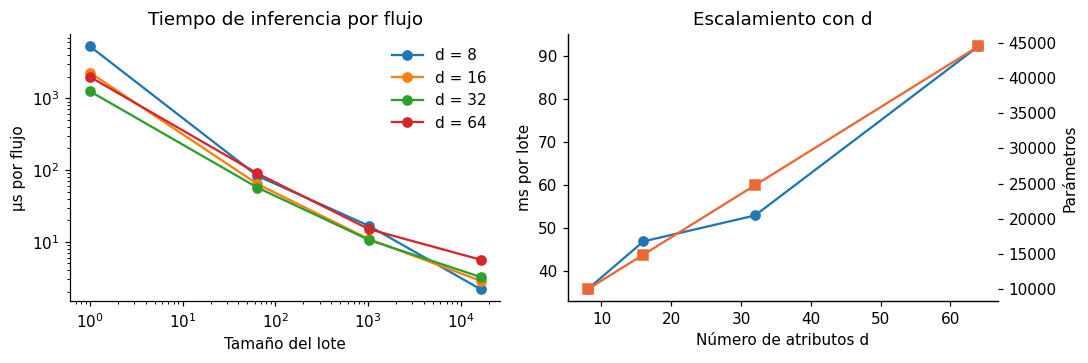

lote,1,64,1024,16384
d,,,,
8,5295.26,83.0625,16.6851,2.1809
16,2280.27,64.0056,10.8918,2.8627
32,1252.67,57.0631,10.6213,3.2320
64,1988.02,89.6934,15.0124,5.6372


In [24]:
comp = pd.read_csv(R / "robustez/complejidad.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for d, g in comp.groupby("d"):
    axes[0].plot(g["lote"], g["µs por flujo"], marker="o", label=f"d = {d}")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Tamaño del lote"); axes[0].set_ylabel("µs por flujo"); axes[0].legend(frameon=False)
axes[0].set_title("Tiempo de inferencia por flujo")
g = comp[comp["lote"] == 16384]
axes[1].plot(g["d"], g["ms por lote"], marker="o", label="tiempo (lote de 16 384)")
axes[1].set_xlabel("Número de atributos d"); axes[1].set_ylabel("ms por lote")
ax2 = axes[1].twinx(); ax2.plot(g["d"], g["parametros"], marker="s", color="#EB6834", label="parámetros"); ax2.set_ylabel("Parámetros")
axes[1].set_title("Escalamiento con d"); plt.tight_layout(); plt.show()
comp.pivot(index="d", columns="lote", values="µs por flujo")

**El tiempo por flujo cae con el tamaño del lote hasta estabilizarse en pocos microsegundos, y tanto los parámetros como el tiempo con lotes grandes crecen de forma aproximadamente lineal con el número de atributos $d$, como predice el análisis asintótico.**

Esto quiere decir que el costo del modelo lo dominan las capas lineales del experto de umbrales, cuya entrada tiene $dT$ dimensiones, y que el modelo puede servir en tiempo real en un nodo con CPU modesta.

En consecuencia, no hace falta cuantizarlo para el dashboard (64 KB en ONNX) y, si se aplicara a conjuntos con más atributos, conviene reducir $T$ antes que los anchos.

### Ablación

Cada variante cambia un solo componente frente al modelo completo y usa las mismas 20 semillas (6001 a 6020), los mismos hiperparámetros y el mismo protocolo. La familia de la ablación tiene su propio Holm (protocolo, sección 9).

In [25]:
abl = pd.read_csv(R / "ablacion/contrastes.csv")
abl[["descripción", "F1 variante", "F1 completo", "completo − variante", "p t Holm", "p Wilcoxon Holm", "δ Cliff", "conf B–W variante", "conf B–W completo",
     "el componente aporta", "el componente resta"]]

,descripción,F1 variante,F1 completo,completo − variante,p t Holm,p Wilcoxon Holm,δ Cliff,conf B–W variante,conf B–W completo,el componente aporta,el componente resta
0,Sin compuerta (promedio 1/2),0.8539,0.8479,-0.0059,5.6832e-02,0.0612,-0.360,0.1437,0.1525,False,False
1,Sin escalones suaves (MLP sobre x),0.8624,0.8479,-0.0145,7.0086e-05,0.0002,-0.810,0.1430,0.1525,False,True
2,Entrenamiento conjunto clásico,0.8584,0.8479,-0.0105,1.0462e-01,0.0887,-0.420,0.1355,0.1525,False,False
3,Sin regularizador de balance (γ = 0),0.8495,0.8479,-0.0016,5.8248e-01,0.2455,-0.115,0.1511,0.1525,False,False
4,Solo el experto suave (modelo base),0.8590,0.8479,-0.0110,3.4492e-03,0.0051,-0.640,0.1462,0.1525,False,True
5,Solo el experto de umbrales,0.8450,0.8479,0.0029,5.8248e-01,0.1946,0.250,0.1509,0.1525,False,False


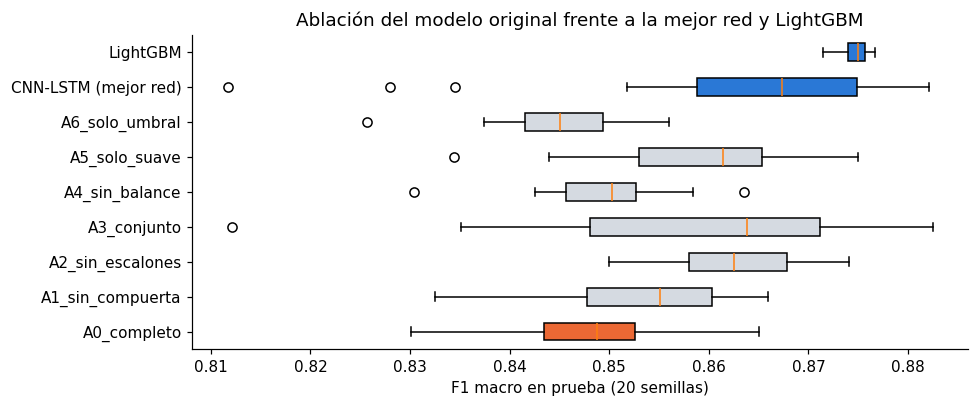

In [26]:
ps = pd.read_csv(R / "ablacion/por_semilla.csv")
orden = ["A0_completo", "A1_sin_compuerta", "A2_sin_escalones", "A3_conjunto", "A4_sin_balance", "A5_solo_suave", "A6_solo_umbral", "CNN-LSTM (mejor red)", "LightGBM"]
fig, ax = plt.subplots(figsize=(9, 3.8))
datos = [ps.loc[ps["variante"] == v, "f1"] for v in orden]
cajas = ax.boxplot(datos, vert=False, patch_artist=True, tick_labels=orden)
for c, v in zip(cajas["boxes"], orden):
    c.set_facecolor("#EB6834" if v == "A0_completo" else ("#2A78D6" if v in ("CNN-LSTM (mejor red)", "LightGBM") else "#D5DAE1"))
ax.set_xlabel("F1 macro en prueba (20 semillas)"); ax.set_title("Ablación del modelo original frente a la mejor red y LightGBM")
plt.tight_layout(); plt.show()

**Quitar el codificador de escalones suaves (A2) mejora el F1 macro de 0,848 a 0,862, una diferencia significativa después de Holm (*p* de 0,0001 en la *t* y 0,0002 en Wilcoxon; δ de Cliff = −0,81). Usar solo el experto suave (A5) también es mejor (0,859). Quitar la compuerta (A1), el entrenamiento cooperativo (A3) o el regularizador de balance (A4) no cambia el F1 de forma significativa. Y usar solo el experto de umbrales (A6) da 0,845, sin diferencia con el modelo completo.**

Esto significa que, en la prueba sellada, el componente central del mecanismo resta en lugar de sumar: los umbrales aprendidos en los escenarios de entrenamiento no transfieren a los segmentos de prueba, y la compuerta no compensa esa pérdida. Es lo contrario de lo observado en la partición de desarrollo, donde el experto de umbrales solo era el mejor diseño (0,843 frente a 0,824 del suave). La diferencia entre desarrollo y confirmación es otra manifestación de la dependencia por escenario: la partición de desarrollo comparte escenarios entre ajuste y evaluación, igual que la prueba, pero en otra proporción.

Por tal motivo, la ablación se reporta como evidencia en contra de la hipótesis del mecanismo y no se itera el diseño con estos resultados, porque usar la prueba para rediseñar invalidaría la confirmación (sección 7.2 del enunciado).

### Predicciones secundarias

In [27]:
p = json.loads((R / "ablacion/predicciones_secundarias.json").read_text(encoding="utf-8"))
pesos = pd.read_csv(R / "ablacion/peso_compuerta_por_clase.csv")
pd.DataFrame({"Predicción": ["P1: sin escalones sube la confusión B–W", "P2: la compuerta pesa más el experto de umbrales en B y W que en Sybil",
                             "P3: la ventaja frente a CNN-LSTM se concentra en B y W"],
              "¿Se cumple?": [p["P1 (sin escalones sube la confusión B–W)"], p["P2 (más peso al experto de umbrales en B y W que en Sybil)"],
                              p["P3 (ventaja concentrada en B y W frente a CNN-LSTM)"]],
              "Evidencia": [f"conf. B–W completo {p['conf_BW']['A0_completo']:.3f}; sin escalones {p['conf_BW']['A2_sin_escalones']:.3f}",
                            "peso medio hacia el experto de umbrales: " + ", ".join(f"{c} {v:.2f}" for c, v in p["peso_umbral_por_clase"].items()),
                            "original − CNN-LSTM por clase: " + ", ".join(f"{k.replace('F1 ', '')} {v:+.3f}" for k, v in p["diferencia_por_clase_vs_CNN-LSTM"].items())]})

,Predicción,¿Se cumple?,Evidencia
0,P1: sin escalones sube la confusión B–W,False,conf. B–W completo 0.152; sin escalones 0.143
1,P2: la compuerta pesa más el experto de umbrales en B y W que en Sybil,True,"peso medio hacia el experto de umbrales: Blackhole 0.69, Flooding 0.44, Normal 0.34, Sybil 0.51, Wormhole 0.88"
2,P3: la ventaja frente a CNN-LSTM se concentra en B y W,False,"original − CNN-LSTM por clase: Blackhole -0.029, Flooding -0.009, Normal -0.005, Sybil +0.001, Wormhole -0.031"


**P2 se cumple: la compuerta envía al experto de umbrales el 88 % del peso en los flujos Wormhole y el 69 % en los Blackhole, frente al 51 % en Sybil y el 34 % en Normal. P1 y P3 no se cumplen: sin el codificador la confusión Blackhole–Wormhole baja de 0,153 a 0,143, y frente a CNN-LSTM el original pierde 0,029 de F1 en Blackhole y 0,031 en Wormhole.**

En ese sentido, el mecanismo hace lo que se diseñó, porque la compuerta aprende a mandar los ataques de enrutamiento al experto de umbrales, pero la premisa causal falla: en la prueba, ese experto separa peor Blackhole de Wormhole que una red suave. El fallo de la hipótesis no es de implementación, sino de transferencia del sesgo.

Con base en esto, se concluye que el sesgo de árbol que hace fuerte a LightGBM no se obtiene con escalones aprendidos por gradiente, y la explicación de esa diferencia queda como trabajo futuro (capítulo 10).

### Interpretabilidad

Se calcularon valores de Shapley de la probabilidad de la clase predicha por muestreo de permutaciones (Lundberg y Lee, 2017), con implementación propia (`experiments/analisis_robustez.py`), para 300 flujos de prueba (60 por clase) frente a un fondo de 50 flujos de entrenamiento, en el modelo original y en LightGBM, el mejor *benchmark*.

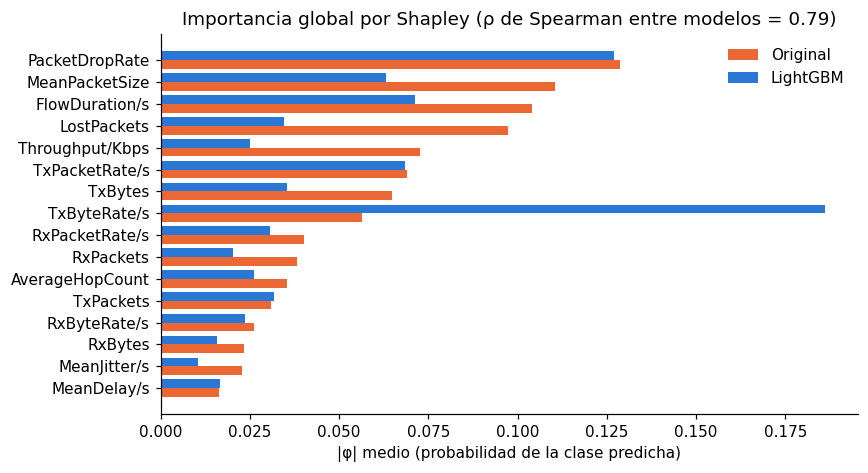

Estabilidad entre semillas del original (ρ de Spearman de la importancia): [0.918, 0.821, 0.935]


,modelo,k atributos borrados,caída de prob. (más importantes),caída de prob. (al azar)
0,Original,1,0.4013,0.0568
1,Original,3,0.6022,0.1555
2,Original,5,0.7023,0.2415
3,LightGBM,1,0.4213,0.0560
4,LightGBM,3,0.6469,0.1369
5,LightGBM,5,0.7236,0.2935


In [28]:
imp = pd.read_csv(R / "robustez/importancia_shapley.csv", index_col=0)
fid = pd.read_csv(R / "robustez/fidelidad_borrado.csv")
res = json.loads((R / "robustez/resumen.json").read_text(encoding="utf-8"))
fig, ax = plt.subplots(figsize=(8, 4.4))
o = imp.sort_values("Original")
y = np.arange(len(o))
ax.barh(y - 0.2, o["Original"], 0.4, color="#EB6834", label="Original"); ax.barh(y + 0.2, o["LightGBM"], 0.4, color="#2A78D6", label="LightGBM")
ax.set_yticks(y, o.index); ax.set_xlabel("|φ| medio (probabilidad de la clase predicha)"); ax.legend(frameon=False)
ax.set_title(f"Importancia global por Shapley (ρ de Spearman entre modelos = {res['interpretabilidad']['spearman_original_vs_lightgbm']:.2f})")
plt.tight_layout(); plt.show()
print("Estabilidad entre semillas del original (ρ de Spearman de la importancia):", [round(r, 3) for r in res["estabilidad_explicaciones"]["spearman_entre_semillas"]])
fid

**Los dos modelos se apoyan en atributos parecidos (ρ de Spearman de 0,79 entre sus importancias globales), y la importancia del original es estable entre semillas (ρ medio de 0,89). La prueba de borrado confirma la fidelidad: reemplazar por la mediana del fondo los atributos más importantes de cada flujo baja la probabilidad de la clase predicha mucho más que borrar el mismo número de atributos al azar.**

Lo anterior indica que las explicaciones no son ruido de una semilla y que el original no depende de un atajo distinto al de LightGBM: usa la información de tasas, pérdida y rendimiento que el dominio asocia con cada ataque.

Por ello, las explicaciones locales del dashboard (oclusión por atributo) se presentan como una ayuda para el analista y se acompañan del aviso fuera de dominio, porque la estabilidad de la importancia no garantiza que la predicción sea correcta.

## Capítulo 7. Validación: protocolo y pruebas de hipótesis

In [29]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAIZ = Path("..").resolve()
C = RAIZ / "experiments/resultados/confirmatorio"
t = pd.read_csv(C / "tabla_contrastes.csv")
resumen = json.loads((C / "resumen.json").read_text(encoding="utf-8"))
potencia = json.loads((RAIZ / "experiments/resultados/potencia.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
print("Preparación del capítulo 7 ejecutada. Quedan definidos: json, Path, np, pd, plt, RAIZ, C, t, resumen, potencia")

Preparación del capítulo 7 ejecutada. Quedan definidos: json, Path, np, pd, plt, RAIZ, C, t, resumen, potencia


### Protocolo preregistrado

El protocolo (`experiments/protocolo.md`) se congeló el 22/11/2026 con la etiqueta de Git `e3-protocolo`, antes de cualquier corrida definitiva, y la declaración del estándar lleva la etiqueta anterior `e3-estandar`. Fija las hipótesis, las predicciones secundarias, la métrica primaria y δ, la fuente del mecanismo, los tres conjuntos adicionales, las particiones, las semillas, el determinismo, la familia de contrastes, las pruebas, la corrección de Holm, el presupuesto de ajuste, el análisis de potencia y *Nd*. Las desviaciones posteriores al congelamiento se declaran, con su justificación, en la última sección de este capítulo.

**Equidad del presupuesto.** El modelo original recibió las mismas 12 configuraciones de (lr, weight_decay, lote) que los 13 modelos profundos del E2, el mismo máximo de 30 épocas, la misma parada temprana sobre el F1 macro de validación con paciencia 6, la misma pérdida ponderada y el mismo recorte del gradiente, con el motor de entrenamiento del E2 (capítulo 6). El presupuesto se midió en número de configuraciones.

### Análisis de potencia

In [30]:
pot = pd.DataFrame(potencia["contrastes"])
pot = pot[pot["familia"] == "confirmatoria"][["rival", "sigma_d", "R_necesarias"]]
pot["semillas usadas"] = pot["rival"].map(t.set_index("rival")["n_semillas"])
pot["potencia observada para δ"] = pot["rival"].map(t.set_index("rival")["potencia para delta"])
pot["MDE observada"] = pot["rival"].map(t.set_index("rival")["MDE"])
print(f"Potencia conjunta observada (producto de las potencias por contraste): {resumen['potencia conjunta observada']:.3f}")
pot

Potencia conjunta observada (producto de las potencias por contraste): 0.115


,rival,sigma_d,R_necesarias,semillas usadas,potencia observada para δ,MDE observada
0,CNN-LSTM,0.0167,48,48,0.9080,0.0085
1,Autoencoder,0.0052,10,20,0.9590,0.0076
2,RNN,0.0096,16,20,0.7639,0.0105
3,Transformer,0.0095,16,20,0.8552,0.0093
4,BiLSTM,0.0103,19,20,0.4075,0.0162
5,ResNet,0.0059,10,20,0.9075,0.0085
6,GRU,0.0100,18,20,0.8621,0.0092
7,KAN,0.0061,10,20,0.8311,0.0096
8,TabNet,0.0148,38,38,0.8315,0.0096
9,DBN,0.0063,10,20,0.9418,0.0079


**El piloto pidió 48 semillas para el contraste con CNN-LSTM y 38 para TabNet, y con ellas se planearon todos los contrastes para una potencia de 0,90. La potencia observada, calculada con la dispersión real de las diferencias, alcanza 0,90 en 6 de los 12 contrastes (CNN-LSTM, Autoencoder, ResNet, DBN, LightGBM y CNN 1D) y se queda entre 0,76 y 0,86 en otros cinco. BiLSTM es el caso extremo, con 0,41 y una diferencia mínima detectable de 0,016. La potencia conjunta es de apenas el 11,5 %.**

Esto significa que el piloto de 5 semillas subestimó la dispersión de las diferencias en la mitad de los contrastes, algo previsible con tan pocas semillas, y que, aun si el modelo original fuera mejor que todos los rivales por exactamente δ, la probabilidad de rechazar los 12 contrastes a la vez sería baja. Es la consecuencia esperada de una prueba de unión-intersección con m = 12 (sección 8.5 del enunciado).

Por lo anterior, cada contraste se reporta con su diferencia mínima detectable, la potencia insuficiente se declara como limitación y se distingue entre "no concluyente" y "equivalente"; un resultado no concluyente no se interpreta como equivalencia.

### Resultados confirmatorios

In [31]:
fam = t[t["familia"] == "confirmatoria"].copy()
fam["decisión"] = np.where(fam["supera (R3)"], "Supera (R3)",
                    np.where((fam[["p T1 t Holm", "p T2 Wilcoxon Holm"]].max(axis=1) < 0.05) & (fam["diferencia"] < 0), "Peor según T1 y T2; T3 no concluyente",
                    np.where((fam[["p T1 t Holm", "p T2 Wilcoxon Holm"]].max(axis=1) < 0.05) & (fam["diferencia"] > 0), "Mejor según T1 y T2; T3 no concluyente",
                             "No concluyente")))
fam[["rival", "n_semillas", "F1 original", "F1 rival", "diferencia", "IC95 t", "p T1 t Holm", "p T2 Wilcoxon Holm", "p T3 bootstrap bloques Holm",
     "delta Cliff", "P(original>rival) bayes", "P(ROPE)", "decisión"]]

,rival,n_semillas,F1 original,F1 rival,diferencia,IC95 t,p T1 t Holm,p T2 Wilcoxon Holm,p T3 bootstrap bloques Holm,delta Cliff,P(original>rival) bayes,P(ROPE),decisión
0,CNN-LSTM,48,0.8496,0.8591,-0.0095,"(np.float64(-0.015451377299035613), np.float64(-0.003470213679465697))",2.1031e-02,2.1906e-02,1.0000,-0.3889,0.0001,0.0585,Peor según T1 y T2; T3 no concluyente
1,Autoencoder,20,0.8479,0.8591,-0.0111,"(np.float64(-0.01650398604504042), np.float64(-0.005780206222042293))",3.1078e-03,2.6131e-03,0.6107,-0.6000,0.0000,0.4845,Peor según T1 y T2; T3 no concluyente
2,RNN,20,0.8479,0.8371,0.0108,"(np.float64(0.003424123380895726), np.float64(0.01824853157296487))",3.6407e-02,6.0396e-02,1.0000,0.5050,0.8021,0.1979,No concluyente
3,Transformer,20,0.8479,0.8576,-0.0097,"(np.float64(-0.016272111750580846), np.float64(-0.003122510977425096))",3.6407e-02,5.6614e-02,0.6467,-0.5450,0.0000,0.3033,No concluyente
4,BiLSTM,20,0.8479,0.8457,0.0022,"(np.float64(-0.009268893466863963), np.float64(0.013761693620545882))",1.0000e+00,1.0000e+00,1.0000,-0.0750,0.1774,0.6956,No concluyente
5,ResNet,20,0.8479,0.8510,-0.0030,"(np.float64(-0.009057085947851066), np.float64(0.0030229106292942874))",1.0000e+00,1.0000e+00,0.9299,-0.1300,0.0000,0.9887,No concluyente
6,GRU,20,0.8479,0.8474,0.0005,"(np.float64(-0.005973955824007528), np.float64(0.00704184959886546))",1.0000e+00,1.0000e+00,1.0000,-0.0400,0.0026,0.9964,No concluyente
7,KAN,20,0.8479,0.8488,-0.0009,"(np.float64(-0.007693136887489694), np.float64(0.005910504182886146))",1.0000e+00,1.0000e+00,1.0000,-0.1000,0.0027,0.9901,No concluyente
8,TabNet,38,0.8485,0.8301,0.0184,"(np.float64(0.011673641533960626), np.float64(0.025187420416206238))",3.0216e-05,2.5292e-05,1.0000,0.5429,0.9938,0.0063,Mejor según T1 y T2; T3 no concluyente
9,DBN,20,0.8479,0.8569,-0.0089,"(np.float64(-0.014552719356344772), np.float64(-0.0033120460878486935))",2.4833e-02,4.4727e-02,1.0000,-0.6000,0.0000,0.6943,Peor según T1 y T2; T3 no concluyente


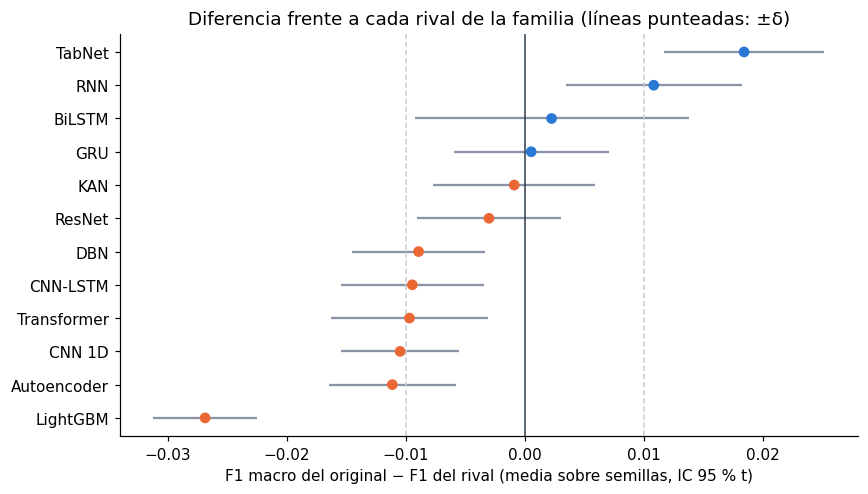

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.6))
f = fam.sort_values("diferencia")
ic = np.array([eval(s.replace("np.float64", "")) for s in f["IC95 t"]])
colores = ["#EB6834" if d < 0 else "#2A78D6" for d in f["diferencia"]]
ax.errorbar(f["diferencia"], f["rival"], xerr=[f["diferencia"] - ic[:, 0], ic[:, 1] - f["diferencia"]], fmt="none", ecolor="#8A94A6")
ax.scatter(f["diferencia"], f["rival"], c=colores, zorder=3)
for x0 in (-0.01, 0, 0.01):
    ax.axvline(x0, color="#2C3E50" if x0 == 0 else "#C9CED6", lw=1, ls="-" if x0 == 0 else "--")
ax.set_xlabel("F1 macro del original − F1 del rival (media sobre semillas, IC 95 % t)")
ax.set_title("Diferencia frente a cada rival de la familia (líneas punteadas: ±δ)")
plt.tight_layout(); plt.show()

**El modelo original obtiene un F1 macro medio de 0,850 en la prueba sellada (48 semillas) y no supera con significancia a ninguno de los 12 rivales: la condición R3 no se cumple.** Contraste por contraste:

- **Es mejor que TabNet** (+0,018) según la *t* pareada y Wilcoxon, y que RNN (+0,011) solo según la *t*.
- **Es peor que LightGBM** (−0,027), Autoencoder (−0,011), CNN 1D (−0,010), CNN-LSTM (−0,009) y DBN (−0,009) según esas dos pruebas, y que Transformer (−0,010) solo según la *t*.
- **No se distingue de BiLSTM, ResNet, GRU y KAN.** Frente a ResNet, GRU y KAN la prueba bayesiana pone más del 98 % de la probabilidad dentro de la región de equivalencia práctica (±δ).

Hay que tener en cuenta que la tercera prueba, el *bootstrap* por bloques de prueba, no rechaza en ningún contraste de la familia: la prueba sellada tiene solo 23 bloques de 1000 flujos, casi todos de una sola clase, y al remuestrearlos cambia la composición de clases, así que el intervalo de la diferencia es muy ancho (frente a LightGBM va de −0,067 a +0,039). Como la regla preregistrada exige que las tres pruebas rechacen, los contrastes en los que la *t* y Wilcoxon coinciden quedan como resultados de dos pruebas y no como decisiones confirmatorias. La diferencia con LightGBM es la más grande y la más estable: es negativa en las 20 semillas (δ de Cliff = −1).

Así las cosas, el tope de la calificación es 4,0 (sección 14.1 del enunciado) y el trabajo se sostiene en el hallazgo alternativo preregistrado: el *benchmark* riguroso, la explicación de por qué el escenario pesa más que la arquitectura y la medición de cuándo ayuda el mecanismo (capítulos 6, 8 y 10).

### Procedimiento global y diagrama de diferencia crítica

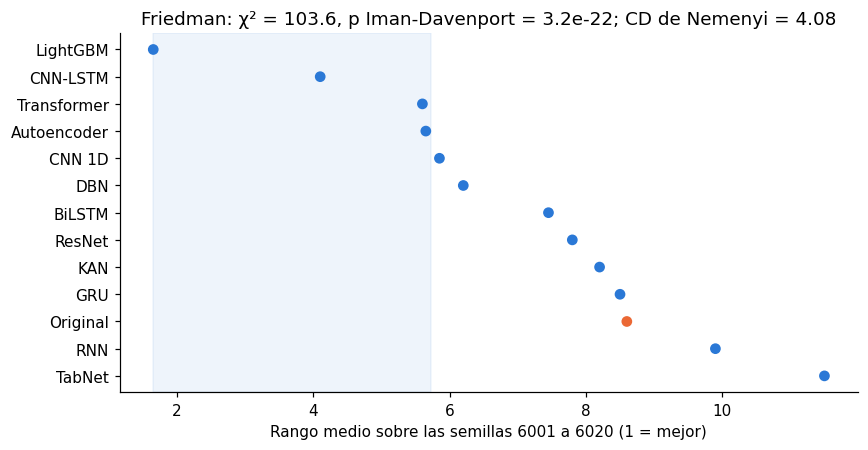

In [33]:
rangos = pd.Series(resumen["rangos medios (1 = mejor)"]).sort_values()
cd = json.loads((RAIZ / "artifacts/dashboard/resumen.json").read_text(encoding="utf-8")).get("cd_nemenyi")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(rangos.values, rangos.index, color=["#EB6834" if m == "Original" else "#2A78D6" for m in rangos.index], zorder=3)
ax.axvspan(rangos.iloc[0], rangos.iloc[0] + cd, color="#2A78D6", alpha=0.08)
ax.invert_yaxis(); ax.set_xlabel("Rango medio sobre las semillas 6001 a 6020 (1 = mejor)")
ax.set_title(f"Friedman: χ² = {resumen['friedman']['chi2']:.1f}, p Iman-Davenport = {resumen['friedman']['p Iman-Davenport']:.1e}; CD de Nemenyi = {cd:.2f}")
plt.tight_layout(); plt.show()

**La prueba de Friedman rechaza que los 13 modelos sean iguales (χ² = 103,6; *p* de Iman-Davenport del orden de 10⁻²²; W de Kendall = 0,43). LightGBM tiene el mejor rango medio (1,65), seguido de CNN-LSTM (4,1); el modelo original queda en un rango medio de 8,6, dentro del grupo intermedio.**

De esta forma, la conclusión del procedimiento global coincide con la de los contrastes pareados: hay diferencias reales entre modelos, LightGBM está en el primer lugar con una distancia mayor que la diferencia crítica (4,08) frente a la mayoría, y el original no se separa del grupo de redes intermedias.

Por esta razón, el modelo original se presenta como una alternativa con ventajas en robustez (capítulo 8), no como un modelo superior en F1 macro.

### Sensibilidad de la conclusión

In [34]:
fam[["rival", "P(original>rival) bayes", "P(ROPE)", "P(original<rival) bayes", "dif exactitud balanceada", "p t bacc Holm", "p t primeras 20"]]

,rival,P(original>rival) bayes,P(ROPE),P(original<rival) bayes,dif exactitud balanceada,p t bacc Holm,p t primeras 20
0,CNN-LSTM,0.0001,0.0585,0.9414,-0.0122,2.2429e-03,3.7662e-03
1,Autoencoder,0.0000,0.4845,0.5154,-0.0115,7.5911e-04,3.4531e-04
2,RNN,0.8021,0.1979,0.0000,0.0098,1.1268e-01,6.4454e-03
3,Transformer,0.0000,0.3033,0.6967,-0.0126,4.1905e-03,6.0678e-03
4,BiLSTM,0.1774,0.6956,0.1269,-0.0005,1.0000e+00,6.8761e-01
5,ResNet,0.0000,0.9887,0.0114,-0.0026,1.0000e+00,3.0891e-01
6,GRU,0.0026,0.9964,0.0010,-0.0010,1.0000e+00,8.6547e-01
7,KAN,0.0027,0.9901,0.0072,-0.0010,1.0000e+00,7.8684e-01
8,TabNet,0.9938,0.0063,0.0000,0.0176,2.1747e-04,1.9377e-04
9,DBN,0.0000,0.6943,0.3057,-0.0133,6.2877e-04,3.5475e-03


La conclusión principal, que R3 no se cumple, se mantiene con las cuatro variantes preregistradas:

- la prueba bayesiana de rangos con signo con ROPE ±δ, que da una probabilidad alta de que el original sea peor que LightGBM;
- la exactitud balanceada como métrica secundaria;
- el subconjunto de las 20 primeras semillas;
- la *t* corregida de Nadeau-Bengio sobre la validación cruzada 5 × 2 (capítulo 8).

### Pruebas admisibles del cuadro 4 (sensibilidad)

In [35]:
c4 = pd.read_csv(C / "sensibilidad_cuadro4.csv")
c4[["rival", "diferencia", "p A1 Wilcoxon Holm", "p A2 t Nadeau-Bengio Holm", "p A3 McNemar Holm", "p A4 Friedman post hoc Holm",
    "P(original>rival) bayes", "P(original<rival) bayes", "DeLong clases a favor", "DeLong clases en contra",
    "pruebas a favor del original", "pruebas en contra del original", "supera (R3 estricto)"]].fillna("")

,rival,diferencia,p A1 Wilcoxon Holm,p A2 t Nadeau-Bengio Holm,p A3 McNemar Holm,p A4 Friedman post hoc Holm,P(original>rival) bayes,P(original<rival) bayes,DeLong clases a favor,DeLong clases en contra,pruebas a favor del original,pruebas en contra del original,supera (R3 estricto)
0,CNN-LSTM,-0.0095,2.1906e-02,1.0000,6.6314e-45,2.8402e-03,0.0001,0.9414,0,5,,"A1, A3, A4, A6",False
1,Autoencoder,-0.0111,2.6131e-03,1.0000,8.9089e-20,1.4942e-01,0.0000,0.5154,1,4,,"A1, A3, A6",False
2,RNN,0.0108,6.0396e-02,1.0000,9.4302e-01,1.0000e+00,0.8021,0.0000,2,1,,,False
3,Transformer,-0.0097,5.6614e-02,1.0000,6.1528e-44,1.4851e-01,0.0000,0.6967,0,5,,"A3, A6",False
4,BiLSTM,0.0022,1.0000e+00,1.0000,9.9624e-24,1.0000e+00,0.1774,0.1269,0,5,,"A3, A6",False
5,ResNet,-0.0030,1.0000e+00,1.0000,2.1609e-08,1.0000e+00,0.0000,0.0114,1,2,,A3,False
6,GRU,0.0005,1.0000e+00,1.0000,6.5762e-02,1.0000e+00,0.0026,0.0010,0,4,,A6,False
7,KAN,-0.0009,1.0000e+00,1.0000,1.9928e-01,1.0000e+00,0.0027,0.0072,0,4,,A6,False
8,TabNet,0.0184,2.5292e-05,1.0000,1.0854e-01,1.4942e-01,0.9938,0.0000,2,3,"A1, A5",A6,False
9,DBN,-0.0089,4.4727e-02,1.0000,6.0138e-06,3.0792e-01,0.0000,0.3057,0,4,,"A1, A3, A6",False


La fila "F1. Tabular" del cuadro 4 del enunciado admite la *t* pareada con corrección de Nadeau-Bengio, la *F* de 5 × 2 cv, Wilcoxon, McNemar y DeLong, Friedman con Holm y la prueba bayesiana con ROPE. Dos de las tres pruebas preregistradas no coinciden al pie de la letra con esa lista: T1 es la *t* pareada sin la corrección y T3, el *bootstrap* por bloques, figura en la fila de problemas espaciales. Por eso se repite el análisis con seis pruebas admisibles, con Holm aparte para cada una:

- **A1.** Wilcoxon sobre las semillas.
- **A2.** *t* con corrección de Nadeau-Bengio sobre las semillas.
- **A3.** McNemar exacta sobre los aciertos del ensamble.
- **A4.** Friedman con *post hoc* de Holm.
- **A5.** Bayesiana con ROPE, que cuenta como rechazo cuando la probabilidad posterior supera 0,95.
- **A6.** DeLong sobre el AUC uno contra todos de cada clase, que cuenta como rechazo cuando al menos 3 de las 5 clases son significativas en el mismo sentido.

La *F* de 5 × 2 cv y Nadeau-Bengio sobre 5 × 2 están en el capítulo 8.

**Con las pruebas admisibles la conclusión no cambia: el modelo original no supera a ningún rival con tres pruebas, y cinco rivales son mejores que él con tres o más: LightGBM (con las seis), CNN-LSTM (con cuatro), Autoencoder, DBN y CNN 1D (con tres cada uno). Frente a TabNet solo lo favorecen Wilcoxon y la bayesiana, con P(original > TabNet) = 0,994.**

Hay que tener en cuenta que McNemar (A3) y DeLong (A6) tratan los 22 883 flujos como si fueran independientes, cuando están agrupados por escenario, de modo que son anticonservadoras. Si se cuentan solo las pruebas sobre semillas (A1, A2, A4 y A5), únicamente LightGBM es mejor con tres o más, con las cuatro. Además, la *t* con corrección de Nadeau-Bengio infla la varianza con el factor n_prueba/n_entrenamiento = 0,31 aunque el entrenamiento no cambie entre semillas, y solo rechaza frente a LightGBM.

Por tal motivo, se mantiene la decisión preregistrada (R3 no se cumple y el tope es 4,0) y la batería admisible se reporta como sensibilidad. En ninguna combinación de pruebas el original supera a un rival. La superioridad de LightGBM queda respaldada por todas, aunque el capítulo 8 muestra que desaparece en la validación cruzada 5 × 2 y la reporta como resultado no robusto a la partición, como pide la condición 6 de la sección 8.4 del enunciado.

### Ajuste y sobreajuste del modelo original

La prueba de permutación de etiquetas, el optimismo por *bootstrap* y la curva de aprendizaje se reportan en el capítulo 8 con las corridas de `training/ejecutar_robustez.py`. Su F1 medio de prueba (0,850) supera ampliamente al clasificador trivial (0,070). La brecha media entre validación (0,919 en el piloto) y prueba es de unos 0,07, del mismo orden que la de las demás redes del E2, porque se debe a la dependencia por escenario documentada en el capítulo 1 y no a un sobreajuste propio del modelo.

### Desviaciones del protocolo

1. **Pruebas del cuadro 4 (23/11/2026, después de ver los resultados).** El protocolo citó la fila tabular del cuadro 4 para T1 a T3, pero T3 pertenece a la fila espacial y T1 no lleva la corrección de Nadeau-Bengio. No se reemplazó la decisión preregistrada: se agregó la sensibilidad con las pruebas admisibles de la sección anterior (`experiments/analisis_cuadro4.py`). La conclusión es la misma, y el cambio no podía favorecer al original, porque su F1 medio ya es menor que el de 8 de los 12 rivales.
2. **GPU en 31 corridas de los conjuntos adicionales (23/11/2026).** Las GRU de UNSW-NB15, las BiLSTM y GRU de UNR-IDD y una GRU de UAV-NIDD corrieron en una GPU NVIDIA RTX PRO 6000 Blackwell (porción MIG de 24 GB, PyTorch 2.8.0 y CUDA 12.8), con determinismo estricto de CUDA. Es la opción prevista en la sección 5 del protocolo, solo para BiLSTM y GRU de esos conjuntos. Con la misma semilla, la GRU de UNR-IDD dio un F1 de prueba de 0,722 en CPU y de 0,696 en GPU, una variación del orden de dos desviaciones estándar entre semillas, que se discute en el capítulo 8.
3. **Partición de los conjuntos adicionales (22/11/2026, antes de etiquetar el protocolo y de entrenar cualquier modelo).** Los bloques de 1000 filas sin estratificar dejaban clases fuera de la prueba; se cambiaron por bloques de 250 filas estratificados por clase (sección 5.3 del protocolo).

## Capítulo 8. Evaluación ampliada: conjuntos adicionales, robustez y adecuación

In [36]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
RAIZ = Path("..").resolve()
R = RAIZ / "experiments/resultados"
A = R / "adicionales"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
NARANJA, AZUL, GRIS = "#EB6834", "#2A78D6", "#8A94A6"
CONJ = {"uav_nidd": "UAV-NIDD", "unsw_nb15": "UNSW-NB15", "unr_idd": "UNR-IDD"}
tablas = pd.concat([pd.read_csv(A / f"tabla_{c}.csv") for c in CONJ])
contrastes = pd.concat([pd.read_csv(A / f"contrastes_{c}.csv") for c in CONJ])
res_ad = json.loads((A / "resumen.json").read_text(encoding="utf-8"))
adec = json.loads((R / "adecuacion/resumen.json").read_text(encoding="utf-8"))
print("Preparación del capítulo 8 ejecutada. Quedan definidos: json, Path, np, pd, plt, stats, RAIZ, R, A, CONJ, tablas, contrastes, res_ad, adec")

Preparación del capítulo 8 ejecutada. Quedan definidos: json, Path, np, pd, plt, stats, RAIZ, R, A, CONJ, tablas, contrastes, res_ad, adec


Este capítulo responde a las condiciones 4, 5 y 6 de la definición operativa de superioridad (sección 8.4 del enunciado) y al cuadro 5 de robustez, calibración y eficiencia. Las condiciones 1 a 3 están en el capítulo 7; el balance de las seis condiciones, al final de este capítulo.

### Conjuntos adicionales

Los tres conjuntos se eligieron el 22/11/2026, antes de entrenar cualquier modelo con ellos, y no se usaron para ninguna decisión de diseño (sección 5.3 del protocolo). Los 13 modelos de la familia se entrenaron con sus hiperparámetros y su arquitectura del problema principal, sin búsqueda nueva para ninguno, con 10 semillas (6001 a 6010), el mismo tope de 30 épocas y la misma parada temprana. Son 390 corridas, sin errores.

#### Desempeño por conjunto

In [37]:
t = tablas.assign(**{"F1 ± DE": tablas["F1 macro"].map("{:.3f}".format) + " ± " + tablas["DE"].map("{:.3f}".format)})
pd.concat({c: t[t["conjunto"] == c].set_index("modelo")[["F1 ± DE", "rango"]] for c in CONJ.values()}, axis=1)

UAV-NIDD            UNSW-NB15              UNR-IDD      
                   F1 ± DE rango        F1 ± DE rango        F1 ± DE rango
modelo                                                                    
Original     0.550 ± 0.025    11  0.665 ± 0.007     6  0.765 ± 0.014     3
CNN-LSTM     0.603 ± 0.023     2  0.681 ± 0.005     3  0.733 ± 0.023     9
Autoencoder  0.570 ± 0.038     6  0.668 ± 0.006     4  0.742 ± 0.008     8
RNN          0.594 ± 0.049     3  0.656 ± 0.017    10  0.719 ± 0.017    10
Transformer  0.588 ± 0.037     4  0.664 ± 0.006     7  0.752 ± 0.008     5
BiLSTM       0.553 ± 0.031     9  0.689 ± 0.014     2  0.798 ± 0.016     2
ResNet       0.544 ± 0.011    12  0.668 ± 0.008     5  0.762 ± 0.011     4
GRU          0.580 ± 0.030     5  0.656 ± 0.009    11  0.710 ± 0.014    12
KAN          0.554 ± 0.004     8  0.652 ± 0.008    12  0.745 ± 0.015     7
TabNet       0.490 ± 0.121    13  0.630 ± 0.016    13  0.705 ± 0.011    13
DBN          0.617 ± 0.011     1  0.661 ± 0.007     9  0.719 ± 0.008    11
LightGBM     0.562 ± 0.000     7  0.709 ± 0.002     1  0.829 ± 0.003     1
CNN 1D       0.552 ± 0.024    10  0.663 ± 0.015     8  0.750 ± 0.010     6

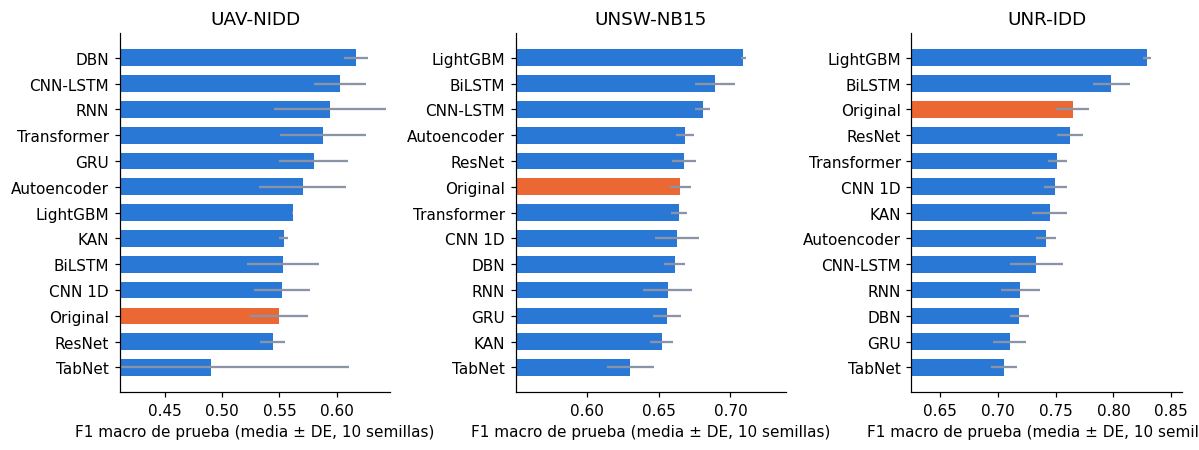

In [38]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 4.2), sharey=False)
for ax, c in zip(ejes, CONJ.values()):
    s = tablas[tablas["conjunto"] == c].sort_values("F1 macro")
    ax.barh(s["modelo"], s["F1 macro"], xerr=s["DE"], color=[NARANJA if m == "Original" else AZUL for m in s["modelo"]], ecolor=GRIS, height=0.65)
    ax.set_xlim(s["F1 macro"].min() - 0.08, s["F1 macro"].max() + 0.03)
    ax.set_title(c); ax.set_xlabel("F1 macro de prueba (media ± DE, 10 semillas)")
plt.tight_layout(); plt.show()

**El modelo original no es el mejor en ningún conjunto adicional: queda en el puesto 11 de 13 en UAV-NIDD (F1 de 0,550 frente a 0,617 de DBN), en el 6 en UNSW-NB15 (0,665 frente a 0,709 de LightGBM) y en el 3 en UNR-IDD (0,765 frente a 0,829 de LightGBM y 0,798 de BiLSTM).**

Así mismo, el modelo que domina no cambia de un conjunto a otro tanto como el original: LightGBM es el mejor en UNSW-NB15 y en UNR-IDD, como en UAVIDS-2025, mientras que en UAV-NIDD queda séptimo y gana DBN, en un conjunto donde todos los modelos están entre 0,49 y 0,62 de F1 macro y las diferencias entre semillas son grandes (TabNet tiene una DE de 0,12).

Por esta razón, la tabla se lee conjunto por conjunto, sin promediar F1 de escalas distintas, como pide la sección 8.3 del enunciado, y la comparación formal se hace con los contrastes pareados de cada conjunto y con la prueba entre conjuntos.

#### Contrastes del original en cada conjunto

In [39]:
def marca(f):
    if f["peor con significancia (T1 a T3)"]:
        return "peor (T1, T2 y T3)"
    if f["peor con significancia (T1 y T2)"]:
        return "peor (T1 y T2)"
    if f["supera"]:
        return "supera (R3)"
    if f["mejor con significancia (T1 y T2)"]:
        return "mejor (T1 y T2)"
    return "no concluyente"
contrastes["lectura"] = contrastes.apply(marca, axis=1)
contrastes["celda"] = contrastes["diferencia"].map("{:+.3f}".format) + " · " + contrastes["lectura"]
contrastes.pivot(index="rival", columns="conjunto", values="celda")[list(CONJ.values())]

conjunto,UAV-NIDD,UNSW-NB15,UNR-IDD
rival,,,
Autoencoder,-0.021 · no concluyente,-0.003 · no concluyente,+0.023 · mejor (T1 y T2)
BiLSTM,-0.004 · no concluyente,"-0.024 · peor (T1, T2 y T3)",-0.034 · peor (T1 y T2)
CNN 1D,-0.003 · no concluyente,+0.002 · no concluyente,+0.015 · no concluyente
CNN-LSTM,-0.053 · no concluyente,"-0.015 · peor (T1, T2 y T3)",+0.031 · mejor (T1 y T2)
DBN,-0.067 · peor (T1 y T2),+0.004 · no concluyente,+0.046 · mejor (T1 y T2)
GRU,-0.030 · no concluyente,+0.009 · no concluyente,+0.054 · mejor (T1 y T2)
KAN,-0.004 · no concluyente,+0.013 · no concluyente,+0.020 · no concluyente
LightGBM,-0.012 · no concluyente,"-0.044 · peor (T1, T2 y T3)",-0.065 · peor (T1 y T2)
RNN,-0.045 · peor (T1 y T2),+0.009 · no concluyente,+0.045 · supera (R3)


In [40]:
pd.DataFrame({c: {"bloques de prueba": int(g["bloques de prueba"].iloc[0]), "potencia media para δ": round(g["potencia para delta"].mean(), 2),
                  "diferencia mínima detectable media": round(g["MDE"].mean(), 4)} for c, g in contrastes.groupby("conjunto")}).T

,bloques de prueba,potencia media para δ,diferencia mínima detectable media
UAV-NIDD,24.0,0.21,0.0373
UNR-IDD,23.0,0.37,0.0180
UNSW-NB15,687.0,0.71,0.0115


**El original es significativamente peor que CNN-LSTM, BiLSTM y LightGBM en UNSW-NB15 con las tres pruebas, y en UNR-IDD supera con significancia a seis rivales (CNN-LSTM, Autoencoder, RNN, GRU, TabNet y DBN) según la *t* y Wilcoxon, a RNN con las tres pruebas, pero pierde frente a BiLSTM y LightGBM según esas dos. En UAV-NIDD ninguna diferencia resiste las tres pruebas; según la *t* y Wilcoxon, RNN y DBN son mejores.**

Hay que tener en cuenta que la potencia cambia mucho entre conjuntos. Con 10 semillas, la potencia media para detectar δ = 0,01 es de 0,21 en UAV-NIDD, de 0,71 en UNSW-NB15 y de 0,37 en UNR-IDD, y la tercera prueba, el *bootstrap* por bloques, solo tiene 24 bloques de prueba en UAV-NIDD y 23 en UNR-IDD, frente a 687 en UNSW-NB15. Por eso las tres pruebas solo coinciden en UNSW-NB15, que es también el único conjunto donde el original pierde con todas.

Por lo anterior, conviene leer UNR-IDD como el caso favorable al original (gana a la mitad de la familia con dos pruebas) y UNSW-NB15 como el desfavorable, sin generalizar ninguno de los dos.

#### Prueba entre conjuntos de datos

In [41]:
filas = []
for clave, nombre in (("entre conjuntos (3 adicionales)", "3 adicionales"), ("entre conjuntos (3 adicionales + UAVIDS-2025, sensibilidad)", "3 adicionales + UAVIDS-2025")):
    e = res_ad[clave]
    filas.append({"conjuntos": nombre, "χ² de Friedman": e["friedman"]["chi2"], "p Iman-Davenport": e["friedman"]["p Iman-Davenport"],
                  "W de Kendall": e["friedman"]["W de Kendall"], "rango del original": e["rangos medios (1 = mejor)"]["Original"],
                  "mejor modelo (rango)": min(e["rangos medios (1 = mejor)"].items(), key=lambda kv: kv[1])})
display(pd.DataFrame(filas))
pares = pd.DataFrame(res_ad["entre conjuntos (3 adicionales)"]["pares"])[["rival", "mejor en", "p Wilcoxon", "p Wilcoxon Holm", "P(A > B)", "P(ROPE)", "P(A < B)"]]
pares.rename(columns={"mejor en": "conjuntos donde el original es mejor", "P(A > B)": "P(original > rival)", "P(A < B)": "P(original < rival)"})

,conjuntos,χ² de Friedman,p Iman-Davenport,W de Kendall,rango del original,mejor modelo (rango)
0,3 adicionales,15.6923,0.1757,0.4359,6.67,"(LightGBM, 3.0)"
1,3 adicionales + UAVIDS-2025,22.3846,0.0126,0.4663,7.25,"(LightGBM, 2.5)"


,rival,conjuntos donde el original es mejor,p Wilcoxon,p Wilcoxon Holm,P(original > rival),P(ROPE),P(original < rival)
0,CNN-LSTM,1,0.75,1.0,0.1547,0.2490,0.5964
1,Autoencoder,1,1.00,1.0,0.1293,0.6077,0.2631
2,RNN,2,0.75,1.0,0.3098,0.3765,0.3137
3,Transformer,2,1.00,1.0,0.0454,0.5570,0.3976
4,BiLSTM,0,0.25,1.0,0.0000,0.2059,0.7941
5,ResNet,2,0.75,1.0,0.0000,1.0000,0.0000
6,GRU,2,0.75,1.0,0.4340,0.2837,0.2824
7,KAN,2,0.50,1.0,0.2058,0.7942,0.0000
8,TabNet,3,0.25,1.0,0.9747,0.0253,0.0000
9,DBN,2,1.00,1.0,0.2833,0.2819,0.4348


**La prueba de Friedman con la corrección de Iman-Davenport no rechaza la igualdad de los 13 modelos sobre los tres conjuntos adicionales (*p* = 0,18), pero sí al incluir UAVIDS-2025 (*p* = 0,013). En los dos casos LightGBM tiene el mejor rango medio (3,0 y 2,5) y el original queda en la mitad (6,7 y 7,25).**

Esto significa que, con tres o cuatro conjuntos, la prueba global tiene muy poca potencia, como advierte la sección 8.3 del enunciado: con tres conjuntos el *p* más pequeño que puede dar Wilcoxon es 0,25, de modo que ningún contraste por pares entre conjuntos puede rechazar, y la prueba bayesiana, con tan pocas observaciones, reparte la probabilidad entre las tres regiones.

Por tal motivo, la conclusión entre conjuntos se apoya en la consistencia por conjunto, que es la condición 4 de R3.

#### Consistencia (condición 4 de R3)

In [42]:
pd.DataFrame(res_ad["consistencia por conjunto"]).T[["F1 original", "rango del original (de 13)", "mejor rival", "F1 mejor rival", "original mejor que todos en la media",
                                                     "rivales significativamente mejores (T1 a T3)", "rivales significativamente peores (T1 y T2)"]]

,F1 original,rango del original (de 13),mejor rival,F1 mejor rival,original mejor que todos en la media,rivales significativamente mejores (T1 a T3),rivales significativamente peores (T1 y T2)
UAV-NIDD,0.5496,11,DBN,0.6169,False,[],[]
UNSW-NB15,0.6651,6,LightGBM,0.7088,False,"[CNN-LSTM, BiLSTM, LightGBM]",[TabNet]
UNR-IDD,0.7646,3,LightGBM,0.8292,False,[],"[CNN-LSTM, Autoencoder, RNN, GRU, TabNet, DBN]"


**La condición 4 no se cumple: el original no es el mejor en la media en ninguno de los tres conjuntos (se exige en al menos dos), y en UNSW-NB15 es significativamente peor que tres rivales de la familia.**

En ese sentido, los conjuntos adicionales confirman lo que mostró el problema principal: el original queda en el grupo intermedio de las redes, y su ventaja relativa aparece en el conjunto de menor dimensión (UNR-IDD, 18 atributos), donde los escalones suaves sobre pocos ejes compiten mejor con las redes que en UAV-NIDD (43 atributos) o UNSW-NB15 (38).

Así las cosas, R3 falla también por consistencia, independientemente de las pruebas del capítulo 7, y el tope de 4,0 no depende de una sola partición ni de un solo conjunto.

#### Dos fuentes de variación que se declaran

In [43]:
tope = tablas.pivot(index="modelo", columns="conjunto", values="corridas en el tope de 30 épocas")[list(CONJ.values())]
gpu = tablas.pivot(index="modelo", columns="conjunto", values="corridas en GPU")[list(CONJ.values())]
cpu_gpu = {k: json.loads((R / "corridas" / p).read_text(encoding="utf-8"))["f1_eva"]
           for k, p in (("CPU", "verificacion_dispositivo/unr_idd_GRU_6001_cpu.json"), ("GPU", "adicionales/unr_idd_GRU_6001.json"))}
print("GRU, UNR-IDD, semilla 6001: F1 de prueba en CPU = {CPU:.4f}, en GPU = {GPU:.4f}".format(**cpu_gpu))
pd.concat({"corridas en el tope de 30 épocas (de 10)": tope, "corridas en GPU (de 10)": gpu}, axis=1)

GRU, UNR-IDD, semilla 6001: F1 de prueba en CPU = 0.7223, en GPU = 0.6959


corridas en el tope de 30 épocas (de 10)                    \
conjunto                                    UAV-NIDD UNSW-NB15 UNR-IDD   
modelo                                                                   
Autoencoder                                      0.0       1.0     0.0   
BiLSTM                                           0.0       4.0     1.0   
CNN 1D                                           0.0       2.0     6.0   
CNN-LSTM                                         0.0       8.0     1.0   
DBN                                              0.0       8.0     0.0   
GRU                                              0.0       8.0     1.0   
KAN                                              0.0       1.0     0.0   
LightGBM                                         NaN       NaN     NaN   
Original                                         0.0       2.0     1.0   
RNN                                              0.0       5.0     4.0   
ResNet                                           0.0       4.0     3.0   
TabNet                                           0.0       7.0     6.0   
Transformer                                      0.0       6.0     0.0   

            corridas en GPU (de 10)                    
conjunto                   UAV-NIDD UNSW-NB15 UNR-IDD  
modelo                                                 
Autoencoder                       0         0       0  
BiLSTM                            0         0      10  
CNN 1D                            0         0       0  
CNN-LSTM                          0         0       0  
DBN                               0         0       0  
GRU                               1        10      10  
KAN                               0         0       0  
LightGBM                          0         0       0  
Original                          0         0       0  
RNN                               0         0       0  
ResNet                            0         0       0  
TabNet                            0         0       0  
Transformer                       0         0       0

**Treinta y una corridas de BiLSTM y GRU se hicieron en GPU, y con la misma semilla la GRU de UNR-IDD dio un F1 de prueba de 0,722 en CPU y de 0,696 en GPU. Además, en UNSW-NB15 varias redes tocaron el tope de 30 épocas: CNN-LSTM, GRU y DBN en 8 de sus 10 corridas, frente a 2 del original.**

Hay que tener en cuenta que la diferencia entre CPU y GPU, de 0,026, equivale a unas dos desviaciones estándar entre semillas de esa GRU (0,014): el hardware es una fuente de variación del mismo orden que la semilla, como reconoce la sección 8.2 del enunciado. Sin embargo, la conclusión no depende de esas corridas: el mejor modelo de cada conjunto (DBN, LightGBM y LightGBM) y los tres rivales que superan al original con las tres pruebas en UNSW-NB15 (CNN-LSTM, BiLSTM y LightGBM) corrieron en CPU.

Por lo anterior, se declara el dispositivo de cada corrida en la tabla maestra y el tope de épocas como limitación: los rivales que lo tocan pudieron quedar algo cortos de entrenamiento, lo que, si acaso, favorece al original.

### Robustez

#### Perturbaciones de las entradas

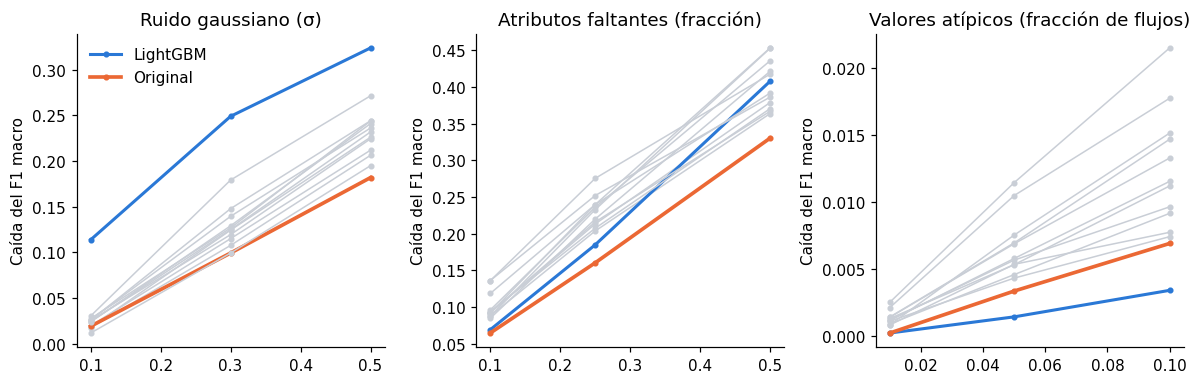

perturbacion atributos faltantes imputados con la media               ninguna  \
severidad                                          0.10   0.25   0.50    0.00   
modelo                                                                          
Autoencoder                                       0.088  0.204  0.364     0.0   
BiLSTM                                            0.085  0.220  0.421     0.0   
CNN 1D                                            0.096  0.236  0.436     0.0   
CNN-LSTM                                          0.087  0.233  0.453     0.0   
DBN                                               0.136  0.275  0.417     0.0   
GRU                                               0.092  0.240  0.453     0.0   
KAN                                               0.092  0.213  0.379     0.0   
LightGBM                                          0.069  0.185  0.408     0.0   
Original                                          0.065  0.160  0.330     0.0   
RNN                                               0.094  0.207  0.370     0.0   
ResNet                                            0.092  0.216  0.367     0.0   
TabNet                                            0.118  0.240  0.392     0.0   
Transformer                                       0.136  0.252  0.386     0.0   

perturbacion ruido gaussiano (σ en el espacio estandarizado)                \
severidad                                               0.10   0.30   0.50   
modelo                                                                       
Autoencoder                                            0.018  0.108  0.206   
BiLSTM                                                 0.020  0.115  0.212   
CNN 1D                                                 0.018  0.124  0.226   
CNN-LSTM                                               0.028  0.127  0.244   
DBN                                                    0.030  0.179  0.272   
GRU                                                    0.026  0.140  0.236   
KAN                                                    0.024  0.129  0.241   
LightGBM                                               0.114  0.249  0.324   
Original                                               0.019  0.099  0.182   
RNN                                                    0.024  0.125  0.232   
ResNet                                                 0.012  0.099  0.195   
TabNet                                                 0.025  0.119  0.224   
Transformer                                            0.026  0.148  0.244   

perturbacion valores atípicos (un atributo ×10)                
severidad                                  0.01   0.05   0.10  
modelo                                                         
Autoencoder                               0.001  0.007  0.015  
BiLSTM                                    0.001  0.004  0.007  
CNN 1D                                    0.001  0.005  0.008  
CNN-LSTM                                  0.001  0.005  0.009  
DBN                                       0.002  0.010  0.018  
GRU                                       0.001  0.006  0.010  
KAN                                       0.001  0.005  0.011  
LightGBM                                  0.000  0.001  0.003  
Original                                  0.000  0.003  0.007  
RNN                                       0.001  0.006  0.012  
ResNet                                    0.001  0.008  0.015  
TabNet                                    0.001  0.007  0.013  
Transformer                               0.003  0.011  0.021

In [44]:
pert = pd.read_csv(R / "robustez/perturbaciones.csv")
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.6))
titulos = {"ruido gaussiano (σ en el espacio estandarizado)": "Ruido gaussiano (σ)", "atributos faltantes imputados con la media": "Atributos faltantes (fracción)",
           "valores atípicos (un atributo ×10)": "Valores atípicos (fracción de flujos)"}
for ax, (p, titulo) in zip(ejes, titulos.items()):
    for m, g in pert[pert["perturbacion"] == p].groupby("modelo"):
        color, ancho = (NARANJA, 2.4) if m == "Original" else ((AZUL, 2.0) if m == "LightGBM" else ("#C9CED6", 1.0))
        ax.plot(g["severidad"], g["caída"], color=color, lw=ancho, marker="o", ms=3, label=m if m in ("Original", "LightGBM") else None)
    ax.set_title(titulo); ax.set_ylabel("Caída del F1 macro")
ejes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
pert.pivot_table(index="modelo", columns=["perturbacion", "severidad"], values="caída").round(3)

**El original es el modelo más robusto ante el ruido gaussiano y ante los atributos faltantes: con σ = 0,5 su F1 cae 0,182, frente a 0,324 de LightGBM, el más frágil, y con la mitad de los atributos imputados cae 0,330, frente a 0,408 de LightGBM y 0,453 de CNN-LSTM. Ante valores atípicos, en cambio, LightGBM es el más estable (caída de 0,003 frente a 0,007 del original con el 10 % de los flujos alterados).**

Esto significa que la ventaja de LightGBM en la prueba sellada se paga con fragilidad ante ruido: sus umbrales duros cambian de rama con perturbaciones pequeñas, mientras que los escalones suaves y el experto suave del original degradan la salida de forma gradual. A la inversa, un valor atípico solo mueve a un árbol hacia una hoja extrema, que ya existía, y por eso LightGBM lo absorbe mejor.

Por esta razón, en un despliegue donde los contadores de flujo lleguen con ruido o incompletos, el original es una alternativa razonable a LightGBM, y el dashboard ofrece las dos con su incertidumbre.

#### Cambio de distribución: escenario de simulación no visto (P5)

In [45]:
pd.read_csv(R / "robustez/cambio_distribucion.csv")

,modelo,acierto en el escenario de Sybil aislado (media),DE,F1 macro sin el escenario,semillas,filas del escenario
0,Original,0.0940,0.0232,0.8891,48,909
1,CNN-LSTM,0.0479,0.0271,0.9007,48,909
2,Autoencoder,0.0836,0.0210,0.9000,20,909
3,RNN,0.0777,0.0282,0.8773,20,909
4,Transformer,0.0612,0.0244,0.8990,20,909
5,BiLSTM,0.0713,0.0404,0.8856,20,909
6,ResNet,0.0840,0.0252,0.8916,20,909
7,GRU,0.0716,0.0159,0.8887,20,909
8,KAN,0.0943,0.0264,0.8886,20,909
9,TabNet,0.0850,0.0386,0.8690,38,909


**Ningún modelo reconoce el escenario de Sybil aislado de la prueba (909 flujos de un escenario que no aparece en el entrenamiento): el acierto va de 4,8 % (CNN-LSTM) a 9,4 % (el original y KAN). La predicción secundaria P5 se cumple: el original tampoco generaliza a ese escenario.**

En ese sentido, el resultado confirma la prueba de D3 del capítulo 1 y la dependencia L3.2: en UAVIDS-2025 el escenario de simulación pesa más que la arquitectura, y ningún mecanismo de los 13 modelos cierra esa brecha.

Por lo anterior, se recomienda no desplegar ningún modelo de este benchmark sin una validación por escenarios en la red de destino, y el detector de entradas fuera de dominio del dashboard advierte cuando un flujo se aleja del entrenamiento.

#### Estabilidad entre semillas y errores

In [46]:
est = pd.read_csv(R / "robustez/estabilidad_resumen.csv").sort_values("CV (%)")
rob = json.loads((R / "robustez/resumen.json").read_text(encoding="utf-8"))
print(f"Kruskal-Wallis entre modelos: H = {rob['kruskal_wallis']['H']:.1f}, p = {rob['kruskal_wallis']['p']:.1e}")
print(f"Flujos que fallan los 13 modelos: {rob['flujos que fallan los 13 modelos (%)']:.1f} %")
display(est)
display(pd.read_csv(R / "robustez/errores_compartidos.csv"))
pd.read_csv(R / "robustez/f1_por_clase.csv", index_col=0)

Kruskal-Wallis entre modelos: H = 118.2, p = 1.4e-19
Flujos que fallan los 13 modelos: 7.7 %


,modelo,mean,std,count,CV (%)
7,LightGBM,0.8748,0.0012,20,0.1404
2,CNN 1D,0.8584,0.0050,20,0.5848
4,DBN,0.8569,0.0062,20,0.7202
0,Autoencoder,0.8591,0.0095,20,1.1057
8,Original,0.8496,0.0117,48,1.3777
5,GRU,0.8474,0.0119,20,1.4055
6,KAN,0.8488,0.0124,20,1.4639
12,Transformer,0.8576,0.0127,20,1.4758
10,ResNet,0.8510,0.0126,20,1.4865
3,CNN-LSTM,0.8591,0.0186,48,2.1661


,rival,errores del original también cometidos por el rival (%),errores que comete solo el original (%)
0,CNN-LSTM,73.5944,26.4056
1,Autoencoder,86.0392,13.9608
2,RNN,87.5869,12.4131
3,Transformer,78.3639,21.6361
4,BiLSTM,81.5224,18.4776
5,ResNet,87.6500,12.3500
6,GRU,86.6077,13.3923
7,KAN,89.5452,10.4548
8,TabNet,93.3039,6.6961
9,DBN,86.4182,13.5818


,Blackhole,Flooding,Normal,Sybil,Wormhole
Original,0.8339,0.7960,0.9697,0.8546,0.8196
CNN-LSTM,0.8744,0.8097,0.9781,0.8577,0.8632
Autoencoder,0.8429,0.8163,0.9757,0.8669,0.8294
RNN,0.8282,0.8138,0.9728,0.8660,0.8036
Transformer,0.8577,0.8257,0.9775,0.8672,0.8452
BiLSTM,0.8612,0.7989,0.9733,0.8493,0.8500
ResNet,0.8324,0.8199,0.9742,0.8674,0.8220
GRU,0.8294,0.8201,0.9695,0.8687,0.8119
KAN,0.8276,0.8125,0.9752,0.8646,0.8119
TabNet,0.8245,0.7967,0.9710,0.8524,0.8047


**El coeficiente de variación del F1 del original entre sus 48 semillas es de 1,4 %, en el rango de las redes (0,6 % a 2,8 %) y diez veces el de LightGBM (0,14 %). El 7,7 % de los flujos de prueba lo fallan los 13 modelos a la vez, y el 61,5 % de los errores del original los comete también LightGBM.**

Así mismo, el F1 por clase muestra dónde pierde el original: en Blackhole (0,834) y Wormhole (0,820) queda por debajo de LightGBM (0,887 y 0,876) y de CNN-LSTM (0,874 y 0,863), mientras que en Sybil (0,855) supera a LightGBM (0,836). Son las mismas clases en las que la ablación del capítulo 6 encontró que la compuerta dirige Blackhole y Wormhole al experto de umbrales, que es el que peor los separa.

Por tal motivo, la mejora pendiente del mecanismo está en la separación Blackhole–Wormhole, y el núcleo de errores comunes (7,7 %) marca un techo que ningún modelo de esta familia supera con estos atributos.

### La cota de Lipschitz frente al ruido (P4)

,cota K,f1_val,caída con ruido σ=0.1,caída con ruido σ=0.3,caída con ruido σ=0.5
tau_min,,,,,
0.02,39.2829,0.9176,0.0106,0.0811,0.1678
0.05,32.4226,0.9192,0.0105,0.0793,0.1659
0.10,29.5391,0.9215,0.0107,0.0794,0.1666
0.20,20.6302,0.9280,0.0113,0.0852,0.1713


σ = 0.1: Spearman entre K y la caída = +0.06 (p = 0.86)
σ = 0.3: Spearman entre K y la caída = -0.38 (p = 0.23)
σ = 0.5: Spearman entre K y la caída = +0.29 (p = 0.37)


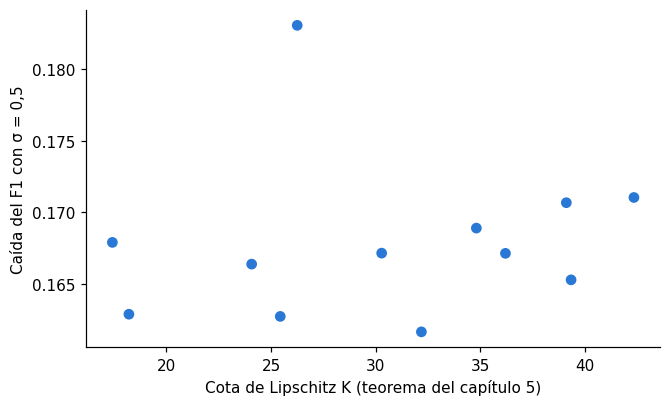

In [47]:
p4 = pd.read_csv(R / "robustez/p4_sensibilidad_tau.csv")
display(p4.groupby("tau_min").mean(numeric_only=True).drop(columns="semilla"))
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.scatter(p4["cota K"], p4["caída con ruido σ=0.5"], c=[AZUL] * len(p4))
for s in (0.1, 0.3, 0.5):
    r = stats.spearmanr(p4["cota K"], p4[f"caída con ruido σ={s}"])
    print(f"σ = {s}: Spearman entre K y la caída = {r.statistic:+.2f} (p = {r.pvalue:.2f})")
ax.set_xlabel("Cota de Lipschitz K (teorema del capítulo 5)"); ax.set_ylabel("Caída del F1 con σ = 0,5")
plt.tight_layout(); plt.show()

**P4 es falsa: al subir τ_min de 0,02 a 0,2 la cota K baja de 39,3 a 20,6, como predice el teorema, pero la caída del F1 con ruido σ = 0,5 no cambia (se mantiene entre 0,166 y 0,171, sin tendencia), y la correlación de Spearman entre K y la caída no es significativa en ningún nivel de ruido (*p* entre 0,23 y 0,86).**

Esto significa que la cota es válida, porque se verifica numéricamente en el capítulo 5, pero es demasiado holgada para ordenar las variantes por su robustez real: K es un peor caso global, producto de normas espectrales, y el ruido gaussiano explora sobre todo la región donde la red es mucho más suave que ese peor caso. La robustez del original frente a LightGBM, que sí es clara, viene de la suavidad de toda la arquitectura y no de las diferencias de K dentro del barrido.

En consecuencia, la propiedad demostrada se presenta como una garantía teórica sin consecuencia práctica medible en este problema, y una cota más fina (local o certificada por intervalos) queda como trabajo futuro.

### Sensibilidad del diseño (validación)

In [48]:
sens = pd.read_csv(R / "adecuacion/sensibilidad.csv")
sens["diseño congelado"] = sens["variante"].eq("tau_min0.05")
sens

,variante,semillas,f1_val,de,f1_ent,epocas,diseño congelado
0,T16,3,0.9210,0.0061,0.9294,10.0000,False
1,T4,3,0.9310,0.0029,0.9326,12.3333,False
2,gamma0.0,3,0.9195,0.0074,0.9233,9.0000,False
3,gamma0.1,3,0.9198,0.0069,0.9229,9.0000,False
4,tau_min0.02,3,0.9176,0.0072,0.9243,9.0000,False
5,tau_min0.05,3,0.9192,0.0072,0.9231,9.0000,True
6,tau_min0.1,3,0.9215,0.0065,0.9238,9.6667,False
7,tau_min0.2,3,0.9280,0.0058,0.9233,9.6667,False


**Sobre la validación y con tres semillas, el diseño congelado (T = 8, τ_min = 0,05, γ = 0,01) obtiene un F1 de 0,919, y dos variantes lo superan en más de δ: T = 4 escalones (0,931) y τ_min = 0,2 (0,928). El término de balance γ no cambia el resultado (0,920 con γ = 0 y con γ = 0,1).**

Hay que tener en cuenta que son solo tres semillas y la partición de validación, y que el diseño se congeló antes en la partición de desarrollo (capítulo 5); este barrido es posterior y no se usa para cambiarlo, porque eso sería diseñar mirando resultados que ya incluyen la prueba. La dirección, sin embargo, coincide con la ablación: menos escalones y más suaves funcionan mejor, y el codificador de escalones, tal como se congeló, resta en lugar de sumar.

Con base en esto, se propone como trabajo futuro un diseño con T = 4 y τ_min ≥ 0,2, evaluado con un protocolo nuevo y preregistrado.

### Adecuación del modelo original (condición 5)

In [49]:
pd.read_csv(R / "adecuacion/adecuacion_con_e2.csv")

,Modelo,(i) Supera al trivial,(ii) Brecha < δg,"(iii) ECE con temperatura < 0,05",Pendiente media,(iv) Prueba consistente con validación,Adecuado
0,Original,sí,sí,no,0.7261,sí,no
1,DNN,sí,sí,no,0.6632,sí,no
2,CNN 1D,sí,sí,no,0.6725,sí,no
3,LSTM,sí,sí,no,0.7841,sí,no
4,CNN-LSTM,sí,sí,sí,0.7730,sí,sí
5,Autoencoder,sí,sí,sí,0.5821,sí,sí
6,RNN,sí,sí,no,0.6159,sí,no
7,Transformer,sí,sí,sí,0.7376,sí,sí
8,BiLSTM,sí,sí,sí,0.6904,sí,sí
9,ResNet,sí,sí,no,0.5899,sí,no


In [50]:
a = adec["adecuación del original (sección 7.2 del E2)"]
pm, ob, ie = adec["permutación de etiquetas"], adec["optimismo por bootstrap"], adec["validación anidada (aproximación del E2)"]
pd.DataFrame({
    "valor": [f"{a['F1 trivial']:.3f} (p = {a['p (i)']:.1e})", f"{a['Brecha g']:.4f} (p = {a['p Wilcoxon (g < δg)']:.1e})",
              f"{a['ECE']:.4f} → {a['ECE con T']:.4f} (T = {a['T media']:.3f})", f"{a['Pendiente media']:.3f}",
              f"{a['Validación − prueba']:.4f}, IC [{a['IC 95 % por bloques'][0]:.3f}; {a['IC 95 % por bloques'][1]:.3f}]",
              f"{pm['F1 observado (semilla 6001)']:.3f} frente a máx. {pm['F1 permutado máximo']:.3f} (p = {pm['p']:.3f}, {pm['permutaciones']} permutaciones)",
              f"{ob['Original']['optimismo medio']:.4f} {tuple(ob['Original']['IC 95 %'])}; LightGBM {ob['LightGBM']['optimismo medio']:.4f}",
              f"{ie['Original']['interno − externo']:.4f} (E2: de {min(ie['E2 (mismo cálculo)'].values()):.3f} a {max(ie['E2 (mismo cálculo)'].values()):.3f})",
              f"{adec['curva de aprendizaje']['Original']['pendiente por log n']:+.5f} (p = {adec['curva de aprendizaje']['Original']['p']:.2f})"]},
    index=["(i) F1 del trivial", "(ii) Brecha entrenamiento − validación", "(iii) ECE antes → después de la temperatura", "Pendiente de calibración (media de clases)",
           "(iv) Validación − prueba", "Permutación de etiquetas", "Optimismo por bootstrap (20 réplicas)", "Validación anidada: ajuste − prueba",
           "Curva de aprendizaje: pendiente por log n"])

,valor
(i) F1 del trivial,0.070 (p = 1.6e-38)
(ii) Brecha entrenamiento − validación,0.0044 (p = 9.5e-07)
(iii) ECE antes → después de la temperatura,0.0482 → 0.0527 (T = 0.917)
Pendiente de calibración (media de clases),0.726
(iv) Validación − prueba,"0.0706, IC [-0.048; 0.191]"
Permutación de etiquetas,"0.855 frente a máx. 0.434 (p = 0.005, 200 permutaciones)"
Optimismo por bootstrap (20 réplicas),"0.0232 (-0.0051, 0.0695); LightGBM 0.0434"
Validación anidada: ajuste − prueba,0.0763 (E2: de 0.013 a 0.096)
Curva de aprendizaje: pendiente por log n,-0.00012 (p = 0.94)


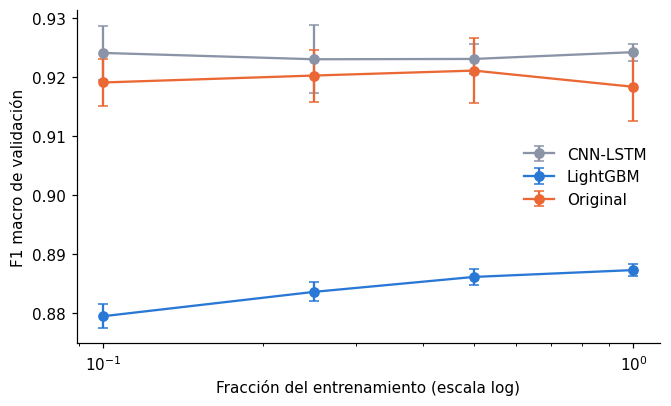

In [51]:
cur = pd.read_csv(R / "adecuacion/curvas.csv")
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for m, g in cur.groupby("modelo"):
    ax.errorbar(g["fraccion"], g["f1_val"], yerr=g["de"], marker="o", capsize=3, label=m,
                color=NARANJA if m == "Original" else (AZUL if m == "LightGBM" else GRIS))
ax.set_xscale("log"); ax.set_xlabel("Fracción del entrenamiento (escala log)"); ax.set_ylabel("F1 macro de validación")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**El original cumple tres de las cuatro condiciones de adecuación del E2: supera al trivial (0,850 frente a 0,070), su brecha entre entrenamiento y validación es de 0,004, muy por debajo de δg = 0,05, y la diferencia entre validación y prueba tiene un IC por bloques que contiene al cero. Falla la calibración por un margen mínimo: su ECE con temperatura es de 0,053 frente al umbral de 0,05.**

Así mismo, la prueba de permutación confirma que aprende señal real (F1 de 0,855 frente a un máximo de 0,434 con etiquetas permutadas, *p* = 0,005, el mínimo posible con 200 permutaciones), la diferencia entre el mejor F1 de validación del ajuste y el F1 de prueba (0,076), que aproxima la validación anidada como en el E2, está en el rango de las redes (de 0,069 a 0,096, frente a 0,013 de LightGBM), su optimismo por *bootstrap* (0,023) es del orden del de las redes y la mitad del de LightGBM (0,043), y su curva de aprendizaje es plana: con el 10 % del entrenamiento ya alcanza el F1 de validación que obtiene con todo, mientras que LightGBM sigue mejorando con más datos (pendiente significativa, *p* < 0,001). Hosmer-Lemeshow rechaza en las cinco clases, pero con 22 883 flujos rechaza cualquier desviación mínima, por lo que se reporta junto con la pendiente de calibración (0,73), que indica probabilidades algo extremas. La temperatura ajustada en validación es menor que 1 y no corrige ese sesgo en la prueba.

Por tal motivo, el original se declara no adecuado según el criterio del E2, con la misma salvedad que ese entregable: el umbral del ECE es exploratorio, y 9 de los 15 modelos del E2 fallan esa misma condición. La condición 5 de R3 tampoco se cumpliría, aun si el original superara a la familia.

#### Calibración y predicción conforme

In [52]:
cal = json.loads((RAIZ / "artifacts/dashboard/calibracion.json").read_text(encoding="utf-8"))
pd.DataFrame({m: v for m, v in cal.items() if not m.startswith("_")}).T[["temperatura", "ece_antes", "ece_despues", "cobertura_prueba", "tamano_medio_conjunto"]].sort_values("cobertura_prueba")

,temperatura,ece_antes,ece_despues,cobertura_prueba,tamano_medio_conjunto
Logística,1.0148,0.0440,0.0423,0.8167,1.0137
ResNet,1.0578,0.0607,0.0594,0.8174,0.9442
TabNet,0.8822,0.0542,0.0637,0.8297,0.9920
DNN,1.0310,0.0474,0.0473,0.8300,0.9384
CNN 1D,0.9723,0.0422,0.0435,0.8322,0.9358
GRU,1.0153,0.0441,0.0436,0.8323,0.9353
DBN,1.0655,0.0498,0.0476,0.8325,0.9382
RNN,1.2057,0.0662,0.0535,0.8332,0.9651
KAN,0.8424,0.0484,0.0491,0.8339,0.9443
CNN-LSTM,0.8921,0.0446,0.0453,0.8438,0.9376


**Con predicción conforme LAC calibrada en validación para una cobertura nominal del 90 %, ningún modelo la alcanza en la prueba: la cobertura va de 0,817 (ResNet y la regresión logística) a 0,890 (LightGBM), y la del original es de 0,846 con conjuntos de 0,96 clases en promedio.**

Esto significa que la garantía de la predicción conforme, que supone que validación y prueba son intercambiables, se rompe en UAVIDS-2025 por la misma dependencia de escenario que explica la brecha entre validación y prueba. No es un defecto de un modelo en particular, sino de la partición.

Por lo anterior, el dashboard muestra los conjuntos conformes con la advertencia de que su cobertura real medida es menor que la nominal, y reporta la cobertura observada de cada modelo.

#### Los mismos diagnósticos en cada conjunto adicional

In [53]:
diag = adec.get("diagnósticos en cada conjunto adicional")
if diag:
    tabla_diag = pd.DataFrame({c: {**{k: v for k, v in d.items() if k != "permutación"}, "p de permutación": d["permutación"]["p"],
                                   "F1 permutado máximo": d["permutación"]["F1 permutado máximo"]} for c, d in diag.items()}).T
    display(tabla_diag)
else:
    print("Pendiente: training/ejecutar_diagnosticos_adicionales.py")

,reproducción: F1 de prueba idéntico al registrado,F1 prueba,F1 trivial (clase mayoritaria),(i) supera al trivial,brecha g,p Wilcoxon (g < δg),(ii) brecha < δg,ECE,ECE con T,"(iii) ECE con T < 0,05",pendiente media de calibración,validación − prueba,IC 95 % por bloques,(iv) prueba consistente con validación,adecuado,p de permutación,F1 permutado máximo
UAV-NIDD,True,0.5496,0.0921,True,0.324,1.0,False,0.0802,0.0897,False,4.2525,0.0081,"[-0.3264943083807587, 0.34020963041299646]",True,False,0.005,0.4881
UNSW-NB15,True,0.6651,0.0293,True,0.0153,0.001,True,0.0341,0.0424,True,1.0402,-0.0194,"[-0.13130451878768443, 0.09644280568293215]",True,True,0.005,0.2311
UNR-IDD,True,0.7646,0.0701,True,0.0097,0.001,True,0.0348,0.0187,True,1.7743,0.0064,"[-0.10942211942484723, 0.09804183377552315]",True,True,0.005,0.2737


**Al repetir los diagnósticos del E2 en cada conjunto adicional, el original es adecuado en UNSW-NB15 y en UNR-IDD, donde cumple las cuatro condiciones, y no lo es en UAV-NIDD: ahí la brecha entre entrenamiento y validación es de 0,32 (F1 de 0,89 en entrenamiento frente a 0,56 en validación) y el ECE con temperatura es de 0,090. En los tres conjuntos supera al trivial y a las 200 permutaciones de etiquetas (*p* = 0,005), y los 30 reentrenamientos reproducen bit a bit el F1 de prueba registrado.**

Esto significa que en UAV-NIDD el original memoriza las ejecuciones de ataque del entrenamiento y no las transfiere a las de validación y prueba, que son otras ejecuciones, porque los bloques de 250 filas se reparten sin compartir ninguno. Es la misma dependencia de escenario de UAVIDS-2025, y explica por qué todos los modelos quedan entre 0,49 y 0,62 de F1 en ese conjunto. Además, la mejor permutación llega a 0,488 frente a 0,541 observado: la señal aprendida existe, pero el margen sobre el azar es pequeño.

Por esta razón, la adecuación del original depende del conjunto: se cumple donde la validación representa a la prueba (UNSW-NB15 y UNR-IDD) y falla donde las particiones separan ejecuciones de ataque muy distintas, lo que refuerza el hallazgo principal del capítulo 10.

### Robustez a la elección de la prueba (condición 6)

In [54]:
pd.DataFrame(adec["Nadeau-Bengio y F 5x2cv (condición 6)"]).T

,particiones,diferencia media,t Nadeau-Bengio,p Nadeau-Bengio,F 5x2cv,p F 5x2cv
LightGBM,10.0,0.0002,0.0098,0.9924,0.6108,0.7631
CNN 1D,10.0,0.0006,0.0324,0.9748,1.3472,0.3907


**Con la *t* de Nadeau-Bengio y la *F* de 5 × 2 cv sobre las diez particiones de la validación cruzada del E2, el original no se distingue de LightGBM (diferencia media de +0,0002, *p* = 0,99) ni de CNN 1D (+0,0006, *p* = 0,97): los tres obtienen un F1 medio de 0,860.**

Esto quiere decir que la conclusión principal es robusta a la elección de la prueba, porque ninguna, paramétrica o no paramétrica, con o sin la corrección de Nadeau-Bengio, muestra que el original supere a un rival. En cambio, la ventaja de LightGBM sobre el original, que en la prueba sellada es de 0,027 y respaldan las seis pruebas admisibles del capítulo 7, desaparece cuando la partición cambia.

Por tal motivo, y como exige la condición 6 de la sección 8.4 del enunciado, la superioridad de LightGBM sobre el original se reporta como un resultado no robusto a la partición: depende de qué escenarios de simulación quedaron en la prueba sellada, igual que la brecha entre validación y prueba.

### Escalabilidad, incertidumbre e interpretabilidad

Tres contenidos del cuadro 7 para este capítulo están desarrollados en otros lugares del libro y aquí solo se enlazan:

- **Escalabilidad.** El costo del original crece de forma lineal con el número de atributos y su tiempo por flujo se estabiliza en microsegundos con lotes grandes (capítulo 6, sección de complejidad). La curva de aprendizaje de este capítulo muestra la otra cara: con el 10 % del entrenamiento ya alcanza su F1 de validación.
- **Incertidumbre.** Además de la calibración y la predicción conforme de este capítulo, la dispersión entre semillas se reporta con media, DE e IC 95 % en la tabla de líderes (capítulo 3) y en cada conjunto adicional.
- **Interpretabilidad.** Los valores de Shapley, la fidelidad por borrado y la estabilidad de las explicaciones entre semillas están en el capítulo 6, junto con el peso de la compuerta por clase.

### Eficiencia y frontera de Pareto

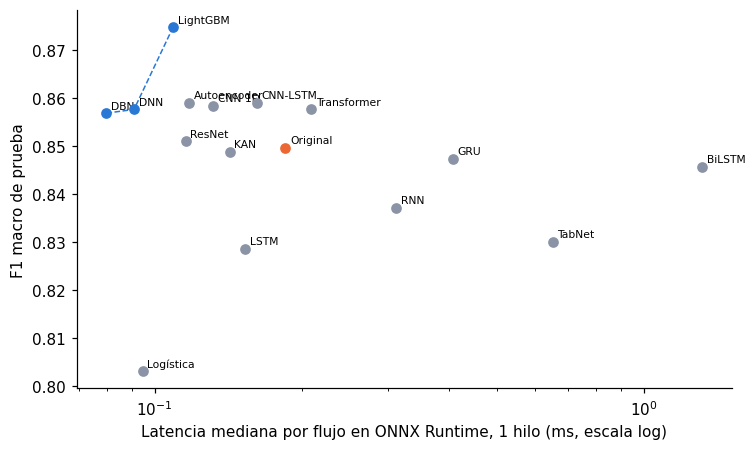

,Modelo,F1 macro,Latencia mediana (ms),Latencia p95 (ms),Parámetros,FLOPs,Entrenamiento (s),Pareto
6,DBN,0.8569,0.0797,0.1422,9733,1.9072e+04,110.3980,True
4,DNN,0.8577,0.0907,0.1465,12677,2.4896e+04,40.9205,True
15,Logística,0.8030,0.0946,0.1998,85,NaN,40.3100,False
0,LightGBM,0.8748,0.1091,0.1448,35516,NaN,14.4875,True
7,ResNet,0.8510,0.1158,0.1575,14245,2.6944e+04,48.7470,False
1,Autoencoder,0.8591,0.1177,0.2079,19093,1.9072e+04,35.3220,False
3,CNN 1D,0.8584,0.1318,0.2094,39493,2.6586e+05,118.0715,False
9,KAN,0.8488,0.1423,0.2386,4845,9.3760e+03,96.3330,False
14,LSTM,0.8285,0.1533,0.2598,17477,5.3312e+05,157.9465,False
2,CNN-LSTM,0.8591,0.1618,0.3085,46213,9.2429e+05,215.1702,False


In [55]:
lid = pd.read_csv(RAIZ / "artifacts/dashboard/lideres.csv")
lid = lid.dropna(subset=["Latencia mediana (ms)"]).sort_values("Latencia mediana (ms)")
lid["Pareto"] = lid["F1 macro"] > lid["F1 macro"].cummax().shift(fill_value=-1)
fig, ax = plt.subplots(figsize=(7, 4.2))
for _, f in lid.iterrows():
    ax.scatter(f["Latencia mediana (ms)"], f["F1 macro"], color=NARANJA if f["Modelo"] == "Original" else (AZUL if f["Pareto"] else GRIS), zorder=3)
    ax.annotate(f["Modelo"], (f["Latencia mediana (ms)"], f["F1 macro"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
frontera = lid[lid["Pareto"]]
ax.plot(frontera["Latencia mediana (ms)"], frontera["F1 macro"], color=AZUL, lw=1, ls="--")
ax.set_xscale("log"); ax.set_xlabel("Latencia mediana por flujo en ONNX Runtime, 1 hilo (ms, escala log)"); ax.set_ylabel("F1 macro de prueba")
plt.tight_layout(); plt.show()
lid[["Modelo", "F1 macro", "Latencia mediana (ms)", "Latencia p95 (ms)", "Parámetros", "FLOPs", "Entrenamiento (s)", "Pareto"]]

**La frontera de Pareto entre F1 y latencia la forman DBN (0,080 ms), DNN (0,091 ms) y LightGBM (0,109 ms, el mejor F1). El original, con 0,185 ms por flujo, queda dominado: hay modelos más rápidos y con mayor F1.**

Hay que tener en cuenta que todas las latencias están por debajo de 2 ms por flujo en un solo hilo de CPU, incluida la BiLSTM, la más lenta (1,3 ms), de modo que cualquiera de los 16 modelos procesa varios miles de flujos por segundo y la latencia no es una restricción para el dashboard. El original tiene 14 908 parámetros y 29 056 FLOPs por flujo, del orden de las redes densas y 36 veces menos parámetros que la BiLSTM.

Por esta razón, la elección entre modelos se decide por el desempeño y la robustez, no por el costo de inferencia, y el capítulo 10 recoge esa elección.

### Balance de las seis condiciones de R3

In [56]:
c4 = json.loads((R / "confirmatorio/sensibilidad_cuadro4.json").read_text(encoding="utf-8"))
conf = json.loads((R / "confirmatorio/resumen.json").read_text(encoding="utf-8"))
pd.DataFrame([
    {"condición": "1. Métrica media favorable frente a cada rival", "cumple": "no", "evidencia": f"F1 medio menor que el de {len(c4['rivales con media mayor que la del original'])} de los 12 rivales"},
    {"condición": "2. Tres pruebas con Holm y diferencia > δ", "cumple": "no", "evidencia": "ningún contraste con tres pruebas, ni con las preregistradas ni con las admisibles del cuadro 4"},
    {"condición": "3. Efecto no despreciable e IC > 0", "cumple": "no", "evidencia": "solo frente a TabNet y RNN hay efecto a favor no despreciable"},
    {"condición": "4. Consistencia en los conjuntos adicionales", "cumple": "no", "evidencia": f"mejor en {res_ad['conjuntos en que el original es el mejor en la media']} de 3; peor con significancia en UNSW-NB15"},
    {"condición": "5. Adecuación del modelo (E2, sección 7.2)", "cumple": "no", "evidencia": "en UAVIDS-2025 cumple (i), (ii) y (iv) y falla (iii) por ECE de 0,053 frente a 0,05; adecuado en UNSW-NB15 y UNR-IDD, no en UAV-NIDD"},
    {"condición": "6. Robustez a la elección de la prueba", "cumple": "sí (para la conclusión principal)", "evidencia": "ninguna prueba muestra superioridad del original; la ventaja de LightGBM no es robusta a la partición"},
])

,condición,cumple,evidencia
0,1. Métrica media favorable frente a cada rival,no,F1 medio menor que el de 8 de los 12 rivales
1,2. Tres pruebas con Holm y diferencia > δ,no,"ningún contraste con tres pruebas, ni con las preregistradas ni con las admisibles del cuadro 4"
2,3. Efecto no despreciable e IC > 0,no,solo frente a TabNet y RNN hay efecto a favor no despreciable
3,4. Consistencia en los conjuntos adicionales,no,mejor en 0 de 3; peor con significancia en UNSW-NB15
4,"5. Adecuación del modelo (E2, sección 7.2)",no,"en UAVIDS-2025 cumple (i), (ii) y (iv) y falla (iii) por ECE de 0,053 frente a 0,05; adecuado en UNSW-NB15 y UNR-IDD, no en UAV-NIDD"
5,6. Robustez a la elección de la prueba,sí (para la conclusión principal),ninguna prueba muestra superioridad del original; la ventaja de LightGBM no es robusta a la partición


**El modelo original no cumple R3: falla las condiciones 1 a 5, y la condición 6 confirma que esa conclusión no depende de la prueba elegida. El tope de calificación es 4,0 (sección 14.1 del enunciado).**

En síntesis, la evidencia de los cuatro conjuntos y de las seis pruebas admisibles apunta en la misma dirección: el original es una red del grupo intermedio, más robusta que el resto ante ruido y atributos faltantes, sin una ventaja de desempeño que resista la comparación con la familia completa.

Por lo anterior, el trabajo se sostiene en el hallazgo alternativo preregistrado en la sección 12 del protocolo, que el capítulo 10 desarrolla.

## Capítulo 9. Dashboard y despliegue

El dashboard es una aplicación multipágina de Dash (`use_pages=True`) que se despliega en Render, en **https://uavids-2025-dashboard.onrender.com**, y hace inferencia en CPU con ONNX Runtime. Nunca entrena ni importa PyTorch: carga los artefactos de `artifacts/` y los precalculados de `artifacts/dashboard/`.

### Arquitectura

| Capa | Archivos | Qué hace |
|---|---|---|
| Interfaz | `app.py`, `pages/contexto.py`, `pages/eda.py`, `pages/modelos.py`, `assets/estilos.css` | Una página por sección, barra de navegación y pie con el enlace a este libro |
| Inferencia | `src/inference.py` | Carga bajo demanda de las sesiones ONNX (como mucho 6 vivas), preprocesamiento del E1, *temperature scaling*, conjunto conforme LAC al 90 %, aviso fuera de dominio y explicación local por oclusión |
| Datos y figuras | `src/data.py`, `src/plots.py` | Caché de los datos precalculados y una plantilla común de Plotly con la misma paleta por clase en todas las páginas |
| Precálculo | `training/exportar_onnx.py`, `training/preparar_dashboard.py` | Exportación con prueba de ida y vuelta, calibración y conformal ajustados en validación, diagnósticos, tabla de líderes **alimentada desde la tabla maestra** (`experiments/resultados/tabla_maestra.csv`), conjuntos adicionales, robustez y balance de R3 |
| Pruebas | `tests/test_dashboard.py` | Páginas, probabilidades válidas, coherencia con los metadatos, fuera de dominio, ida y vuelta y **consistencia automática con la tabla maestra y con el análisis de los conjuntos adicionales**, en integración continua |

### Contenido de cada sección

- **Contexto:** portada con la cifra clave, por qué importa, preguntas de investigación, ficha de datos, flujo metodológico, limitaciones, ética y autoría.
- **EDA:** filtros de atributo, clase, partición y escala que actualizan con *callbacks* el balance de clases, la distribución por clase, el panel de estructura por escenario (el específico de este problema), el cambio de distribución entre particiones y la correlación de Spearman. Cada figura tiene su interpretación.
- **Modelos:**
  - tabla de líderes con los 10 del Top 10, los *baselines* y el modelo original, ordenable y filtrable;
  - intervalos del F1 por modelo;
  - predicción en vivo con un flujo de prueba al azar o editado a mano, con probabilidades calibradas, conjunto conforme, aviso fuera de dominio y explicación local;
  - diagnósticos del modelo elegido: matriz de confusión, curva de confiabilidad y F1 por clase frente a LightGBM;
  - tabla de contrastes confirmatorios y diagrama de diferencia crítica;
  - F1 de los 13 modelos en los tres conjuntos adicionales, sin promediar conjuntos;
  - robustez ante ruido, atributos faltantes y valores atípicos, con selector de perturbación;
  - balance de las seis condiciones de R3;
  - ficha del modelo original con su pseudocódigo.

In [57]:
from pathlib import Path
import pandas as pd
RAIZ = Path("..").resolve()
lideres = pd.read_csv(RAIZ / "artifacts/dashboard/lideres.csv")
tamanos = {p.parent.name: round(p.stat().st_size / 1024, 1) for p in (RAIZ / "artifacts").glob("*/model.onnx")}
lideres["ONNX (KB)"] = lideres["Modelo"].str.replace(" ", "_").str.replace("í", "i").map(tamanos)
print(f"Tamaño total de los modelos ONNX: {sum(tamanos.values()) / 1024:.1f} MB")
lideres[[c for c in ["Modelo", "Grupo", "Parámetros", "ONNX (KB)", "Latencia mediana (ms)", "Latencia p95 (ms)"] if c in lideres]]

Tamaño total de los modelos ONNX: 4.7 MB


,Modelo,Grupo,Parámetros,ONNX (KB),Latencia mediana (ms),Latencia p95 (ms)
0,LightGBM,Baseline fuerte,35516,1310.0,0.1091,0.1448
1,Autoencoder,Top 10,19093,39.5,0.1177,0.2079
2,CNN-LSTM,Top 10,46213,183.3,0.1618,0.3085
3,CNN 1D,Baseline del E1,39493,156.0,0.1318,0.2094
4,DNN,Base del E1,12677,50.6,0.0907,0.1465
5,Transformer,Top 10,3381,26.2,0.2089,0.3447
6,DBN,Top 10,9733,39.0,0.0797,0.1422
7,ResNet,Top 10,14245,62.9,0.1158,0.1575
8,Original,Modelo original,14908,63.8,0.1851,0.3129
9,KAN,Top 10,4845,26.5,0.1423,0.2386


### Memoria y rendimiento en el plan gratuito

Los 16 modelos ocupan unos 5 MB en ONNX, así que caben sin cuantizar. Aun así, las sesiones se cargan bajo demanda y se limitan a seis vivas, ONNX Runtime corre con un solo hilo, y los datos del EDA (6,7 MB en Parquet) se cargan una sola vez al iniciar. La aplicación no carga PyTorch, scikit-learn ni LightGBM: solo `onnxruntime`, `dash`, `plotly`, `pandas` y `pyarrow` (`requirements.txt`).

### Despliegue en Render

1. El repositorio de GitHub contiene los tres entregables; `render.yaml` apunta el servicio a la carpeta `Entregable_3_UAVIDS_2025` con `rootDir`.
2. Render instala `requirements.txt` y arranca con `gunicorn app:server --workers 1 --threads 4 --timeout 120`; `healthCheckPath: /` verifica que la portada responda.
3. Las variables `OMP_NUM_THREADS`, `OPENBLAS_NUM_THREADS` y `MKL_NUM_THREADS` se fijan en 1 para no competir por la CPU compartida del plan gratuito.
4. El servicio se creó el 23/11/2026 desde el repositorio público, rama `entregable-3`, con los mismos valores de `render.yaml`. En el plan gratuito se duerme tras 15 minutos sin visitas y tarda cerca de un minuto en despertar.

**Prueba de humo.** Después de cada despliegue, `verificacion_externa/humo_dashboard.py` llama contra la URL pública a los mismos *callbacks* que usa el navegador: verifica que las tres páginas respondan con código 200, que un flujo de prueba al azar dé con cada uno de los 16 modelos probabilidades que sumen 1 y que un flujo absurdo active el aviso fuera de dominio. El mismo script corre contra el contenedor local con `--url http://localhost:8050`.

In [58]:
import json
humo = json.loads((RAIZ / "experiments/resultados/humo_dashboard.json").read_text(encoding="utf-8"))
print(f"{humo['fecha_utc']} | {humo['url']} | resultado: {'OK' if humo['todo_ok'] else 'FALLA'}")
print("Páginas:", {p: v["codigo"] for p, v in humo["paginas"].items()}, "|", humo["flujo_de_prueba"])
print("Aviso fuera de dominio con el flujo absurdo:", humo["flujo_absurdo"]["aviso_activo"])
pd.DataFrame([{"Modelo": m, "Suma de probabilidades": v["suma_probabilidades"], "Aviso fuera de dominio": v["aviso_fuera_de_dominio"],
               "Respuesta (s)": v["segundos"]} for m, v in humo["modelos"].items()])

2026-11-23T16:08:33+00:00 | https://uavids-2025-dashboard.onrender.com | resultado: OK
Páginas: {'/': 200, '/eda': 200, '/modelos': 200} | Flujo de prueba FlowID 73 019 · clase real: Normal
Aviso fuera de dominio con el flujo absurdo: True


,Modelo,Suma de probabilidades,Aviso fuera de dominio,Respuesta (s)
0,Autoencoder,1.0,False,0.251
1,BiLSTM,1.0,False,0.327
2,CNN 1D,1.0,False,0.269
3,CNN-LSTM,1.0,False,0.259
4,DBN,1.0,False,0.266
5,DNN,1.0,False,0.260
6,GRU,1.0,False,0.238
7,KAN,1.0,False,0.274
8,LSTM,1.0,False,0.215
9,LightGBM,1.0,False,0.418


### Seguridad y robustez de la interfaz

Las entradas numéricas se validan: un valor vacío no dispara la predicción y uno fuera de rango activa el aviso. La aplicación no guarda datos del usuario ni usa almacenamiento externo. Las explicaciones por oclusión cuestan 16 inferencias por predicción, unos pocos milisegundos en CPU.

## Capítulo 10. Conclusiones, limitaciones y trabajo futuro

In [59]:
import json
from pathlib import Path
import pandas as pd
RAIZ = Path("..").resolve()
R = RAIZ / "experiments/resultados"
conf = json.loads((R / "confirmatorio/resumen.json").read_text(encoding="utf-8"))
c4 = json.loads((R / "confirmatorio/sensibilidad_cuadro4.json").read_text(encoding="utf-8"))
ad = json.loads((R / "adicionales/resumen.json").read_text(encoding="utf-8"))
adec = json.loads((R / "adecuacion/resumen.json").read_text(encoding="utf-8"))
print("Preparación del capítulo 10 ejecutada. Quedan definidos: json, Path, pd, RAIZ, R, conf, c4, ad, adec")

Preparación del capítulo 10 ejecutada. Quedan definidos: json, Path, pd, RAIZ, R, conf, c4, ad, adec


### Hallazgos

1. **El modelo original no supera a la familia de contrastes.** Con 48 semillas obtiene un F1 macro de 0,850 ± 0,012 en la prueba sellada, menor que el de 8 de los 12 rivales, y ningún contraste rechaza con tres pruebas, ni con las preregistradas ni con las seis admisibles del cuadro 4 (capítulo 7). En los conjuntos adicionales no es el mejor en ninguno y en UNSW-NB15 pierde con significancia frente a tres rivales (capítulo 8).
2. **LightGBM es el modelo más fuerte en la prueba sellada, pero su ventaja no es robusta a la partición.** Gana en UAVIDS-2025 (0,875), en UNSW-NB15 y en UNR-IDD, y tiene el mejor rango medio entre conjuntos. Sin embargo, en la validación cruzada 5 × 2 su F1 medio (0,860) es igual al del original y al de CNN 1D (*p* de Nadeau-Bengio de 0,99 y 0,97).
3. **El escenario de simulación pesa más que la arquitectura.** El 70,5 % de las filas de prueba pertenece a escenarios vistos en el entrenamiento (dependencia L3.2, capítulo 1), ningún modelo reconoce el escenario de Sybil aislado (acierto entre 4,8 % y 9,4 %, P5 cierta), la predicción conforme pierde su cobertura nominal en todos los modelos (de 0,82 a 0,89 frente al 0,90 declarado) y la ventaja de LightGBM desaparece al cambiar la partición.
4. **El mecanismo no funciona como se predijo.** La compuerta sí especializa a los expertos (P2: el 88 % del peso de Wormhole y el 69 % de Blackhole van al experto de umbrales), pero ese experto es el que peor separa esas dos clases: quitar el codificador de escalones mejora el F1 de 0,848 a 0,862 (P1 falsa) y la desventaja frente a CNN-LSTM se concentra justo en Blackhole y Wormhole (P3 falsa).
5. **El original es el modelo más robusto ante ruido y atributos faltantes**, con una caída de 0,182 frente a 0,324 de LightGBM con ruido σ = 0,5 y de 0,330 frente a 0,408 con la mitad de los atributos imputados. **Pero la cota de Lipschitz demostrada no explica esa robustez:** al bajar K de 39 a 21 la degradación no cambia (P4 falsa).
6. **El original es adecuado en tres de las cuatro condiciones del E2:** supera al trivial, no sobreajusta (brecha de 0,004) y su prueba es consistente con la validación; falla la calibración por 0,003 (ECE con temperatura de 0,053 frente a 0,05), como 9 de los 15 modelos del E2. En los conjuntos adicionales es adecuado en UNSW-NB15 y UNR-IDD, y no en UAV-NIDD, donde memoriza las ejecuciones de ataque del entrenamiento (F1 de 0,89 en entrenamiento frente a 0,56 en validación). Los 30 reentrenamientos de control reproducen bit a bit el F1 registrado.

### Veredicto sobre R1, R2 y R3

| Condición | Veredicto | Evidencia |
|---|---|---|
| **R1. Novedad para el problema** | Se cumple | La búsqueda en OpenAlex, IEEE Xplore y arXiv (cadenas N1 a N7, capítulo 4), confirmada en Scopus y Web of Science, y con búsqueda por citación y en repositorios de código, no encontró estudios que apliquen a intrusiones en redes de UAV una compuerta por flujo entre un experto de escalones suaves y uno neuronal, entrenada de forma cooperativa. La diferencia con los trabajos más cercanos (la compuerta entre LightGBM y un Transformer de ACGE en fog-IoT, la fusión por pares PS-CAHE y el *stacking* sobre UAVIDS-2025, y las mezclas de expertos homogéneos en 5G y en Switch IDS) es de mecanismo y de entrenamiento, no solo de aplicación. La verificación por un tercero queda a cargo de los profesores del curso, por indicación suya (capítulo 4). |
| **R2. Mecanismo propio, sin `import` ni código de terceros** | Se cumple | El mecanismo está programado desde su formulación en `src/original_model.py`, con PyTorch solo como motor tensorial, y lo cubren 14 pruebas unitarias (capítulo 6). La propiedad (cota de Lipschitz de la mezcla) está demostrada y verificada numéricamente (capítulo 5). |
| **R3. Superioridad estadística sobre la familia** | **No se cumple** | Fallan las condiciones 1 a 5 de la sección 8.4 del enunciado y la condición 6 confirma que la conclusión no depende de la prueba (capítulo 8). |

**Tope de calificación: 4,0** (sección 14.1 del enunciado: R1 sí, R2 sí, R3 no).

### Hallazgo alternativo

Como se fijó en la sección 12 del protocolo antes de las corridas definitivas, el trabajo se sostiene en tres aportes que no dependen de que el original gane:

1. **Un *benchmark* riguroso y preregistrado de 13 modelos** en el problema principal y en tres conjuntos adicionales, con el mismo presupuesto de ajuste, potencia por contraste, Holm por familia, seis pruebas admisibles y una tabla maestra con una fila por corrida (capítulo 11). Los reentrenamientos de control dieron el mismo F1, bit a bit, que las corridas registradas.
2. **La explicación de por qué el escenario pesa más que la arquitectura en UAVIDS-2025**, con tres evidencias independientes: la auditoría de fuga L3.2, la prueba de D3 por escenario no visto (ningún mecanismo de invariancia lo resolvió) y la desaparición de la ventaja de LightGBM en 5 × 2. La consecuencia práctica es que los *rankings* publicados sobre una sola partición de este conjunto, incluido el del E2, miden en buena parte qué escenarios cayeron en la prueba. Dos trabajos de 2026 llegan a lo mismo por otros caminos: la fusión PS-CAHE pierde su ventaja cuando se evalúa con nodos disjuntos (Ma et al., 2026), y la detección de Sybil en un benchmark público de UAV solo se sostiene con una evaluación sin fugas de identificadores (Aksu y Gümüş, 2026).
3. **La medición de cuánto cierra la brecha entre árboles y redes un experto con escalones suaves y cuándo ayuda la compuerta.** El oráculo que elige flujo por flujo entre un árbol y una red llega a 0,871 en desarrollo, frente a 0,845 de LightGBM, de modo que la selección por flujo tiene margen real; pero la compuerta aprendida no lo alcanza y el codificador de escalones, tal como se diseñó, resta. Es un resultado negativo bien medido, que acota el espacio de diseño para el siguiente intento.

### Amenazas a la validez

- **Validez interna.** La prueba sellada comparte escenarios de simulación con el entrenamiento, de modo que las diferencias entre modelos combinan capacidad y composición de escenarios; las pruebas sobre flujos (McNemar, DeLong) los tratan como independientes y son anticonservadoras. El diseño del original se hizo en una partición de desarrollo tomada del entrenamiento del E2, sin ver la prueba, pero dentro de los mismos escenarios.
- **Validez externa.** UAVIDS-2025 es una simulación (NS-3.24 con movilidad BOID), no tráfico real de drones. Los conjuntos adicionales cubren un banco real de UAV, una red empresarial y estadísticos de puertos SDN, pero con los hiperparámetros del problema principal y sin reajuste, lo que es equitativo y a la vez puede penalizar a los modelos más sensibles al ajuste.
- **Validez de constructo.** El F1 macro se calcula sobre las clases presentes en cada prueba, y el umbral de calibración (ECE < 0,05) es exploratorio desde el E2.
- **Validez de la conclusión.** La potencia conjunta de la familia es de apenas 0,115 y solo 6 de los 12 contrastes alcanzan potencia de 0,90 para δ. Una conclusión de "no supera" con baja potencia sería débil si el original estuviera cerca de ganar, pero su F1 medio es menor que el de 8 rivales y la condición 1 falla sin necesidad de pruebas.

### Limitaciones

- **Desviaciones declaradas** (capítulo 7): las pruebas T1 y T3 no coincidían al pie de la letra con la fila tabular del cuadro 4, lo que se corrigió con un análisis de sensibilidad posterior; 31 corridas de BiLSTM y GRU de los conjuntos adicionales se hicieron en GPU, y con la misma semilla el hardware movió el F1 unas dos desviaciones estándar entre semillas.
- **Tope de épocas.** En UNSW-NB15, varias redes llegaron a las 30 épocas todavía mejorando (8 de 10 corridas de CNN-LSTM, GRU y DBN).
- **Diseño fuera del óptimo de validación.** El barrido de sensibilidad posterior encontró dos variantes mejores en validación (T = 4 y τ_min = 0,2); no se adoptaron porque el diseño estaba congelado.
- **La cota de Lipschitz es holgada**: es un peor caso global que no ordena las variantes por su robustez real.
- **Sin verificación de terceros.** La novedad la verifican los profesores del curso, por indicación suya (capítulo 4), y la reproducción por una persona ajena al código no se hizo; la del autor, en su equipo y en el contenedor, no encontró ninguna discrepancia (capítulo 11).

### Riesgos de uso

- **Falsos negativos en Blackhole y Wormhole.** Son las clases con menor F1 del original (0,834 y 0,820): un ataque de agujero negro o de gusano puede pasar como otra clase.
- **Fallos silenciosos ante escenarios nuevos.** Ante un escenario de red no visto, el acierto cae por debajo del 10 % sin que el modelo lo advierta; el dashboard mitiga este riesgo con un detector de entradas fuera de dominio (distancia de Mahalanobis), que no es infalible.
- **Exceso de confianza.** Los conjuntos conformes cubren menos que lo declarado, y la pendiente de calibración (0,73) indica probabilidades algo extremas; el dashboard reporta la cobertura medida, no la nominal.
- **Manipulación adversaria.** Un atacante que controle los contadores del flujo puede desplazar la entrada; la robustez ante ruido aleatorio que se midió no es robustez ante perturbaciones dirigidas.

Por estas razones, el modelo es una herramienta de apoyo para un analista de seguridad y no debe bloquear tráfico de forma automática.

### Trabajo futuro

1. **Un diseño con menos escalones y más suaves** (T = 4, τ_min ≥ 0,2), sugerido por la sensibilidad y la ablación, evaluado con un protocolo nuevo y preregistrado.
2. **Un protocolo de evaluación por escenarios** (dejar escenarios completos fuera) como partición principal de UAVIDS-2025, que es la pregunta relevante para un despliegue.
3. **Atributos que separen Blackhole de Wormhole**, el núcleo del 7,7 % de flujos que fallan los 13 modelos.
4. **Una cota de robustez local o certificada** (por ejemplo, por propagación de intervalos), más fina que la global, para contrastar de nuevo P4.
5. **Predicción conforme bajo cambio de covariables**, ponderada o estratificada por escenario, para recuperar la cobertura declarada.
6. **Una compuerta ajustada fuera de muestra**, al estilo de ACGE (Abdelnaby, 2026), entrenada con la etiqueta de cuál experto se equivoca menos en una partición que los expertos no usaron. Esto le daría a la compuerta la señal que le faltó en desarrollo y permitiría medir cuánto del margen del oráculo (0,871 frente a 0,845) se recupera. Con las probabilidades guardadas de las ablaciones A5 y A6 es un análisis barato, pero después del congelamiento solo podría reportarse como exploratorio.

### Declaración de uso de herramientas de IA

Se usó Claude (Anthropic), un asistente de programación, como apoyo en la escritura y depuración del código, la ejecución de los experimentos según el protocolo preregistrado, las búsquedas en OpenAlex, arXiv e IEEE Xplore y la redacción de borradores de este libro. Todas las decisiones metodológicas quedaron registradas con fecha en la bitácora de diseño, el protocolo y el historial de Git, y el autor revisó el código y el texto. La declaración completa de autoría, contribuciones y uso de herramientas, firmada, está en el capítulo 11, que es el último del libro, como pide la sección 12 del enunciado.

## Capítulo 11. Reproducibilidad, autoría y bibliografía

In [60]:
import json, platform, sys
from pathlib import Path
import pandas as pd
RAIZ = Path("..").resolve()
print("Preparación del capítulo 11 ejecutada. Quedan definidos: json, platform, sys, Path, pd, RAIZ")

Preparación del capítulo 11 ejecutada. Quedan definidos: json, platform, sys, Path, pd, RAIZ


### Lista de verificación de reproducibilidad

| Ítem | Estado | Dónde |
|---|---|---|
| Versiones del software | Python 3.13.14; PyTorch 2.6.0 (CPU); versiones exactas en `requirements.txt` (dashboard) y `requirements-train.txt` (entrenamiento) | Raíz del Entregable 3 |
| Hardware | Intel Core i5-1235U (10 núcleos, 12 hilos), 15,7 GB de RAM, Windows 11; 2 hilos por proceso y hasta 6 procesos en paralelo. Además, una GPU NVIDIA RTX PRO 6000 Blackwell (porción MIG de 24 GB, 8 vCPU AMD EPYC 9554, RunPod) para 31 corridas | Registro de cada corrida (`equipo`, `hilos`, `dispositivo`, `gpu`) |
| Semillas | Definitivas: 6001 a 6048 (original y CNN-LSTM), 6001 a 6038 (TabNet) y 6001 a 6020 (demás); ajuste: 4242; piloto: 6001 a 6005; conjuntos adicionales: 6001 a 6010; partición de los conjuntos adicionales: 2027; sensibilidad: 6001 a 6003; curvas de aprendizaje: 7101 a 7103; permutación de etiquetas: 9000 a 9199 | `protocolo.md`, sección 5, y `training/ejecutar_robustez.py` |
| Determinismo | `random`, `numpy` y `torch` fijados en cada corrida, en CPU. Los reentrenamientos de control (3 corridas del problema principal y 30 de los conjuntos adicionales) reproducen el F1 bit a bit. Las 31 corridas en GPU (BiLSTM y GRU de los conjuntos adicionales, opción prevista en el protocolo) usaron el determinismo estricto de CUDA; con la misma semilla, el cambio de hardware movió el F1 unas dos desviaciones estándar entre semillas (capítulo 8) | `codigo/motor.fijar_semilla`, `training/ejecutar_gpu.py` |
| Rangos de hiperparámetros | lr ∈ {10⁻⁴, 3·10⁻⁴, 10⁻³, 3·10⁻³}, weight_decay ∈ {0, 10⁻⁵, 10⁻⁴}, lote ∈ {128, 256, 512}: las mismas 12 configuraciones para todos los modelos profundos | `configuracion/experimento.json` del E2 |
| Número de ejecuciones y dispersión | De 20 a 48 semillas por modelo en el problema principal y 10 en cada conjunto adicional; media ± DE e IC 95 % | Capítulos 3, 7 y 8 |
| Datos | UAVIDS-2025 (Zenodo, CC BY 4.0) verificado con SHA-256; tres conjuntos adicionales con procedencia, licencia y SHA-256 | `data/procedencia_conjuntos_adicionales.md` |
| Código | Repositorio de GitHub `DTL-DA/proyecto-uavids-2025`, rama `entregable-3`, etiquetas `e3-estandar`, `e3-protocolo` y `entregable-3`; archivo en Zenodo con el DOI 10.5281/zenodo.24486475. Licencia MIT, confirmada por el autor el 23/11/2026; los datos conservan sus licencias (`DATA_STATEMENT.md`) | Raíz del repositorio, `LICENSE` |
| Contenedor | `Dockerfile` (python:3.13-slim con `requirements-train.txt`) | `Entregable_3_UAVIDS_2025/Dockerfile` |
| Integración continua | GitHub Actions ejecuta `pytest` en cada *push* | `.github/workflows/entregable3-pruebas.yml` |

In [61]:
corridas = []
for carpeta in ["ajuste", "piloto", "definitiva", "ablacion", "adicionales", "sensibilidad", "curvas", "cv5x2", "bootstrap", "permutacion", "diagnostico_adicionales"]:
    for p in (RAIZ / "experiments/resultados/corridas" / carpeta).glob("*.json"):
        if p.name.startswith("_"):
            continue
        r = json.loads(p.read_text(encoding="utf-8"))
        if r.get("pendiente_gpu"):
            continue
        corridas.append({"Fase": carpeta, "Modelo": r.get("modelo"), "Segundos": r.get("segundos") or 0, "GPU": r.get("dispositivo", "cpu") != "cpu"})
c = pd.DataFrame(corridas)
tiempo = c.groupby("Fase").agg(Corridas=("Segundos", "size"), En_GPU=("GPU", "sum"), Horas_de_proceso=("Segundos", lambda s: s.sum() / 3600))
tiempo.loc["Total"] = tiempo.sum()
print("Tiempo de cómputo del Entregable 3 (horas de proceso, 2 hilos cada uno; las fases corren en paralelo con hasta 6 procesos):")
tiempo.round(2)

Tiempo de cómputo del Entregable 3 (horas de proceso, 2 hilos cada uno; las fases corren en paralelo con hasta 6 procesos):


,Corridas,En_GPU,Horas_de_proceso
Fase,,,
ablacion,120.0,0.0,1.66
adicionales,390.0,31.0,30.45
ajuste,12.0,0.0,0.21
bootstrap,20.0,0.0,0.20
curvas,36.0,0.0,0.57
cv5x2,10.0,0.0,0.07
definitiva,94.0,0.0,3.60
diagnostico_adicionales,630.0,0.0,3.61
permutacion,200.0,0.0,1.87


**Consumo energético estimado.** Las corridas del Entregable 3 ocuparon unas 9,5 horas de reloj en la CPU (los registros de `experiments/resultados/registros/` dan 303 minutos para los conjuntos adicionales, 37 para las definitivas, 17 para la ablación, 30 para la robustez y cerca de una hora para los diagnósticos, más el diseño y el ajuste). Con el TDP de 15 W del procesador, eso es como mucho 0,15 kWh. La GPU estuvo encendida unos 25 minutos; aun suponiendo 150 W para la porción MIG, suma menos de 0,07 kWh. El total es del orden de 0,2 kWh y, con una intensidad de la red de 0,1 a 0,4 kg de CO₂ equivalente por kWh, las emisiones quedan entre 20 y 90 g de CO₂ equivalente.

### Archivo versionado con identificador persistente

La *release* `entregable-3` del repositorio de GitHub, publicada el 23/11/2026, está archivada en Zenodo con el DOI [10.5281/zenodo.24486475](https://doi.org/10.5281/zenodo.24486475), versión 1.0.0 (Torres, 2026). El DOI [10.5281/zenodo.24486474](https://doi.org/10.5281/zenodo.24486474) reúne todas las versiones y apunta siempre a la más reciente. La *release* trae además el paquete de reproducción `paquete_reproduccion_e3.zip` con su SHA-256 (sección 12, entregable 11).

### Reproducción independiente

La reproducción por una persona ajena al código, que piden las secciones 11 y 14.5.7 del enunciado, no se hizo, y se declara como limitación (capítulo 10). El procedimiento queda listo para que lo repita cualquier persona, incluidos los profesores al calificar, con los pasos de la sección "Cómo reproducirlo" del `README.md` del Entregable 3:

1. construir el contenedor con el `Dockerfile`;
2. ejecutar `python verificacion_externa/reproducir.py`, que verifica el SHA-256 de los datos y de la prueba sellada, vuelve a correr el análisis confirmatorio y compara celda por celda la tabla regenerada con la publicada (capítulo 7). También reentrena desde cero tres corridas definitivas (Original, LightGBM y CNN 1D con la semilla 6001) y compara su F1 y sus probabilidades;
3. correr las pruebas unitarias, compilar este libro desde cero y hacer la prueba de humo del dashboard.

El script necesita las probabilidades de prueba de las corridas definitivas, que no se versionan por su tamaño. Vienen, junto con el repositorio y el CSV de UAVIDS-2025, en `paquete_reproduccion_e3.zip`, que se publica con la *release* `entregable-3`.

La corrida del autor con ese script (22/11/2026, Python 3.13.14 y PyTorch 2.6.0 en CPU, 10,4 minutos) encontró los datos íntegros, una discrepancia máxima de 0 en las 465 celdas de la tabla principal, ninguna decisión distinta y el mismo F1, bit a bit, en las tres corridas reentrenadas. Así mismo, el contenedor se construyó en frío desde el paquete de reproducción el 23/11/2026, y en él pasaron las 36 pruebas unitarias y arrancó el dashboard. Esto muestra que el procedimiento funciona de principio a fin, pero no reemplaza la verificación de un tercero.

### Declaración de autoría, contribuciones y uso de herramientas

**Autoría y contribuciones.** Donny Torres es el autor único del proyecto: definió el problema, aprobó cada decisión del protocolo (conjuntos adicionales, mecanismo, familia de contrastes y fechas), revisó los resultados y responde por ellos en la sustentación.

**Uso de herramientas de IA.** Se usó Claude (Anthropic), un asistente de programación, como apoyo para:

- escribir y depurar el código del modelo, las pruebas, el análisis y el dashboard;
- ejecutar los experimentos según el protocolo preregistrado;
- buscar en OpenAlex, arXiv e IEEE Xplore, y hacer la búsqueda por citación y en repositorios de código;
- redactar borradores de este libro.

**Otras herramientas y servicios.** RunPod (GPU en la nube) para 31 corridas de BiLSTM y GRU de los conjuntos adicionales; GitHub Actions para la integración continua; GitHub Pages para publicar este libro y Render para el dashboard.

Todas las decisiones metodológicas quedaron registradas con fecha en `design_log.md`, `protocolo.md` y el historial de Git. Las cifras del libro se regeneran desde los resultados al compilarlo. El autor revisó el código y el texto, y puede explicar y modificar en vivo cualquier parte del algoritmo, como exige la sección 6.5 del enunciado.

Firma: **Donny Torres**, autor, aprobada el 23/11/2026.

### Bibliografía

- Abdelnaby, K. M. (2026). A Systematic Multi-Paradigm Evaluation Framework for Network Intrusion Detection in Fog-IoT Environments: Deep Learning, Transformer, and Ensemble Methods Across Deployment Tiers. *Symmetry*. <https://doi.org/10.3390/sym18091438>
- Aksu, İ. E. y Gümüş, F. (2026). Source-Rate Representations and Attention Autoencoders for Leakage-Safe Zero-Day Sybil Detection in UAV Networks. *Electronics*. <https://doi.org/10.3390/electronics15173966>
- Al-Balasmeh, H. (2026). An explainable XGBoost–MLP fusion framework for intrusion detection in 5G and beyond networks. *Discover Artificial Intelligence*. <https://doi.org/10.1007/s44163-026-02371-0>
- AL-Essa, M., Ali, W. A., Roccotelli, M. y Fanti, M. P. (2026). A Practical Enhancement for Intrusion Detection Systems With Validation-Gated Mixture-of-Experts (VG-MoE). *IEEE Conference on Artificial Intelligence (CAI)*. <https://doi.org/10.1109/cai68641.2026.11536604>
- Bhaskaran, H., Dhanya Sri, K., Jeevan Kumar, L. y Sreeja, B. P. (2026). A Distributed Mixture-of-Experts Framework for Cross-Dataset Intrusion Detection Using a Universal Flow Representation. *10th International Conference on Computing, Communication, Control and Automation (ICCUBEA)*. <https://doi.org/10.1109/ICCUBEA69821.2026.11701822>
- Das, T., Hamdan, O. A., Shukla, R. M., Sengupta, S. y Arslan, E. (2023). UNR-IDD: Intrusion Detection Dataset using Network Port Statistics. *IEEE Consumer Communications & Networking Conference (CCNC)*. <https://ieeexplore.ieee.org/document/10059640>
- Gorishniy, Y., Rubachev, I. y Babenko, A. (2022). On Embeddings for Numerical Features in Tabular Deep Learning. *Advances in Neural Information Processing Systems 35*. <https://doi.org/10.48550/arXiv.2203.05556>
- Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data?. *Advances in Neural Information Processing Systems 35, Datasets and Benchmarks Track*. <https://doi.org/10.48550/arXiv.2207.08815>
- Hadi, H. J., Cao, Y., Khan, M. K., Ahmad, N., Hu, Y. y Fu, C. (2025). UAV-NIDD: A Dynamic Dataset for Cybersecurity and Intrusion Detection in UAV Networks. *IEEE Transactions on Network Science and Engineering*. <https://doi.org/10.1109/TNSE.2025.3553442>
- Jacobs, R. A., Jordan, M. I., Nowlan, S. J. y Hinton, G. E. (1991). Adaptive Mixtures of Local Experts. *Neural Computation*. <https://doi.org/10.1162/neco.1991.3.1.79>
- Kapoor, S. y Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*. <https://doi.org/10.1016/j.patter.2023.100804>
- Lundberg, S. M. y Lee, S. (2017). A Unified Approach to Interpreting Model Predictions. *Advances in Neural Information Processing Systems 30*. <https://doi.org/10.48550/arXiv.1705.07874>
- Ma, T., Miao, Z., Chen, N. y Chen, P. (2026). PS-CAHE: Protocol-Semantic and Confusion-Pair-Aware Fusion for UAV Intrusion Detection. *Information*. <https://doi.org/10.3390/info17100988>
- Mishra, S., Bhargava, B., Liu, Z. y Islam, S. (2026). UAV-CAS: A Calibrated Digital-Twin Dataset for Intrusion Detection in UAV Swarm Networks. *arXiv:2606.17845; IEEE DataPort, DOI 10.21227/zgrg-z865*.
- Moustafa, N. y Slay, J. (2015). UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set). *Military Communications and Information Systems Conference (MilCIS)*. <https://doi.org/10.1109/MilCIS.2015.7348942>
- Shazeer, N., Mirhoseini, A., Maziarz, K., Davis, A., Le, Q., Hinton, G. y Dean, J. (2017). Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer. *International Conference on Learning Representations*. <https://doi.org/10.48550/arXiv.1701.06538>
- Torres, D. (2026). Detección de intrusiones en redes de drones con Deep Learning (UAVIDS-2025): MoE-ES y validación preregistrada, Entregable 3. *Zenodo, versión 1.0.0*. <https://doi.org/10.5281/zenodo.24486475>
- Wang, W., Xu, Q., Zhou, H., Zhang, R. y Long, K. (2025). Intelligent Intrusion Detection System With Autonomous Optimal Traffic Steering for Aerial-Aided Edge Computing. *IEEE Internet of Things Journal*. <https://doi.org/10.1109/jiot.2025.3559902>
- Zarkadis, I. y Douligeris, C. (2026). XAI and Statistical Analysis for Reliable Intrusion Detection in the UAVIDS-2025 Dataset: From Tree to Hybrid and Tabular DNN Ensembles. *International Conference on Computer, Information and Telecommunication Systems*. <https://doi.org/10.1109/cits70307.2026.11637173>
- Zeng, Q., Bashir, A. y Nait-Abdesselam, F. (2025). UAVIDS-2025. *Conjunto de datos, Zenodo*. <https://doi.org/10.5281/zenodo.15336998>
- Zeng, Q., Bashir, A. y Naït-Abdesselam, F. (2025). UAVIDS-2025: A Benchmark Dataset for Intrusion Detection in UAV Networks Using Machine Learning Techniques. *IEEE Conference on Communications and Network Security*. <https://doi.org/10.1109/cns66487.2025.11194990>